# ESMFold2 — Viral envelope proteins

This notebook calculates the input features, axis levels, performance curves and controls for this investigation.


## 1. Data source/acquisition

The evaluation package contains fixed protein identities, sequences and per-target model scores. Experimental structures and CAMEO alignments are downloaded from their specified public sources and checked against content fingerprints.


In [1]:
from pathlib import Path, PurePosixPath
from types import SimpleNamespace
from concurrent.futures import ThreadPoolExecutor
import hashlib, io, json, os, sys, tempfile, urllib.request, zipfile
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib
matplotlib.use('Agg')
from matplotlib import pyplot as plt
from IPython.display import display, Image, Markdown
os.environ['OMP_NUM_THREADS']='2'
os.environ['MKL_NUM_THREADS']='2'
DATA_ROOT = Path(os.environ.get('ESMFOLD_DATA_ROOT', str(Path.cwd() / 'data-package'))).resolve()
CALC_ROOT = Path(os.environ.get('ESMFOLD_CALC_ROOT', str(Path.cwd() / 'calculations'))).resolve()
DATA_ROOT.mkdir(parents=True,exist_ok=True)
CALC_ROOT.mkdir(parents=True,exist_ok=True)
INLINE_PROGRAMS = {}

AXIS_NUMBER=7
CALC_ROOT=CALC_ROOT/f"axis-{AXIS_NUMBER:02}"
CALC_ROOT.mkdir(parents=True,exist_ok=True)
PUBLIC_SOURCE='https://raw.githubusercontent.com/shreyjain11/SPECTRAagent/a3b7272548095e7f3df2dabe048c953d0b6316dd/reproduction/primary/esmfold2/'
SOURCE_FILES=[{'name': 'artifact_manifest.json', 'sha256': '99f77927255376a1da31cb38e1c8d6f09f6d9583dd5af12efcff4744cac5daaf'}, {'name': 'ACQUISITION_MANIFEST.json', 'sha256': 'edb706c2d48ef6655fe40b5f93a8a0f9e74cbe5045f12ebcdbe5784b95b23c10'}, {'name': 'ORIGINAL_ACQUISITION_EVIDENCE.json', 'sha256': '91817fe1b76b8d0d31f004d7f098033850d381737c1c167612d59415f17a7d4a'}]


In [2]:
def sha256_file(path):
    digest=hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b''):digest.update(block)
    return digest.hexdigest()

def fetch_checked(url,destination,expected):
    destination=Path(destination)
    destination.parent.mkdir(parents=True,exist_ok=True)
    if not destination.is_file():
        temporary=destination.with_suffix(destination.suffix+'.part')
        with urllib.request.urlopen(url,timeout=120) as response,temporary.open('wb') as output:
            while True:
                block=response.read(1024*1024)
                if not block:break
                output.write(block)
        if sha256_file(temporary)!=expected:raise ValueError('Downloaded bytes failed SHA-256 verification: '+url)
        temporary.replace(destination)
    if sha256_file(destination)!=expected:raise ValueError('Cached bytes failed SHA-256 verification: '+str(destination))
    return destination

for item in SOURCE_FILES:
    fetch_checked(PUBLIC_SOURCE+item['name'],DATA_ROOT/item['name'],item['sha256'])
package=json.loads((DATA_ROOT/'artifact_manifest.json').read_text())
archive=fetch_checked(PUBLIC_SOURCE+package['archive'],DATA_ROOT/package['archive'],package['archive_sha256'])
with zipfile.ZipFile(archive) as bundle:
    for item in package['files']:
        relative=PurePosixPath(item['path'])
        if relative.is_absolute() or '..' in relative.parts:raise ValueError('Invalid input path')
        # Only data files are used; all custom Python is written in cells below.
        if relative.suffix in {'.py','.ipynb'}:continue
        destination=DATA_ROOT.joinpath(*relative.parts)
        if not destination.is_file():
            data=bundle.read('sha256/'+item['sha256'])
            if hashlib.sha256(data).hexdigest()!=item['sha256']:raise ValueError('Invalid input object')
            destination.parent.mkdir(parents=True,exist_ok=True)
            destination.write_bytes(data)
        if sha256_file(destination)!=item['sha256']:raise ValueError('Changed input data: '+str(relative))
print('Source data package verified:',package['archive_sha256'])


Source data package verified: e1afd7e920537a6ba5a1a716d715f6d1962f635e5274d3b8a5081e1903ed182f


In [3]:
acquisition=SimpleNamespace(__file__=str(DATA_ROOT/'acquisition.py'))
from urllib import request as acquisition__import_http_request
acquisition.http_request = acquisition__import_http_request
from pathlib import Path as acquisition__import_Path
acquisition.Path = acquisition__import_Path
import hashlib as acquisition__import_hashlib
acquisition.hashlib = acquisition__import_hashlib
import json as acquisition__import_json
acquisition.json = acquisition__import_json
import os as acquisition__import_os
acquisition.os = acquisition__import_os
import shutil as acquisition__import_shutil
acquisition.shutil = acquisition__import_shutil
acquisition.BUNDLE = acquisition.Path(acquisition.__file__).resolve().parent
acquisition.MANIFEST = acquisition.json.loads((acquisition.BUNDLE / 'ACQUISITION_MANIFEST.json').read_text())
acquisition.EVIDENCE = acquisition.json.loads((acquisition.BUNDLE / 'ORIGINAL_ACQUISITION_EVIDENCE.json').read_text())
acquisition.PINS = acquisition.MANIFEST['pins']
acquisition.ORIGINAL_HASHES = {x['remote_path']: x for x in acquisition.EVIDENCE['reference_files']}

def acquisition__sha256(path):
    h = acquisition.hashlib.sha256()
    with acquisition.Path(path).open('rb') as f:
        for block in iter(lambda: f.read(8 * 1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()
acquisition.sha256 = acquisition__sha256

def acquisition___module(path):
    relative = str(acquisition.Path(path).resolve().relative_to(acquisition.BUNDLE))
    if relative not in INLINE_PROGRAMS:
        raise KeyError('Inline definitions missing: ' + relative)
    return INLINE_PROGRAMS[relative]
acquisition._module = acquisition___module

def acquisition__panels_for(axis):
    return acquisition.MANIFEST['axis_panels'][str(int(axis))]
acquisition.panels_for = acquisition__panels_for

def acquisition__reference_item(target, workspace):
    workspace = acquisition.Path(workspace).resolve()
    original = acquisition.ORIGINAL_HASHES[target['remote_reference']]
    if target['cameo']:
        rel = 'experiment_structures/' + target['target_id'] + '.pdb'
        url = 'https://huggingface.co/datasets/' + acquisition.PINS['cameo_repo'] + '/resolve/' + acquisition.PINS['cameo_revision'] + '/' + rel
        destination = workspace / 'downloads/cameo' / rel
    else:
        url = 'https://files.rcsb.org/download/' + target['entry_id'] + '.' + target['format']
        destination = workspace / 'downloads/rcsb' / (target['entry_id'] + '-' + original['sha256'][:16] + '.' + target['format'])
    return {'kind': 'experimental_reference', 'target_id': target['target_id'], 'url': url, 'destination': str(destination), 'sha256': original['sha256'], 'bytes': original['bytes'], 'original_remote_path': target['remote_reference'], 'version_rule': 'exact original SHA-256; reject changed public bytes'}
acquisition.reference_item = acquisition__reference_item

def acquisition__download_plan(axis, workspace):
    items = {}
    for name in acquisition.panels_for(axis):
        for target in acquisition.MANIFEST['panels'][name]['targets']:
            item = acquisition.reference_item(target, workspace)
            items[item['destination']] = item
    if any((t['cameo'] for n in acquisition.panels_for(axis) for t in acquisition.MANIFEST['panels'][n]['targets'])):
        for old in acquisition.EVIDENCE['hf_download_metadata']:
            rel = old['file']
            dest = str(acquisition.Path(workspace).resolve() / 'downloads/cameo' / rel)
            if dest in items:
                continue
            item = {'kind': 'alignment' if rel.startswith('msa/') else 'frozen_CAMEO_source', 'url': 'https://huggingface.co/datasets/' + acquisition.PINS['cameo_repo'] + '/resolve/' + acquisition.PINS['cameo_revision'] + '/' + rel, 'destination': dest, 'revision': old['revision'], 'version_rule': 'original HF commit plus original content ETag'}
            item['sha256' if len(old['etag']) == 64 else 'git_blob_sha1'] = old['etag']
            items[dest] = item
    return list(items.values())
acquisition.download_plan = acquisition__download_plan

def acquisition___verify(path, item):
    if item.get('sha256') and acquisition.sha256(path) != item['sha256']:
        raise ValueError('Source-byte SHA-256 mismatch: ' + item['url'])
    if item.get('git_blob_sha1'):
        data = acquisition.Path(path).read_bytes()
        digest = acquisition.hashlib.sha1(('blob ' + str(len(data)) + '\x00').encode() + data).hexdigest()
        if digest != item['git_blob_sha1']:
            raise ValueError('Source Git blob mismatch: ' + item['url'])
acquisition._verify = acquisition___verify

def acquisition__download_file(item, max_bytes=2000000000):
    dest = acquisition.Path(item['destination'])
    dest.parent.mkdir(parents=True, exist_ok=True)
    if not dest.is_file():
        candidates = [acquisition.Path(item.get('original_remote_path', '/nonexistent'))]
        if '/downloads/cameo/' in str(dest):
            candidates.append(acquisition.Path(acquisition.os.environ.get('ESMFOLD_CAMEO_CACHE', '/nonexistent')) / str(dest).split('/downloads/cameo/', 1)[1])
        candidates.extend((acquisition.Path(x['remote_path']) for x in acquisition.EVIDENCE['reference_files'] if x.get('sha256') == item.get('sha256')))
        for candidate in candidates:
            if candidate.is_file():
                acquisition._verify(candidate, item)
                acquisition.shutil.copyfile(candidate, dest)
                break
    if dest.is_file():
        acquisition._verify(dest, item)
        return {'url': item['url'], 'path': str(dest), 'status': 'verified_cache', 'sha256': acquisition.sha256(dest)}
    partial = dest.with_name(dest.name + '.part')
    total = 0
    request = acquisition.http_request.Request(item['url'], headers={'User-Agent': 'SPECTRA-analysis/1.0', 'Accept-Encoding': 'identity'})
    try:
        with acquisition.http_request.urlopen(request, timeout=120) as response, partial.open('wb') as output:
            while True:
                chunk = response.read(1024 * 1024)
                if not chunk:
                    break
                total += len(chunk)
                if total > max_bytes:
                    raise ValueError('Source download exceeds byte limit: ' + item['url'])
                output.write(chunk)
        acquisition._verify(partial, item)
        partial.replace(dest)
    finally:
        if partial.exists():
            partial.unlink()
    return {'url': item['url'], 'path': str(dest), 'status': 'downloaded_verified', 'sha256': acquisition.sha256(dest), 'bytes': total}
acquisition.download_file = acquisition__download_file

def acquisition__prepare_inputs(axis, workspace, require_downloads=True, reset=False):
    import pandas as pd
    workspace = acquisition.Path(workspace).resolve()
    out = {}
    if not reset and (workspace / 'feature_calculation_report.json').is_file():
        original_workflow = workflow
        return original_workflow.require_features(axis, workspace)
    for name in acquisition.panels_for(axis):
        panel = acquisition.MANIFEST['panels'][name]
        source = acquisition.BUNDLE / panel['source_features']
        assert acquisition.sha256(source) == panel['source_sha256']
        df = pd.read_csv(source, low_memory=False)
        assert df.target_id.tolist() == [t['target_id'] for t in panel['targets']]
        paths = []
        for target, sequence in zip(panel['targets'], df.sequence):
            assert acquisition.hashlib.sha256(str(sequence).encode()).hexdigest() == target['sequence_sha256']
            item = acquisition.reference_item(target, workspace)
            path = acquisition.Path(item['destination'])
            if require_downloads:
                if not path.is_file():
                    raise FileNotFoundError('Run RUN_DOWNLOADS=True first: ' + str(path))
                acquisition._verify(path, item)
            paths.append(str(path))
        df['pdb_path'] = paths
        if 'msa_path' in df:
            df['msa_path'] = [str(workspace / 'downloads/cameo/msa' / (str(t) + '.a3m')) for t in df.target_id]
        dst = workspace / 'panels' / name
        dst.mkdir(parents=True, exist_ok=True)
        (dst / 'model_outputs').mkdir(exist_ok=True)
        file = dst / 'features.csv'
        df.to_csv(file, index=False)
        out[name] = {'features': str(file), 'results': str(dst / 'target_model_results.csv'), 'n_targets': len(df)}
    (workspace / 'prepared_inputs.json').write_text(acquisition.json.dumps(out, indent=2))
    return out
acquisition.prepare_inputs = acquisition__prepare_inputs


In [4]:
download_items=acquisition.download_plan(AXIS_NUMBER,CALC_ROOT)
display(pd.DataFrame(download_items)[['kind','url']].head(12))
with ThreadPoolExecutor(max_workers=2) as pool:
    source_receipts=list(pool.map(acquisition.download_file,download_items))
print('Verified experimental/sequence/alignment sources:',len(source_receipts))


,kind,url
0,experimental_reference,https://huggingface.co/datasets/THU-ATOM/cameo...
1,experimental_reference,https://huggingface.co/datasets/THU-ATOM/cameo...
2,experimental_reference,https://huggingface.co/datasets/THU-ATOM/cameo...
3,experimental_reference,https://huggingface.co/datasets/THU-ATOM/cameo...
4,experimental_reference,https://huggingface.co/datasets/THU-ATOM/cameo...
5,experimental_reference,https://huggingface.co/datasets/THU-ATOM/cameo...
6,experimental_reference,https://huggingface.co/datasets/THU-ATOM/cameo...
7,experimental_reference,https://huggingface.co/datasets/THU-ATOM/cameo...
8,experimental_reference,https://huggingface.co/datasets/THU-ATOM/cameo...
9,experimental_reference,https://huggingface.co/datasets/THU-ATOM/cameo...


Verified experimental/sequence/alignment sources: 628


## 2. Data processing

Parse the fingerprinted sequence, alignment and experimental-chain inputs. The source cohort fixes target identities and metadata. Parse raw FASTA, alignments, and experimental chains before calculating the input-side axes.


In [5]:
print('Raw input files verified:',len(source_receipts))


Raw input files verified: 628


In [6]:
# Build cameo dataset
build_cameo_dataset = SimpleNamespace(__file__=str(DATA_ROOT / 'original_runs/esmfold2_single_controller_final_run/scripts/build_cameo_dataset.py'))
import json as build_cameo_dataset__import_json
build_cameo_dataset.json = build_cameo_dataset__import_json
import math as build_cameo_dataset__import_math
build_cameo_dataset.math = build_cameo_dataset__import_math
import re as build_cameo_dataset__import_re
build_cameo_dataset.re = build_cameo_dataset__import_re
from collections import Counter as build_cameo_dataset__import_Counter
build_cameo_dataset.Counter = build_cameo_dataset__import_Counter
from collections import defaultdict as build_cameo_dataset__import_defaultdict
build_cameo_dataset.defaultdict = build_cameo_dataset__import_defaultdict
from pathlib import Path as build_cameo_dataset__import_Path
build_cameo_dataset.Path = build_cameo_dataset__import_Path
import numpy as build_cameo_dataset__import_np
build_cameo_dataset.np = build_cameo_dataset__import_np
import pandas as build_cameo_dataset__import_pd
build_cameo_dataset.pd = build_cameo_dataset__import_pd
from Bio.PDB import PDBParser as build_cameo_dataset__import_PDBParser
build_cameo_dataset.PDBParser = build_cameo_dataset__import_PDBParser
build_cameo_dataset.load_dataset = None
build_cameo_dataset.ROOT = build_cameo_dataset.Path(build_cameo_dataset.__file__).resolve().parents[1]
build_cameo_dataset.RAW = build_cameo_dataset.ROOT / 'spectra_ready_dataset' / 'raw_cameo_hf'
build_cameo_dataset.OUT = build_cameo_dataset.ROOT / 'spectra_ready_dataset'
build_cameo_dataset.AA = set('ACDEFGHIKLMNPQRSTVWY')
build_cameo_dataset.THREE_TO_ONE = {'ALA': 'A', 'ARG': 'R', 'ASN': 'N', 'ASP': 'D', 'CYS': 'C', 'GLN': 'Q', 'GLU': 'E', 'GLY': 'G', 'HIS': 'H', 'ILE': 'I', 'LEU': 'L', 'LYS': 'K', 'MET': 'M', 'PHE': 'F', 'PRO': 'P', 'SER': 'S', 'THR': 'T', 'TRP': 'W', 'TYR': 'Y', 'VAL': 'V', 'SEC': 'U', 'PYL': 'O'}

def build_cameo_dataset__read_fasta(path: build_cameo_dataset.Path) -> dict[str, str]:
    records = {}
    name = None
    parts = []
    for line in path.read_text().splitlines():
        line = line.strip()
        if not line:
            continue
        if line.startswith('>'):
            if name is not None:
                records[name] = ''.join(parts)
            name = line[1:].split()[0]
            parts = []
        else:
            parts.append(line)
    if name is not None:
        records[name] = ''.join(parts)
    return records
build_cameo_dataset.read_fasta = build_cameo_dataset__read_fasta

def build_cameo_dataset__parse_ref(value: str) -> tuple[str, str, str]:
    m = build_cameo_dataset.re.match('\\s*([0-9A-Za-z]{4})\\s*\\[\\s*([A-Za-z0-9]+)\\s*\\]\\s*', value)
    if not m:
        raise ValueError(f'cannot parse ref PDB [Chain]: {value!r}')
    pdb = m.group(1).upper()
    chain = m.group(2)
    return (pdb, chain, f'{pdb}_{chain}')
build_cameo_dataset.parse_ref = build_cameo_dataset__parse_ref

def build_cameo_dataset__read_a3m(path: build_cameo_dataset.Path) -> list[tuple[str, str]]:
    rows = []
    name = None
    parts = []
    if not path.exists():
        return rows
    for line in path.read_text(errors='replace').splitlines():
        line = line.rstrip()
        if not line:
            continue
        if line.startswith('>'):
            if name is not None:
                rows.append((name, ''.join(parts)))
            name = line[1:]
            parts = []
        else:
            parts.append(line)
    if name is not None:
        rows.append((name, ''.join(parts)))
    return rows
build_cameo_dataset.read_a3m = build_cameo_dataset__read_a3m

def build_cameo_dataset__strip_a3m_insertions(seq: str) -> str:
    return ''.join((c for c in seq if not c.islower()))
build_cameo_dataset.strip_a3m_insertions = build_cameo_dataset__strip_a3m_insertions

def build_cameo_dataset__msa_features(path: build_cameo_dataset.Path, query: str) -> dict[str, float]:
    rows = build_cameo_dataset.read_a3m(path)
    if not rows:
        return {'msa_rows': 0, 'msa_nonquery_rows': 0, 'msa_log10_nonquery_rows': 0.0, 'msa_top_nonquery_identity': build_cameo_dataset.np.nan, 'msa_median_identity': build_cameo_dataset.np.nan, 'msa_q90_identity': build_cameo_dataset.np.nan, 'msa_frac_id_ge_0_9': build_cameo_dataset.np.nan, 'msa_frac_id_ge_0_7': build_cameo_dataset.np.nan, 'msa_frac_cov_ge_0_7': build_cameo_dataset.np.nan}
    q = build_cameo_dataset.strip_a3m_insertions(rows[0][1]).replace('-', '')
    if not q:
        q = query
    identities = []
    coverages = []
    for _name, raw in rows[1:]:
        aligned = build_cameo_dataset.strip_a3m_insertions(raw)
        matches = 0
        aligned_non_gap = 0
        for i, qc in enumerate(q):
            rc = aligned[i] if i < len(aligned) else '-'
            if rc != '-':
                aligned_non_gap += 1
                if rc == qc:
                    matches += 1
        cov = aligned_non_gap / max(1, len(q))
        ident = matches / max(1, aligned_non_gap)
        identities.append(ident)
        coverages.append(cov)
    ids = build_cameo_dataset.np.asarray(identities, dtype=float)
    covs = build_cameo_dataset.np.asarray(coverages, dtype=float)
    return {'msa_rows': len(rows), 'msa_nonquery_rows': max(0, len(rows) - 1), 'msa_log10_nonquery_rows': float(build_cameo_dataset.math.log10(max(0, len(rows) - 1) + 1)), 'msa_top_nonquery_identity': float(build_cameo_dataset.np.nanmax(ids)) if ids.size else build_cameo_dataset.np.nan, 'msa_median_identity': float(build_cameo_dataset.np.nanmedian(ids)) if ids.size else build_cameo_dataset.np.nan, 'msa_q90_identity': float(build_cameo_dataset.np.nanquantile(ids, 0.9)) if ids.size else build_cameo_dataset.np.nan, 'msa_frac_id_ge_0_9': float(build_cameo_dataset.np.nanmean(ids >= 0.9)) if ids.size else build_cameo_dataset.np.nan, 'msa_frac_id_ge_0_7': float(build_cameo_dataset.np.nanmean(ids >= 0.7)) if ids.size else build_cameo_dataset.np.nan, 'msa_frac_cov_ge_0_7': float(build_cameo_dataset.np.nanmean(covs >= 0.7)) if covs.size else build_cameo_dataset.np.nan}
build_cameo_dataset.msa_features = build_cameo_dataset__msa_features

def build_cameo_dataset__sequence_features(seq: str) -> dict[str, float]:
    clean = ''.join((c if c in build_cameo_dataset.AA else 'X' for c in seq))
    n = len(clean)
    counts = build_cameo_dataset.Counter(clean)
    probs = build_cameo_dataset.np.asarray([counts[a] / n for a in sorted(build_cameo_dataset.AA) if counts[a] > 0], dtype=float)
    entropy = -float(build_cameo_dataset.np.sum(probs * build_cameo_dataset.np.log2(probs))) if probs.size else 0.0
    hydrophobic = set('AILMFWYV')
    return {'seq_len': n, 'seq_entropy': entropy, 'seq_max_aa_fraction': max(counts.values()) / n if n else build_cameo_dataset.np.nan, 'seq_low_complexity_proxy': float(max(counts.values()) / n) if n else build_cameo_dataset.np.nan, 'seq_cys_fraction': counts['C'] / n if n else build_cameo_dataset.np.nan, 'seq_gly_pro_fraction': (counts['G'] + counts['P']) / n if n else build_cameo_dataset.np.nan, 'seq_hydrophobic_fraction': sum((counts[a] for a in hydrophobic)) / n if n else build_cameo_dataset.np.nan, 'seq_unknown_fraction': sum((counts[a] for a in set(clean) - build_cameo_dataset.AA)) / n if n else build_cameo_dataset.np.nan}
build_cameo_dataset.sequence_features = build_cameo_dataset__sequence_features

def build_cameo_dataset__pdb_chain_sequence_and_ca(path: build_cameo_dataset.Path, chain_id: str) -> tuple[str, int, int, str, str]:
    parser = build_cameo_dataset.PDBParser(QUIET=True)
    structure = parser.get_structure(path.stem, str(path))
    model = next(structure.get_models())
    actual_chain = chain_id
    chain_note = 'requested_chain'
    if chain_id not in model:
        chains = list(model)
        nonempty = [c for c in chains if sum((1 for r in c if 'CA' in r)) > 0]
        if len(nonempty) == 1:
            actual_chain = nonempty[0].id
            chain_note = 'single_chain_fallback'
        else:
            return ('', 0, 0, '', 'missing_requested_chain')
    seq = []
    ca = 0
    residues = 0
    for res in model[actual_chain]:
        hetflag, _resseq, _icode = res.id
        if hetflag.strip():
            continue
        one = build_cameo_dataset.THREE_TO_ONE.get(res.resname.upper(), 'X')
        seq.append(one)
        residues += 1
        if 'CA' in res:
            ca += 1
    return (''.join(seq), residues, ca, actual_chain, chain_note)
build_cameo_dataset.pdb_chain_sequence_and_ca = build_cameo_dataset__pdb_chain_sequence_and_ca

def build_cameo_dataset__global_identity(a: str, b: str) -> float:
    if not a or not b:
        return 0.0
    m = min(len(a), len(b))
    prefix_ident = sum((x == y for x, y in zip(a[:m], b[:m]))) / max(len(a), len(b))
    if prefix_ident > 0.98 and abs(len(a) - len(b)) <= 3:
        return float(prefix_ident)
    from Bio import pairwise2
    aln = pairwise2.align.globalms(a, b, 2, -1, -10, -0.5, one_alignment_only=True)[0]
    aa, bb = (aln.seqA, aln.seqB)
    both = [(x, y) for x, y in zip(aa, bb) if x != '-' and y != '-']
    if not both:
        return 0.0
    return sum((x == y for x, y in both)) / len(both)
build_cameo_dataset.global_identity = build_cameo_dataset__global_identity

def build_cameo_dataset__add_near_duplicate_groups(rows: list[dict]) -> None:
    seqs = [r['sequence'] for r in rows]
    n = len(seqs)
    parent = list(range(n))

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    def union(a, b):
        ra, rb = (find(a), find(b))
        if ra != rb:
            parent[rb] = ra
    for i in range(n):
        for j in range(i + 1, n):
            if seqs[i] == seqs[j]:
                union(i, j)
                continue
            if abs(len(seqs[i]) - len(seqs[j])) > 0.1 * max(len(seqs[i]), len(seqs[j])):
                continue
            m = min(len(seqs[i]), len(seqs[j]))
            ident = sum((a == b for a, b in zip(seqs[i][:m], seqs[j][:m]))) / max(len(seqs[i]), len(seqs[j]))
            if ident >= 0.9:
                union(i, j)
    group_map = {}
    next_group = 0
    counts = build_cameo_dataset.defaultdict(int)
    for i in range(n):
        r = find(i)
        if r not in group_map:
            group_map[r] = next_group
            next_group += 1
        rows[i]['seq_cluster90_proxy'] = group_map[r]
        counts[group_map[r]] += 1
    for r in rows:
        r['seq_cluster90_proxy_size'] = counts[r['seq_cluster90_proxy']]
build_cameo_dataset.add_near_duplicate_groups = build_cameo_dataset__add_near_duplicate_groups

def build_cameo_dataset__main() -> None:
    build_cameo_dataset.OUT.mkdir(parents=True, exist_ok=True)
    fasta = build_cameo_dataset.read_fasta(build_cameo_dataset.RAW / 'sequences.fasta')
    meta = build_cameo_dataset.load_dataset('THU-ATOM/cameo_data', cache_dir=os.environ.get('ESMFOLD_HF_CACHE', str(DATA_ROOT / '.hf-cache')))['train'].to_pandas()
    rows = []
    for _, rec in meta.iterrows():
        pdb_id, chain_id, target_id = build_cameo_dataset.parse_ref(rec['ref. PDB [Chain]'])
        seq = fasta.get(target_id)
        if not seq:
            raise ValueError(f'missing FASTA for {target_id}')
        pdb_path = build_cameo_dataset.RAW / 'experiment_structures' / f'{target_id}.pdb'
        msa_path = build_cameo_dataset.RAW / 'msa' / f'{target_id}.a3m'
        ref_seq, ref_residues, ref_ca, actual_chain, chain_note = build_cameo_dataset.pdb_chain_sequence_and_ca(pdb_path, chain_id)
        row = {'target_id': target_id, 'cameo_target': rec['Target'], 'submission_date': str(rec['Submission Date'])[:10], 'difficulty': int(rec['Difficulty']), 'quaternary_state': int(rec['Quaternary State of Target']), 'monomeric_model_count': int(rec['# of Monomeric Models (Homo-oligomeric)']), 'ref_pdb_chain': rec['ref. PDB [Chain]'], 'ref_pdb_id': pdb_id, 'ref_chain': chain_id, 'actual_ref_chain': actual_chain, 'chain_mapping_note': chain_note, 'metadata_sequence_length': int(rec['Sequence Length (residues)']), 'method': rec['Method'], 'resolution': float(rec['Resolution']) if build_cameo_dataset.pd.notna(rec['Resolution']) else build_cameo_dataset.np.nan, 'sequence': seq, 'pdb_path': str(pdb_path.relative_to(build_cameo_dataset.ROOT)), 'msa_path': str(msa_path.relative_to(build_cameo_dataset.ROOT)) if msa_path.exists() else '', 'ref_ca_residues': ref_ca, 'ref_polymer_residues': ref_residues, 'ref_sequence_length': len(ref_seq), 'query_ref_identity': build_cameo_dataset.global_identity(seq, ref_seq)}
        row.update(build_cameo_dataset.sequence_features(seq))
        row.update(build_cameo_dataset.msa_features(msa_path, seq))
        row['eligible_reference'] = bool(pdb_path.exists() and ref_ca >= 30 and (row['seq_unknown_fraction'] == 0.0) and (row['query_ref_identity'] >= 0.8))
        rows.append(row)
    build_cameo_dataset.add_near_duplicate_groups(rows)
    df = build_cameo_dataset.pd.DataFrame(rows).sort_values(['submission_date', 'target_id']).reset_index(drop=True)
    df.to_csv(build_cameo_dataset.OUT / 'candidate_features.csv', index=False)
    schema = {'scientific_unit': 'single protein chain target from CAMEO 2025', 'inputs': ['sequence', 'optional precomputed MSA not supplied to the target model in this run'], 'labels': ['experimental PDB chain coordinates'], 'prospective_features': ['submission_date', 'sequence length/composition', 'precomputed MSA depth and identity distribution', 'CAMEO difficulty/provenance metadata', 'reference method/resolution'], 'target_metric_plan': ['C-alpha lDDT', 'GDT-TS', 'Kabsch C-alpha RMSD', 'inference failure rate'], 'leakage_policy': 'Split axes are computed from sequence, MSA, and metadata before ESMFold2 target scoring; no target-model errors or confidence values define split membership.'}
    dedup = {'rows': len(df), 'eligible_reference_rows': int(df['eligible_reference'].sum()), 'exact_duplicate_sequences': int(len(df) - df['sequence'].nunique()), 'cluster90_proxy_groups': int(df['seq_cluster90_proxy'].nunique()), 'cluster90_proxy_multi_member_groups': int((df.groupby('seq_cluster90_proxy').size() > 1).sum()), 'length_range': [int(df['seq_len'].min()), int(df['seq_len'].max())], 'msa_nonquery_range': [int(df['msa_nonquery_rows'].min()), int(df['msa_nonquery_rows'].max())]}
    missing = df.isna().sum().sort_values(ascending=False).to_dict()
    print(build_cameo_dataset.json.dumps({'candidate_features': str(build_cameo_dataset.OUT / 'candidate_features.csv'), **dedup}, indent=2))
build_cameo_dataset.main = build_cameo_dataset__main

INLINE_PROGRAMS['original_runs/esmfold2_single_controller_final_run/scripts/build_cameo_dataset.py'] = build_cameo_dataset


## 3. Axis definition and level construction

The following visible functions calculate sequence composition, alignment support, structural topology and input-side candidate features. The complete 141-target calibration distribution remains fixed while external sequence features are ranked against it. All level memberships are recalculated from the full input-side calibration distributions; external target identities remain fixed to the evaluated cohort.


In [7]:
# Build nonerror features
build_nonerror_features = SimpleNamespace(__file__=str(DATA_ROOT / 'original_runs/esmfold2_beyond_evolutionary_support_final_run/scripts/build_nonerror_features.py'))
import math as build_nonerror_features__import_math
build_nonerror_features.math = build_nonerror_features__import_math
from collections import Counter as build_nonerror_features__import_Counter
build_nonerror_features.Counter = build_nonerror_features__import_Counter
from pathlib import Path as build_nonerror_features__import_Path
build_nonerror_features.Path = build_nonerror_features__import_Path
import numpy as build_nonerror_features__import_np
build_nonerror_features.np = build_nonerror_features__import_np
import pandas as build_nonerror_features__import_pd
build_nonerror_features.pd = build_nonerror_features__import_pd
build_nonerror_features.ROOT = build_nonerror_features.Path(build_nonerror_features.__file__).resolve().parents[1]
build_nonerror_features.AA20 = set('ACDEFGHIKLMNPQRSTVWY')
build_nonerror_features.HYDROPATHY_KD = {'A': 1.8, 'C': 2.5, 'D': -3.5, 'E': -3.5, 'F': 2.8, 'G': -0.4, 'H': -3.2, 'I': 4.5, 'K': -3.9, 'L': 3.8, 'M': 1.9, 'N': -3.5, 'P': -1.6, 'Q': -3.5, 'R': -4.5, 'S': -0.8, 'T': -0.7, 'V': 4.2, 'W': -0.9, 'Y': -1.3}
build_nonerror_features.HYDROPHOBIC = set('AILMFWYV')
build_nonerror_features.AROMATIC = set('FWY')
build_nonerror_features.TINY = set('ACDGST')
build_nonerror_features.POLAR_UNCHARGED = set('NQSTYC')
build_nonerror_features.DISORDER_PROMOTING = set('ARGEQKSP')
build_nonerror_features.ORDER_PROMOTING = set('WFILVYCN')
build_nonerror_features.POSITIVE = set('KR')
build_nonerror_features.NEGATIVE = set('DE')
build_nonerror_features.CHOU_FASMAN_HELIX = {'A': 1.45, 'C': 0.77, 'D': 0.98, 'E': 1.53, 'F': 1.12, 'G': 0.53, 'H': 1.24, 'I': 1.0, 'K': 1.07, 'L': 1.34, 'M': 1.2, 'N': 0.73, 'P': 0.59, 'Q': 1.17, 'R': 0.79, 'S': 0.79, 'T': 0.82, 'V': 1.14, 'W': 1.14, 'Y': 0.61}
build_nonerror_features.CHOU_FASMAN_BETA = {'A': 0.97, 'C': 1.3, 'D': 0.8, 'E': 0.26, 'F': 1.28, 'G': 0.81, 'H': 0.71, 'I': 1.6, 'K': 0.74, 'L': 1.22, 'M': 1.67, 'N': 0.65, 'P': 0.62, 'Q': 1.23, 'R': 0.9, 'S': 0.72, 'T': 1.2, 'V': 1.65, 'W': 1.19, 'Y': 1.29}
build_nonerror_features.CHOU_FASMAN_TURN = {'A': 0.66, 'C': 1.19, 'D': 1.46, 'E': 0.74, 'F': 0.6, 'G': 1.56, 'H': 0.95, 'I': 0.47, 'K': 1.01, 'L': 0.59, 'M': 0.6, 'N': 1.56, 'P': 1.52, 'Q': 0.98, 'R': 0.95, 'S': 1.43, 'T': 0.96, 'V': 0.5, 'W': 0.96, 'Y': 1.14}

def build_nonerror_features__clean_sequence(seq: str) -> str:
    return ''.join((ch for ch in str(seq).upper() if ch.isalpha()))
build_nonerror_features.clean_sequence = build_nonerror_features__clean_sequence

def build_nonerror_features__frac(seq: str, residues: set[str]) -> float:
    aa = [ch for ch in seq if ch in build_nonerror_features.AA20]
    if not aa:
        return float('nan')
    return sum((ch in residues for ch in aa)) / len(aa)
build_nonerror_features.frac = build_nonerror_features__frac

def build_nonerror_features__window_values(values: list[float], width: int) -> list[float]:
    if not values:
        return []
    if len(values) < width:
        return [float(build_nonerror_features.np.mean(values))]
    arr = build_nonerror_features.np.asarray(values, dtype=float)
    csum = build_nonerror_features.np.r_[0.0, build_nonerror_features.np.cumsum(arr)]
    return ((csum[width:] - csum[:-width]) / width).tolist()
build_nonerror_features.window_values = build_nonerror_features__window_values

def build_nonerror_features__max_homopolymer_run(seq: str) -> int:
    best = 0
    current = 0
    prev = None
    for ch in seq:
        if ch == prev:
            current += 1
        else:
            current = 1
            prev = ch
        best = max(best, current)
    return best
build_nonerror_features.max_homopolymer_run = build_nonerror_features__max_homopolymer_run

def build_nonerror_features__max_window_same_residue_fraction(seq: str, width: int=30) -> float:
    if not seq:
        return float('nan')
    if len(seq) <= width:
        counts = build_nonerror_features.Counter(seq)
        return max(counts.values()) / len(seq)
    best = 0.0
    for start in range(0, len(seq) - width + 1):
        counts = build_nonerror_features.Counter(seq[start:start + width])
        best = max(best, max(counts.values()) / width)
    return best
build_nonerror_features.max_window_same_residue_fraction = build_nonerror_features__max_window_same_residue_fraction

def build_nonerror_features__dipeptide_repeat_fraction(seq: str) -> float:
    if len(seq) < 4:
        return 0.0
    repeated = 0
    total = max(1, len(seq) - 3)
    for i in range(total):
        repeated += seq[i:i + 2] == seq[i + 2:i + 4]
    return repeated / total
build_nonerror_features.dipeptide_repeat_fraction = build_nonerror_features__dipeptide_repeat_fraction

def build_nonerror_features__heptad_hydrophobic_periodicity(seq: str) -> float:
    if len(seq) < 21:
        return 0.0
    overall = build_nonerror_features.frac(seq, build_nonerror_features.HYDROPHOBIC)
    scores = []
    for offset in range(7):
        ad_positions = [i for i in range(len(seq)) if (i - offset) % 7 == 0 or (i - offset) % 7 == 3]
        if ad_positions:
            scores.append(sum((seq[i] in build_nonerror_features.HYDROPHOBIC for i in ad_positions)) / len(ad_positions))
    return max(scores) - overall if scores and (not build_nonerror_features.math.isnan(overall)) else float('nan')
build_nonerror_features.heptad_hydrophobic_periodicity = build_nonerror_features__heptad_hydrophobic_periodicity

def build_nonerror_features__charge_values(seq: str) -> list[float]:
    vals = []
    for ch in seq:
        if ch in build_nonerror_features.POSITIVE:
            vals.append(1.0)
        elif ch in build_nonerror_features.NEGATIVE:
            vals.append(-1.0)
        elif ch == 'H':
            vals.append(0.1)
        else:
            vals.append(0.0)
    return vals
build_nonerror_features.charge_values = build_nonerror_features__charge_values

def build_nonerror_features__mean_scale(seq: str, scale: dict[str, float]) -> float:
    vals = [scale[ch] for ch in seq if ch in scale]
    return float(build_nonerror_features.np.mean(vals)) if vals else float('nan')
build_nonerror_features.mean_scale = build_nonerror_features__mean_scale

def build_nonerror_features__sequence_features(seq: str) -> dict[str, float]:
    seq = build_nonerror_features.clean_sequence(seq)
    aa = [ch for ch in seq if ch in build_nonerror_features.AA20]
    length = len(seq)
    aa_len = len(aa)
    kd_values = [build_nonerror_features.HYDROPATHY_KD[ch] for ch in aa]
    kd19 = build_nonerror_features.window_values(kd_values, 19)
    kd21 = build_nonerror_features.window_values(kd_values, 21)
    charges = build_nonerror_features.charge_values(''.join(aa))
    charge31 = build_nonerror_features.window_values(charges, 31)
    pos = sum((ch in build_nonerror_features.POSITIVE for ch in aa)) + 0.1 * sum((ch == 'H' for ch in aa))
    neg = sum((ch in build_nonerror_features.NEGATIVE for ch in aa))
    abs_ncpr = abs(pos - neg) / aa_len if aa_len else float('nan')
    fcr = (pos + neg) / aa_len if aa_len else float('nan')
    hydropathy_norm = (float(build_nonerror_features.np.mean(kd_values)) + 4.5) / 9.0 if kd_values else float('nan')
    basic = build_nonerror_features.frac(seq, build_nonerror_features.POSITIVE | {'H'})
    acidic = build_nonerror_features.frac(seq, build_nonerror_features.NEGATIVE)
    disorder_frac = build_nonerror_features.frac(seq, build_nonerror_features.DISORDER_PROMOTING)
    order_frac = build_nonerror_features.frac(seq, build_nonerror_features.ORDER_PROMOTING)
    hydrophobic_fraction = build_nonerror_features.frac(seq, build_nonerror_features.HYDROPHOBIC)
    return {'aa20_fraction': aa_len / length if length else float('nan'), 'kd_gravy': float(build_nonerror_features.np.mean(kd_values)) if kd_values else float('nan'), 'kd_window19_max': max(kd19) if kd19 else float('nan'), 'kd_window21_max': max(kd21) if kd21 else float('nan'), 'kd_window19_frac_gt_1_6': sum((v > 1.6 for v in kd19)) / len(kd19) if kd19 else 0.0, 'tm_helix_proxy': max(kd19) if kd19 else float('nan'), 'basic_fraction': basic, 'acidic_fraction': acidic, 'net_charge_per_residue': (pos - neg) / aa_len if aa_len else float('nan'), 'abs_charge_per_residue': abs_ncpr, 'fraction_charged_residues_fcr': fcr, 'hydropathy_norm_uversky': hydropathy_norm, 'uversky_disorder_score': abs_ncpr + 1.151 - 2.785 * hydropathy_norm if not build_nonerror_features.math.isnan(abs_ncpr) and (not build_nonerror_features.math.isnan(hydropathy_norm)) else float('nan'), 'charge_hydropathy_ratio': abs_ncpr / hydropathy_norm if hydropathy_norm and (not build_nonerror_features.math.isnan(abs_ncpr)) else float('nan'), 'max_abs_charge_window31': max((abs(v) for v in charge31)) if charge31 else abs_ncpr, 'max_positive_charge_window31': max(charge31) if charge31 else float('nan'), 'max_negative_charge_window31': min(charge31) if charge31 else float('nan'), 'charged_fraction': build_nonerror_features.frac(seq, build_nonerror_features.POSITIVE | build_nonerror_features.NEGATIVE | {'H'}), 'polar_fraction': build_nonerror_features.frac(seq, build_nonerror_features.POLAR_UNCHARGED), 'aromatic_fraction': build_nonerror_features.frac(seq, build_nonerror_features.AROMATIC), 'proline_fraction': build_nonerror_features.frac(seq, {'P'}), 'cys_fraction': build_nonerror_features.frac(seq, {'C'}), 'tiny_fraction': build_nonerror_features.frac(seq, build_nonerror_features.TINY), 'disorder_promoting_fraction': disorder_frac, 'order_promoting_fraction': order_frac, 'disorder_minus_order_fraction': disorder_frac - order_frac if not build_nonerror_features.math.isnan(disorder_frac) and (not build_nonerror_features.math.isnan(order_frac)) else float('nan'), 'max_homopolymer_run': build_nonerror_features.max_homopolymer_run(seq), 'max_homopolymer_run_norm': build_nonerror_features.max_homopolymer_run(seq) / length if length else float('nan'), 'low_complexity_window30_max_fraction': build_nonerror_features.max_window_same_residue_fraction(seq, 30), 'dipeptide_repeat_fraction': build_nonerror_features.dipeptide_repeat_fraction(seq), 'heptad_hydrophobic_periodicity': build_nonerror_features.heptad_hydrophobic_periodicity(seq), 'coiled_coil_sequence_proxy': build_nonerror_features.heptad_hydrophobic_periodicity(seq) * hydrophobic_fraction if not build_nonerror_features.math.isnan(hydrophobic_fraction) else float('nan'), 'chou_fasman_helix_mean': build_nonerror_features.mean_scale(seq, build_nonerror_features.CHOU_FASMAN_HELIX), 'chou_fasman_beta_mean': build_nonerror_features.mean_scale(seq, build_nonerror_features.CHOU_FASMAN_BETA), 'chou_fasman_turn_mean': build_nonerror_features.mean_scale(seq, build_nonerror_features.CHOU_FASMAN_TURN), 'chou_beta_minus_helix': build_nonerror_features.mean_scale(seq, build_nonerror_features.CHOU_FASMAN_BETA) - build_nonerror_features.mean_scale(seq, build_nonerror_features.CHOU_FASMAN_HELIX), 'chou_turn_minus_helix': build_nonerror_features.mean_scale(seq, build_nonerror_features.CHOU_FASMAN_TURN) - build_nonerror_features.mean_scale(seq, build_nonerror_features.CHOU_FASMAN_HELIX)}
build_nonerror_features.sequence_features = build_nonerror_features__sequence_features

def build_nonerror_features__parse_ca_coords(pdb_path: build_nonerror_features.Path, chain: str | None) -> tuple[build_nonerror_features.np.ndarray, list[int]]:
    coords: list[tuple[float, float, float]] = []
    resseqs: list[int] = []
    seen: set[tuple[str, int, str]] = set()
    wanted_chain = (chain or '').strip()
    try:
        with pdb_path.open('rt', errors='ignore') as handle:
            for line in handle:
                if not (line.startswith('ATOM') or line.startswith('HETATM')):
                    continue
                if line[12:16].strip() != 'CA':
                    continue
                altloc = line[16].strip()
                if altloc and altloc not in {'A', '1'}:
                    continue
                chain_id = line[21].strip()
                if wanted_chain and chain_id != wanted_chain:
                    continue
                try:
                    resseq = int(line[22:26])
                    icode = line[26].strip()
                    key = (chain_id, resseq, icode)
                    if key in seen:
                        continue
                    x = float(line[30:38])
                    y = float(line[38:46])
                    z = float(line[46:54])
                except ValueError:
                    continue
                seen.add(key)
                coords.append((x, y, z))
                resseqs.append(resseq)
    except FileNotFoundError:
        pass
    return (build_nonerror_features.np.asarray(coords, dtype=float), resseqs)
build_nonerror_features.parse_ca_coords = build_nonerror_features__parse_ca_coords

def build_nonerror_features__reference_structure_features(row: build_nonerror_features.pd.Series) -> dict[str, float | str]:
    path = build_nonerror_features.ROOT / str(row.get('pdb_path', ''))
    chain = row.get('actual_ref_chain') or row.get('ref_chain')
    coords, resseqs = build_nonerror_features.parse_ca_coords(path, str(chain) if build_nonerror_features.pd.notna(chain) else '')
    n = len(coords)
    seq_len = float(row.get('seq_len', build_nonerror_features.np.nan))
    if n < 4:
        return {'pdb_ca_count': n, 'pdb_ca_parse_status': 'too_few_ca', 'ca_resolved_fraction': n / seq_len if seq_len else float('nan')}
    centered = coords - coords.mean(axis=0)
    rg = float(build_nonerror_features.np.sqrt((centered * centered).sum(axis=1).mean()))
    end_to_end = float(build_nonerror_features.np.linalg.norm(coords[-1] - coords[0]))
    cov = build_nonerror_features.np.cov(centered, rowvar=False)
    eig = build_nonerror_features.np.sort(build_nonerror_features.np.linalg.eigvalsh(cov))[::-1]
    eig_sum = float(eig.sum())
    shape_anisotropy = float(eig[0] / eig_sum) if eig_sum > 0 else float('nan')
    diffs = coords[:, None, :] - coords[None, :, :]
    dists = build_nonerror_features.np.sqrt((diffs * diffs).sum(axis=2))
    idx_i, idx_j = build_nonerror_features.np.triu_indices(n, k=3)
    seqsep = idx_j - idx_i
    pair_dists = dists[idx_i, idx_j]
    contacts = pair_dists < 8.0
    contact_count = int(contacts.sum())
    contact_sep = seqsep[contacts]
    long_contacts = contacts & (seqsep >= 24)
    medium_contacts = contacts & (seqsep >= 12) & (seqsep < 24)
    local_contacts = contacts & (seqsep < 12)
    total_pairs = len(pair_dists)
    contact_order = float(contact_sep.mean() / n) if len(contact_sep) else float('nan')
    long_contact_count = int(long_contacts.sum())
    return {'pdb_ca_count': n, 'pdb_ca_parse_status': 'ok', 'ca_resolved_fraction': n / seq_len if seq_len else float('nan'), 'rg': rg, 'rg_len13_norm': rg / n ** (1.0 / 3.0), 'end_to_end_distance': end_to_end, 'end_to_end_over_rg': end_to_end / rg if rg > 0 else float('nan'), 'shape_anisotropy': shape_anisotropy, 'contact_count_ca8_seqsep3': contact_count, 'contacts_per_residue': contact_count / n, 'contact_density_ca8_seqsep3': contact_count / total_pairs if total_pairs else float('nan'), 'relative_contact_order_ca8': contact_order, 'long_contacts_per_residue': long_contact_count / n, 'long_contact_fraction': long_contact_count / contact_count if contact_count else float('nan'), 'medium_contact_fraction': int(medium_contacts.sum()) / contact_count if contact_count else float('nan'), 'local_contact_fraction': int(local_contacts.sum()) / contact_count if contact_count else float('nan')}
build_nonerror_features.reference_structure_features = build_nonerror_features__reference_structure_features

def build_nonerror_features__add_quantile_levels(df: build_nonerror_features.pd.DataFrame, feature: str, n_bins: int=5) -> dict[str, object]:
    values = build_nonerror_features.pd.to_numeric(df[feature], errors='coerce')
    usable = values.dropna()
    if usable.nunique() < 3:
        return {'status': 'invalid', 'reason': 'fewer_than_3_unique_values'}
    bins = min(n_bins, int(usable.nunique()))
    try:
        qraw = build_nonerror_features.pd.qcut(values, q=bins, duplicates='drop')
    except ValueError as exc:
        return {'status': 'invalid', 'reason': str(exc)}
    if qraw.dropna().nunique() < 3:
        return {'status': 'invalid', 'reason': 'fewer_than_3_nonempty_bins'}
    cats = list(qraw.cat.categories)
    mapping = {cat: i for i, cat in enumerate(cats)}
    q = qraw.map(mapping)
    if q.dropna().nunique() < 3:
        return {'status': 'invalid', 'reason': 'fewer_than_3_nonempty_bins'}
    col = f'axis_{feature}_qlevel'
    df[col] = q.astype('float')
    grouped = build_nonerror_features.pd.DataFrame({'value': values, 'level': df[col]}).dropna().groupby('level')['value'].agg(['count', 'min', 'median', 'max']).reset_index()
    return {'status': 'frozen', 'feature': feature, 'level_column': col, 'n_levels': int(q.dropna().nunique()), 'level_stats': grouped.to_dict(orient='records')}
build_nonerror_features.add_quantile_levels = build_nonerror_features__add_quantile_levels

def build_nonerror_features__add_categorical_levels(df: build_nonerror_features.pd.DataFrame, feature: str) -> dict[str, object]:
    col = f'axis_{feature}_clevel'
    values = df[feature]
    counts = values.value_counts(dropna=False)
    if counts.shape[0] < 3:
        return {'status': 'invalid', 'reason': 'fewer_than_3_categories'}
    df[col] = values
    return {'status': 'frozen', 'feature': feature, 'level_column': col, 'n_levels': int(counts.shape[0]), 'level_stats': [{'level': str(k), 'count': int(v)} for k, v in counts.items()]}
build_nonerror_features.add_categorical_levels = build_nonerror_features__add_categorical_levels

INLINE_PROGRAMS['original_runs/esmfold2_beyond_evolutionary_support_final_run/scripts/build_nonerror_features.py'] = build_nonerror_features


In [8]:
# Freeze followup axes
freeze_followup_axes = SimpleNamespace(__file__=str(DATA_ROOT / 'original_runs/esmfold2_beyond_evolutionary_support_final_run/scripts/freeze_followup_axes.py'))
import pandas as freeze_followup_axes__import_pd
freeze_followup_axes.pd = freeze_followup_axes__import_pd

def freeze_followup_axes__add_quantile_levels(df: freeze_followup_axes.pd.DataFrame, feature: str, n_bins: int) -> dict[str, object]:
    values = freeze_followup_axes.pd.to_numeric(df[feature], errors='coerce')
    qraw = freeze_followup_axes.pd.qcut(values, q=n_bins, duplicates='drop')
    cats = list(qraw.cat.categories)
    mapping = {cat: i for i, cat in enumerate(cats)}
    levels = qraw.map(mapping)
    col = f'axis_{feature}_q{len(cats)}_level'
    df[col] = levels.astype('float')
    stats = freeze_followup_axes.pd.DataFrame({'value': values, 'level': df[col]}).dropna().groupby('level')['value'].agg(['count', 'min', 'median', 'max']).reset_index().to_dict(orient='records')
    return {'status': 'frozen', 'feature': feature, 'level_column': col, 'n_levels': int(len(cats)), 'level_stats': stats}
freeze_followup_axes.add_quantile_levels = freeze_followup_axes__add_quantile_levels

def freeze_followup_axes__rank_mean(df: freeze_followup_axes.pd.DataFrame, cols: list[str]) -> freeze_followup_axes.pd.Series:
    ranks = [freeze_followup_axes.pd.to_numeric(df[c], errors='coerce').rank(pct=True) for c in cols]
    return freeze_followup_axes.pd.concat(ranks, axis=1).mean(axis=1)
freeze_followup_axes.rank_mean = freeze_followup_axes__rank_mean

INLINE_PROGRAMS['original_runs/esmfold2_beyond_evolutionary_support_final_run/scripts/freeze_followup_axes.py'] = freeze_followup_axes


In [9]:
# Analyze shared axes
analyze_shared_axes = SimpleNamespace(__file__=str(DATA_ROOT / 'original_runs/esmfold2_shared_axis_cameo_rcsb_20260601T173500Z/scripts/analyze_shared_axes.py'))
import hashlib as analyze_shared_axes__import_hashlib
analyze_shared_axes.hashlib = analyze_shared_axes__import_hashlib
import math as analyze_shared_axes__import_math
analyze_shared_axes.math = analyze_shared_axes__import_math
from pathlib import Path as analyze_shared_axes__import_Path
analyze_shared_axes.Path = analyze_shared_axes__import_Path
import numpy as analyze_shared_axes__import_np
analyze_shared_axes.np = analyze_shared_axes__import_np
import pandas as analyze_shared_axes__import_pd
analyze_shared_axes.pd = analyze_shared_axes__import_pd
analyze_shared_axes.PATHS = {'cameo_default_features': analyze_shared_axes.Path(str(DATA_ROOT / 'original_runs/esmfold2_single_controller_final_run/spectra_ready_dataset/candidate_features.csv')), 'cameo_default_results': analyze_shared_axes.Path(str(DATA_ROOT / 'original_runs/esmfold2_single_controller_final_run/target_model_results.csv')), 'cameo_default_axis_ledger': analyze_shared_axes.Path(str(DATA_ROOT / 'original_runs/esmfold2_single_controller_final_run/axis_ledger.json')), 'cameo_followup_features': analyze_shared_axes.Path(str(DATA_ROOT / 'original_runs/esmfold2_beyond_evolutionary_support_final_run/spectra_ready_dataset/prospective_features.followup.csv')), 'cameo_followup_results': analyze_shared_axes.Path(str(DATA_ROOT / 'original_runs/esmfold2_beyond_evolutionary_support_final_run/target_model_results.csv')), 'cameo_followup_summary': analyze_shared_axes.Path(str(DATA_ROOT / 'original_runs/esmfold2_beyond_evolutionary_support_final_run/followup_axis_summary.csv')), 'cameo_followup_axis_ledger': analyze_shared_axes.Path(str(DATA_ROOT / 'original_runs/esmfold2_beyond_evolutionary_support_final_run/axis_ledger.json')), 'cameo_scaled_results': analyze_shared_axes.Path(str(DATA_ROOT / 'original_runs/esmfold2_beyond_evolutionary_support_final_run/inference_time_scaling_10loops68steps_5samples_full_top_tail_matched/target_model_results.scaled_samples.csv')), 'rcsb_orig_features': analyze_shared_axes.Path(str(DATA_ROOT / 'original_runs/esmfold2_beyond_evolutionary_support_final_run/external_rcsb_same_bucket_expansion_20260531/spectra_ready_dataset/candidate_features.csv')), 'rcsb_orig_results': analyze_shared_axes.Path(str(DATA_ROOT / 'original_runs/esmfold2_beyond_evolutionary_support_final_run/external_rcsb_same_bucket_expansion_20260531/target_model_results.scaled_samples.csv')), 'rcsb_exp_features': analyze_shared_axes.Path(str(DATA_ROOT / 'original_runs/esmfold2_external_flexible_axis_expanded_20260601T170049Z/spectra_ready_dataset/candidate_features.csv')), 'rcsb_exp_results': analyze_shared_axes.Path(str(DATA_ROOT / 'original_runs/esmfold2_external_flexible_axis_expanded_20260601T170049Z/target_model_results.scaled_samples.csv')), 'rcsb_exp_effects': analyze_shared_axes.Path(str(DATA_ROOT / 'original_runs/esmfold2_external_flexible_axis_expanded_20260601T170049Z/expanded_external_effects.json')), 'rcsb_exp_report': analyze_shared_axes.Path(str(DATA_ROOT / 'original_runs/esmfold2_external_flexible_axis_expanded_20260601T170049Z/expanded_external_report.md')), 'rcsb_pool': analyze_shared_axes.Path(str(DATA_ROOT / 'original_runs/esmfold2_beyond_evolutionary_support_final_run/external_rcsb_same_bucket_expansion_20260531/rcsb_external_candidate_pool.csv'))}
analyze_shared_axes.AA20 = set('ACDEFGHIKLMNPQRSTVWY')
analyze_shared_axes.HYDROPHOBIC = set('AILMFWVY')
analyze_shared_axes.FLEXIBLE = set('GPSNQD')
analyze_shared_axes.AROMATIC = set('FWY')
analyze_shared_axes.TINY = set('ACDGST')
analyze_shared_axes.CHARGED = set('DEKRH')
analyze_shared_axes.ACIDIC = set('DE')
analyze_shared_axes.BASIC = set('KRH')
analyze_shared_axes.PROHIBITED_AXIS_SUBSTRINGS = ('aligned', 'lddt', 'gdt', 'rmsd', 'error', 'ptm', 'plddt', 'confidence', 'alignment', 'median_error', 'p90', 'baseline', 'wall_sec', 'sample_index', 'seed', 'num_loops', 'num_sampling_steps', 'num_diffusion_samples', 'status')
analyze_shared_axes.NON_SHARED_PRIMARY_FEATURES = {'msa_rows', 'msa_nonquery_rows', 'msa_log10_nonquery_rows', 'msa_top_nonquery_identity', 'msa_median_identity', 'msa_q90_identity', 'msa_frac_id_ge_0_9', 'msa_frac_id_ge_0_7', 'msa_frac_cov_ge_0_7', 'difficulty', 'quaternary_state', 'monomeric_model_count', 'ref_ca_residues', 'ref_polymer_residues', 'query_ref_identity', 'pdb_ca_count', 'ca_resolved_fraction', 'rg', 'rg_len13_norm', 'end_to_end_distance', 'end_to_end_over_rg', 'shape_anisotropy', 'contact_count_ca8_seqsep3', 'contacts_per_residue', 'contact_density_ca8_seqsep3', 'relative_contact_order_ca8', 'long_contacts_per_residue', 'long_contact_fraction', 'medium_contact_fraction', 'local_contact_fraction'}

def analyze_shared_axes__read_csv(path: analyze_shared_axes.Path) -> analyze_shared_axes.pd.DataFrame:
    return analyze_shared_axes.pd.read_csv(path)
analyze_shared_axes.read_csv = analyze_shared_axes__read_csv

def analyze_shared_axes__finite_float(x):
    try:
        v = float(x)
    except Exception:
        return None
    if not analyze_shared_axes.math.isfinite(v):
        return None
    return v
analyze_shared_axes.finite_float = analyze_shared_axes__finite_float

def analyze_shared_axes__sha256_text(text: str) -> str:
    return analyze_shared_axes.hashlib.sha256((text or '').encode('utf-8')).hexdigest()
analyze_shared_axes.sha256_text = analyze_shared_axes__sha256_text

def analyze_shared_axes__sequence_features(seq) -> dict:
    seq = str(seq or '').upper()
    residues = [c for c in seq if c.isalpha()]
    n = len(residues)
    if n == 0:
        return {'calc_seq_len': analyze_shared_axes.np.nan, 'calc_seq_entropy': analyze_shared_axes.np.nan, 'calc_seq_entropy_norm': analyze_shared_axes.np.nan, 'calc_seq_max_aa_fraction': analyze_shared_axes.np.nan, 'calc_seq_unknown_fraction': analyze_shared_axes.np.nan, 'calc_seq_hydrophobic_fraction': analyze_shared_axes.np.nan, 'calc_seq_gly_pro_fraction': analyze_shared_axes.np.nan, 'calc_seq_flexible_fraction': analyze_shared_axes.np.nan, 'calc_seq_tiny_fraction': analyze_shared_axes.np.nan, 'calc_seq_aromatic_fraction': analyze_shared_axes.np.nan, 'calc_seq_charged_fraction': analyze_shared_axes.np.nan, 'calc_seq_abs_charge_per_residue': analyze_shared_axes.np.nan, 'calc_seq_max_homopolymer_run_norm': analyze_shared_axes.np.nan, 'calc_seq_dipeptide_repeat_fraction': analyze_shared_axes.np.nan}
    counts = {aa: residues.count(aa) for aa in set(residues)}
    probs = analyze_shared_axes.np.array(list(counts.values()), dtype=float) / n
    entropy = float(-(probs * analyze_shared_axes.np.log2(probs)).sum())
    max_run = 1
    cur = 1
    for i in range(1, n):
        if residues[i] == residues[i - 1]:
            cur += 1
            max_run = max(max_run, cur)
        else:
            cur = 1
    di = [seq[i:i + 2] for i in range(0, max(0, n - 1), 2)]
    if di:
        di_counts = analyze_shared_axes.pd.Series(di).value_counts(normalize=True)
        di_repeat = float(di_counts.iloc[0])
    else:
        di_repeat = analyze_shared_axes.np.nan
    charge = sum((1 for c in residues if c in analyze_shared_axes.BASIC)) - sum((1 for c in residues if c in analyze_shared_axes.ACIDIC))
    return {'calc_seq_len': n, 'calc_seq_entropy': entropy, 'calc_seq_entropy_norm': entropy / analyze_shared_axes.math.log2(20), 'calc_seq_max_aa_fraction': max(counts.values()) / n, 'calc_seq_unknown_fraction': sum((1 for c in residues if c not in analyze_shared_axes.AA20)) / n, 'calc_seq_hydrophobic_fraction': sum((1 for c in residues if c in analyze_shared_axes.HYDROPHOBIC)) / n, 'calc_seq_gly_pro_fraction': sum((1 for c in residues if c in set('GP'))) / n, 'calc_seq_flexible_fraction': sum((1 for c in residues if c in analyze_shared_axes.FLEXIBLE)) / n, 'calc_seq_tiny_fraction': sum((1 for c in residues if c in analyze_shared_axes.TINY)) / n, 'calc_seq_aromatic_fraction': sum((1 for c in residues if c in analyze_shared_axes.AROMATIC)) / n, 'calc_seq_charged_fraction': sum((1 for c in residues if c in analyze_shared_axes.CHARGED)) / n, 'calc_seq_abs_charge_per_residue': abs(charge) / n, 'calc_seq_max_homopolymer_run_norm': max_run / n, 'calc_seq_dipeptide_repeat_fraction': di_repeat}
analyze_shared_axes.sequence_features = analyze_shared_axes__sequence_features

def analyze_shared_axes__add_common_metadata(df: analyze_shared_axes.pd.DataFrame, source: str, feature_panel: str) -> analyze_shared_axes.pd.DataFrame:
    out = df.copy()
    out['source'] = source
    out['feature_panel'] = feature_panel
    if 'sequence' in out.columns:
        seq_features = analyze_shared_axes.pd.DataFrame([analyze_shared_axes.sequence_features(s) for s in out['sequence']], index=out.index)
        for col in seq_features.columns:
            out[col] = seq_features[col]
        out['sequence_hash'] = out['sequence'].fillna('').map(analyze_shared_axes.sha256_text)
    else:
        out['sequence_hash'] = analyze_shared_axes.np.nan
    if source == 'CAMEO':
        out['entry_id'] = out.get('ref_pdb_id', analyze_shared_axes.pd.Series(index=out.index, dtype=object))
        date_col = 'submission_date'
    else:
        date_col = 'release_date'
    if date_col in out.columns:
        dt = analyze_shared_axes.pd.to_datetime(out[date_col], errors='coerce', utc=True)
        out['date_ordinal'] = dt.map(lambda x: x.toordinal() if analyze_shared_axes.pd.notnull(x) else analyze_shared_axes.np.nan)
    else:
        out['date_ordinal'] = analyze_shared_axes.np.nan
    if 'method' in out.columns:
        method = out['method'].fillna('').astype(str).str.upper()
        out['is_xray_common'] = method.str.contains('X-RAY|XRAY|DIFFRACTION', regex=True).astype(float)
        out['is_em_common'] = method.str.contains('ELECTRON|EM', regex=True).astype(float)
        out['is_nmr_common'] = method.str.contains('NMR', regex=True).astype(float)
    return out
analyze_shared_axes.add_common_metadata = analyze_shared_axes__add_common_metadata

def analyze_shared_axes__best_by_ptm(samples: analyze_shared_axes.pd.DataFrame, source_panel_col: str | None=None) -> analyze_shared_axes.pd.DataFrame:
    df = samples.copy()
    if 'status' in df.columns:
        df = df[df['status'].fillna('ok').eq('ok')].copy()
    df['ptm_sort'] = analyze_shared_axes.pd.to_numeric(df.get('ptm'), errors='coerce').fillna(-analyze_shared_axes.np.inf)
    sort_cols = ['target_id', 'ptm_sort']
    ascending = [True, False]
    if source_panel_col and source_panel_col in df.columns:
        df['_panel_pref'] = df[source_panel_col].map({'expanded_107': 1, 'original_34': 0}).fillna(0)
        sort_cols.append('_panel_pref')
        ascending.append(False)
    if 'sample_index' in df.columns:
        sort_cols.append('sample_index')
        ascending.append(True)
    df = df.sort_values(sort_cols, ascending=ascending)
    out = df.groupby('target_id', as_index=False).head(1).drop(columns=['ptm_sort'], errors='ignore')
    return out
analyze_shared_axes.best_by_ptm = analyze_shared_axes__best_by_ptm

def analyze_shared_axes__load_combined_tables() -> tuple[analyze_shared_axes.pd.DataFrame, analyze_shared_axes.pd.DataFrame, dict]:
    cameo_features = analyze_shared_axes.add_common_metadata(analyze_shared_axes.read_csv(analyze_shared_axes.PATHS['cameo_followup_features']), 'CAMEO', 'followup_full_141')
    cameo_features = cameo_features.drop_duplicates('target_id', keep='first')
    cameo_default_results = analyze_shared_axes.read_csv(analyze_shared_axes.PATHS['cameo_followup_results'])
    cameo_default_results = cameo_default_results[cameo_default_results['status'].eq('ok')].copy()
    cameo_default = cameo_features.merge(cameo_default_results, on='target_id', how='inner', suffixes=('', '_perf'))
    cameo_default['inference_setting'] = 'default_single_sample_full_pool'
    cameo_default['selection_policy'] = 'single_default'
    cameo_default['result_panel'] = 'cameo_default_full'
    cameo_scaled_samples = analyze_shared_axes.read_csv(analyze_shared_axes.PATHS['cameo_scaled_results'])
    cameo_scaled_best = analyze_shared_axes.best_by_ptm(cameo_scaled_samples)
    cameo_scaled = cameo_features.merge(cameo_scaled_best, on='target_id', how='inner', suffixes=('', '_perf'))
    cameo_scaled['inference_setting'] = 'scaled_10loops68steps_5samples_best_by_ptm_top_tail_matched'
    cameo_scaled['selection_policy'] = 'best_by_ptm'
    cameo_scaled['result_panel'] = 'cameo_scaled_top_tail_matched'
    rcsb_orig_features = analyze_shared_axes.add_common_metadata(analyze_shared_axes.read_csv(analyze_shared_axes.PATHS['rcsb_orig_features']), 'RCSB', 'original_34')
    rcsb_exp_features = analyze_shared_axes.add_common_metadata(analyze_shared_axes.read_csv(analyze_shared_axes.PATHS['rcsb_exp_features']), 'RCSB', 'expanded_107')
    rcsb_features = analyze_shared_axes.pd.concat([rcsb_orig_features, rcsb_exp_features], ignore_index=True, sort=False)
    rcsb_features['_panel_pref'] = rcsb_features['feature_panel'].map({'expanded_107': 1, 'original_34': 0}).fillna(0)
    rcsb_features = rcsb_features.sort_values(['target_id', '_panel_pref']).drop_duplicates('target_id', keep='last').drop(columns=['_panel_pref'], errors='ignore')
    rcsb_orig_results = analyze_shared_axes.read_csv(analyze_shared_axes.PATHS['rcsb_orig_results'])
    rcsb_orig_results['result_panel'] = 'original_34'
    rcsb_exp_results = analyze_shared_axes.read_csv(analyze_shared_axes.PATHS['rcsb_exp_results'])
    rcsb_exp_results['result_panel'] = 'expanded_107'
    rcsb_samples = analyze_shared_axes.pd.concat([rcsb_orig_results, rcsb_exp_results], ignore_index=True, sort=False)
    rcsb_best = analyze_shared_axes.best_by_ptm(rcsb_samples, 'result_panel')
    rcsb = rcsb_features.merge(rcsb_best, on='target_id', how='inner', suffixes=('', '_perf'))
    rcsb['source'] = 'RCSB'
    rcsb['inference_setting'] = 'scaled_10loops68steps_5samples_best_by_ptm_combined_rcsb'
    rcsb['selection_policy'] = 'best_by_ptm'
    combined = analyze_shared_axes.pd.concat([cameo_default, cameo_scaled, rcsb], ignore_index=True, sort=False)
    target_cols = ['source', 'target_id', 'inference_setting', 'selection_policy', 'result_panel', 'sample_index', 'status', 'error', 'ptm', 'plddt_mean', 'plddt_ca_mean', 'alignment_identity', 'alignment_coverage', 'aligned_ca', 'ca_lddt', 'ca_rmsd', 'gdt_ts', 'baseline_ca_lddt', 'baseline_gdt_ts', 'baseline_ca_rmsd']
    target_results = combined[[c for c in target_cols if c in combined.columns]].copy()
    manifest = {'rows': {'cameo_default': int(len(cameo_default)), 'cameo_scaled_best_by_ptm': int(len(cameo_scaled)), 'rcsb_combined_best_by_ptm': int(len(rcsb)), 'combined': int(len(combined))}, 'unique_targets': {'cameo_default': int(cameo_default['target_id'].nunique()), 'cameo_scaled_best_by_ptm': int(cameo_scaled['target_id'].nunique()), 'rcsb_combined_best_by_ptm': int(rcsb['target_id'].nunique())}, 'input_paths': {k: str(v) for k, v in analyze_shared_axes.PATHS.items()}}
    return (combined, target_results, manifest)
analyze_shared_axes.load_combined_tables = analyze_shared_axes__load_combined_tables

def analyze_shared_axes__numeric_candidate_features(df: analyze_shared_axes.pd.DataFrame) -> list[str]:
    cameo = df[df['source'].eq('CAMEO') & df['inference_setting'].eq('default_single_sample_full_pool')]
    rcsb = df[df['source'].eq('RCSB')]
    features = []
    metadata = {'resolution', 'date_ordinal', 'is_xray_common', 'is_em_common', 'is_nmr_common'}
    for col in df.columns:
        low = col.lower()
        if any((tok in low for tok in analyze_shared_axes.PROHIBITED_AXIS_SUBSTRINGS)):
            continue
        if col in analyze_shared_axes.NON_SHARED_PRIMARY_FEATURES:
            continue
        if low.startswith('axis_'):
            continue
        if col.startswith('default_') or col.endswith('_perf'):
            continue
        if col in {'source', 'target_id', 'sequence', 'pdb_path', 'msa_path', 'ref_pdb_chain', 'ref_pdb_id', 'ref_chain', 'actual_ref_chain', 'chain_mapping_note', 'cameo_target', 'submission_date', 'release_date', 'method', 'organism', 'polymer_type', 'rcsb_instance_id', 'entry_id', 'entity_id', 'asym_id', 'auth_asym_id', 'feature_panel', 'result_panel', 'inference_setting', 'selection_policy', 'sequence_hash', 'pdb_ca_parse_status', 'external_axis_level_name', 'scaling_group'}:
            continue
        s_all = analyze_shared_axes.pd.to_numeric(df[col], errors='coerce')
        if s_all.notna().sum() == 0:
            continue
        c = analyze_shared_axes.pd.to_numeric(cameo[col], errors='coerce') if col in cameo.columns else analyze_shared_axes.pd.Series(dtype=float)
        r = analyze_shared_axes.pd.to_numeric(rcsb[col], errors='coerce') if col in rcsb.columns else analyze_shared_axes.pd.Series(dtype=float)
        if c.notna().sum() < 20 or r.notna().sum() < 20:
            continue
        if c.nunique(dropna=True) < 3 or r.nunique(dropna=True) < 3:
            if col not in metadata:
                continue
        features.append(col)
    return sorted(set(features))
analyze_shared_axes.numeric_candidate_features = analyze_shared_axes__numeric_candidate_features

def analyze_shared_axes__spearman(x, y) -> tuple[float | None, float | None]:
    a = analyze_shared_axes.pd.to_numeric(x, errors='coerce')
    b = analyze_shared_axes.pd.to_numeric(y, errors='coerce')
    mask = a.notna() & b.notna()
    if mask.sum() < 4 or a[mask].nunique() < 2 or b[mask].nunique() < 2:
        return (None, None)
    if stats is not None:
        rho, p = stats.spearmanr(a[mask], b[mask])
        return (analyze_shared_axes.finite_float(rho), analyze_shared_axes.finite_float(p))
    rho = a[mask].rank().corr(b[mask].rank())
    return (analyze_shared_axes.finite_float(rho), None)
analyze_shared_axes.spearman = analyze_shared_axes__spearman

def analyze_shared_axes__assign_levels(values: analyze_shared_axes.pd.Series, direction: str, n_levels: int) -> analyze_shared_axes.pd.Series:
    x = analyze_shared_axes.pd.to_numeric(values, errors='coerce')
    stress = x.copy()
    if direction == 'low':
        stress = -stress
    out = analyze_shared_axes.pd.Series(analyze_shared_axes.np.nan, index=values.index, dtype=float)
    mask = stress.notna()
    if mask.sum() < n_levels * 3 or stress[mask].nunique() < 3:
        return out
    try:
        levels = analyze_shared_axes.pd.qcut(stress[mask].rank(method='first'), q=n_levels, labels=False, duplicates='drop')
    except ValueError:
        try:
            levels = analyze_shared_axes.pd.cut(stress[mask].rank(method='first'), bins=n_levels, labels=False, include_lowest=True)
        except Exception:
            return out
    out.loc[mask] = levels.astype(float)
    return out
analyze_shared_axes.assign_levels = analyze_shared_axes__assign_levels

def analyze_shared_axes__ols_axis_coef(df: analyze_shared_axes.pd.DataFrame, feature: str, direction: str, y_col: str, controls: list[str]) -> dict:
    cols = [feature, y_col] + [c for c in controls if c != feature and c in df.columns]
    sub = df[cols].copy()
    for c in cols:
        sub[c] = analyze_shared_axes.pd.to_numeric(sub[c], errors='coerce')
    sub = sub.dropna()
    if len(sub) < max(12, len(cols) + 4) or sub[feature].nunique() < 3:
        return {'n': int(len(sub)), 'coef': None, 'se': None, 't': None}
    x_axis = sub[feature].astype(float).copy()
    if direction == 'low':
        x_axis = -x_axis
    X_cols = []
    names = []
    for name, arr in [('axis_stress', x_axis)] + [(c, sub[c].astype(float)) for c in controls if c != feature and c in sub.columns]:
        sd = float(analyze_shared_axes.np.nanstd(arr, ddof=0))
        if sd == 0 or not analyze_shared_axes.math.isfinite(sd):
            continue
        X_cols.append(((arr - float(analyze_shared_axes.np.nanmean(arr))) / sd).to_numpy())
        names.append(name)
    if not X_cols:
        return {'n': int(len(sub)), 'coef': None, 'se': None, 't': None}
    X = analyze_shared_axes.np.column_stack([analyze_shared_axes.np.ones(len(sub))] + X_cols)
    y = sub[y_col].astype(float).to_numpy()
    try:
        beta, *_ = analyze_shared_axes.np.linalg.lstsq(X, y, rcond=None)
        resid = y - X @ beta
        dof = len(y) - X.shape[1]
        if dof <= 0:
            return {'n': int(len(sub)), 'coef': analyze_shared_axes.finite_float(beta[1]), 'se': None, 't': None}
        sigma2 = float(resid @ resid / dof)
        cov = sigma2 * analyze_shared_axes.np.linalg.pinv(X.T @ X)
        se = float(analyze_shared_axes.np.sqrt(max(cov[1, 1], 0.0)))
        coef = float(beta[1])
        return {'n': int(len(sub)), 'coef': coef, 'se': se, 't': coef / se if se else None}
    except Exception:
        return {'n': int(len(sub)), 'coef': None, 'se': None, 't': None}
analyze_shared_axes.ols_axis_coef = analyze_shared_axes__ols_axis_coef

def analyze_shared_axes__bootstrap_top_minus_lower(sub: analyze_shared_axes.pd.DataFrame, level_col: str, y_col: str, n_boot: int=1000, seed: int=123) -> dict:
    levels = sorted([int(x) for x in sub[level_col].dropna().unique()])
    if len(levels) < 3:
        return {'mean': None, 'ci_low': None, 'ci_high': None}
    high = sub[sub[level_col].eq(max(levels))][y_col].dropna().to_numpy()
    lower = sub[~sub[level_col].eq(max(levels))][y_col].dropna().to_numpy()
    if len(high) < 5 or len(lower) < 10:
        return {'mean': None, 'ci_low': None, 'ci_high': None}
    rng = analyze_shared_axes.np.random.default_rng(seed)
    vals = []
    for _ in range(n_boot):
        vals.append(float(rng.choice(high, len(high), replace=True).mean() - rng.choice(lower, len(lower), replace=True).mean()))
    return {'mean': float(analyze_shared_axes.np.mean(vals)), 'ci_low': float(analyze_shared_axes.np.quantile(vals, 0.025)), 'ci_high': float(analyze_shared_axes.np.quantile(vals, 0.975))}
analyze_shared_axes.bootstrap_top_minus_lower = analyze_shared_axes__bootstrap_top_minus_lower

def analyze_shared_axes__evaluate_axis(df: analyze_shared_axes.pd.DataFrame, feature: str, direction: str, n_levels: int=5, source_label: str='', inference_setting: str='', bootstrap: bool=False) -> tuple[dict, analyze_shared_axes.pd.DataFrame]:
    level_col = f'level_{n_levels}'
    sub = df.copy()
    sub[feature] = analyze_shared_axes.pd.to_numeric(sub[feature], errors='coerce')
    sub[level_col] = analyze_shared_axes.assign_levels(sub[feature], direction, n_levels)
    sub = sub[sub[level_col].notna()].copy()
    sub[level_col] = sub[level_col].astype(int)
    levels = sorted(sub[level_col].unique().tolist())
    rows = []
    for level in levels:
        part = sub[sub[level_col].eq(level)]
        rows.append({'source': source_label, 'inference_setting': inference_setting, 'feature': feature, 'direction': direction, 'n_levels_requested': n_levels, 'level': int(level), 'n': int(len(part)), 'feature_mean': analyze_shared_axes.finite_float(part[feature].mean()), 'feature_median': analyze_shared_axes.finite_float(part[feature].median()), 'seq_len_median': analyze_shared_axes.finite_float(analyze_shared_axes.pd.to_numeric(part.get('seq_len'), errors='coerce').median()) if 'seq_len' in part else None, 'resolution_median': analyze_shared_axes.finite_float(analyze_shared_axes.pd.to_numeric(part.get('resolution'), errors='coerce').median()) if 'resolution' in part else None, 'ca_lddt_mean': analyze_shared_axes.finite_float(analyze_shared_axes.pd.to_numeric(part['ca_lddt'], errors='coerce').mean()), 'gdt_ts_mean': analyze_shared_axes.finite_float(analyze_shared_axes.pd.to_numeric(part['gdt_ts'], errors='coerce').mean()), 'ca_rmsd_median': analyze_shared_axes.finite_float(analyze_shared_axes.pd.to_numeric(part['ca_rmsd'], errors='coerce').median()), 'baseline_ca_lddt_mean': analyze_shared_axes.finite_float(analyze_shared_axes.pd.to_numeric(part.get('baseline_ca_lddt'), errors='coerce').mean()) if 'baseline_ca_lddt' in part else None, 'entry_unique': int(part['entry_id'].nunique(dropna=True)) if 'entry_id' in part else None, 'max_entry_count': int(part['entry_id'].value_counts(dropna=True).max()) if 'entry_id' in part and part['entry_id'].notna().any() else None, 'sequence_unique': int(part['sequence_hash'].nunique(dropna=True)) if 'sequence_hash' in part else None, 'max_exact_sequence_count': int(part['sequence_hash'].value_counts(dropna=True).max()) if 'sequence_hash' in part and part['sequence_hash'].notna().any() else None})
    curve = analyze_shared_axes.pd.DataFrame(rows)
    summary = {'source': source_label, 'inference_setting': inference_setting, 'feature': feature, 'direction': direction, 'n': int(len(sub)), 'n_levels_requested': int(n_levels), 'n_levels_observed': int(len(levels)), 'min_level_n': int(curve['n'].min()) if len(curve) else 0, 'level_counts': ','.join((str(int(x)) for x in curve['n'])) if len(curve) else '', 'measured_order_ok': bool(curve['feature_median'].is_monotonic_increasing if direction == 'high' else curve['feature_median'].is_monotonic_decreasing) if len(curve) else False}
    if len(levels) >= 2:
        low = curve[curve['level'].eq(min(levels))].iloc[0]
        high = curve[curve['level'].eq(max(levels))].iloc[0]
        lower = sub[~sub[level_col].eq(max(levels))]
        high_rows = sub[sub[level_col].eq(max(levels))]
        summary.update({'ca_lddt_endpoint_effect': analyze_shared_axes.finite_float(high['ca_lddt_mean'] - low['ca_lddt_mean']), 'ca_lddt_top_vs_lower_effect': analyze_shared_axes.finite_float(analyze_shared_axes.pd.to_numeric(high_rows['ca_lddt'], errors='coerce').mean() - analyze_shared_axes.pd.to_numeric(lower['ca_lddt'], errors='coerce').mean()), 'gdt_ts_endpoint_effect': analyze_shared_axes.finite_float(high['gdt_ts_mean'] - low['gdt_ts_mean']), 'gdt_ts_top_vs_lower_effect': analyze_shared_axes.finite_float(analyze_shared_axes.pd.to_numeric(high_rows['gdt_ts'], errors='coerce').mean() - analyze_shared_axes.pd.to_numeric(lower['gdt_ts'], errors='coerce').mean()), 'ca_rmsd_endpoint_effect': analyze_shared_axes.finite_float(high['ca_rmsd_median'] - low['ca_rmsd_median']), 'baseline_ca_lddt_endpoint_effect': analyze_shared_axes.finite_float(high['baseline_ca_lddt_mean'] - low['baseline_ca_lddt_mean']) if high.get('baseline_ca_lddt_mean') is not None and low.get('baseline_ca_lddt_mean') is not None else None, 'baseline_ca_lddt_top_vs_lower_effect': analyze_shared_axes.finite_float(analyze_shared_axes.pd.to_numeric(high_rows.get('baseline_ca_lddt'), errors='coerce').mean() - analyze_shared_axes.pd.to_numeric(lower.get('baseline_ca_lddt'), errors='coerce').mean()) if 'baseline_ca_lddt' in sub.columns else None})
    rho_feature, p_feature = analyze_shared_axes.spearman(sub[feature] if direction == 'high' else -sub[feature], sub['ca_lddt'])
    rho_level, p_level = analyze_shared_axes.spearman(sub[level_col], sub['ca_lddt'])
    summary['spearman_stress_vs_ca_lddt_rho'] = rho_feature
    summary['spearman_stress_vs_ca_lddt_p'] = p_feature
    summary['spearman_level_vs_ca_lddt_rho'] = rho_level
    summary['spearman_level_vs_ca_lddt_p'] = p_level
    controls = ['seq_len', 'resolution']
    summary['length_resolution_adjusted'] = analyze_shared_axes.ols_axis_coef(sub, feature, direction, 'ca_lddt', controls)
    cameo_controls = ['seq_len', 'resolution', 'msa_log10_nonquery_rows', 'difficulty']
    summary['cameo_broad_adjusted'] = analyze_shared_axes.ols_axis_coef(sub, feature, direction, 'ca_lddt', cameo_controls) if source_label.startswith('CAMEO') else None
    if bootstrap:
        summary['bootstrap_top_vs_lower_ca_lddt'] = analyze_shared_axes.bootstrap_top_minus_lower(sub, level_col, 'ca_lddt')
        summary['bootstrap_top_vs_lower_gdt_ts'] = analyze_shared_axes.bootstrap_top_minus_lower(sub, level_col, 'gdt_ts')
    return (summary, curve)
analyze_shared_axes.evaluate_axis = analyze_shared_axes__evaluate_axis

def analyze_shared_axes__choose_discovery_direction(df: analyze_shared_axes.pd.DataFrame, feature: str) -> tuple[str, dict, analyze_shared_axes.pd.DataFrame]:
    high_summary, high_curve = analyze_shared_axes.evaluate_axis(df, feature, 'high', 5)
    low_summary, low_curve = analyze_shared_axes.evaluate_axis(df, feature, 'low', 5)
    high_effect = high_summary.get('ca_lddt_top_vs_lower_effect')
    low_effect = low_summary.get('ca_lddt_top_vs_lower_effect')
    if high_effect is None:
        return ('low', low_summary, low_curve)
    if low_effect is None:
        return ('high', high_summary, high_curve)
    if low_effect < high_effect:
        return ('low', low_summary, low_curve)
    return ('high', high_summary, high_curve)
analyze_shared_axes.choose_discovery_direction = analyze_shared_axes__choose_discovery_direction

def analyze_shared_axes__source_views(combined: analyze_shared_axes.pd.DataFrame) -> dict[str, analyze_shared_axes.pd.DataFrame]:
    return {'CAMEO_default': combined[combined['source'].eq('CAMEO') & combined['inference_setting'].eq('default_single_sample_full_pool')].copy(), 'CAMEO_scaled': combined[combined['source'].eq('CAMEO') & combined['inference_setting'].str.contains('scaled_', na=False)].copy(), 'RCSB_scaled': combined[combined['source'].eq('RCSB')].copy(), 'RCSB_original': combined[combined['source'].eq('RCSB') & combined['feature_panel'].eq('original_34')].copy(), 'RCSB_expanded': combined[combined['source'].eq('RCSB') & combined['feature_panel'].eq('expanded_107')].copy()}
analyze_shared_axes.source_views = analyze_shared_axes__source_views

def analyze_shared_axes__score_shared_axes(combined: analyze_shared_axes.pd.DataFrame, features: list[str]) -> tuple[analyze_shared_axes.pd.DataFrame, analyze_shared_axes.pd.DataFrame, analyze_shared_axes.pd.DataFrame]:
    views = analyze_shared_axes.source_views(combined)
    discovery_rows = []
    all_curves = []
    dense_rows = []
    for feature in features:
        for discover_name, confirm_name in [('CAMEO_default', 'RCSB_scaled'), ('RCSB_scaled', 'CAMEO_default')]:
            disc_df = views[discover_name]
            conf_df = views[confirm_name]
            direction, disc_summary, _ = analyze_shared_axes.choose_discovery_direction(disc_df, feature)
            disc_eval, disc_curve = analyze_shared_axes.evaluate_axis(disc_df, feature, direction, 5, source_label=discover_name, inference_setting=str(disc_df['inference_setting'].iloc[0]) if len(disc_df) else '')
            conf_eval, conf_curve = analyze_shared_axes.evaluate_axis(conf_df, feature, direction, 5, source_label=confirm_name, inference_setting=str(conf_df['inference_setting'].iloc[0]) if len(conf_df) else '')
            cameo_scaled_eval, cameo_scaled_curve = analyze_shared_axes.evaluate_axis(views['CAMEO_scaled'], feature, direction, 5, source_label='CAMEO_scaled', inference_setting='scaled_10loops68steps_5samples_best_by_ptm_top_tail_matched')
            rcsb_exp_eval, rcsb_exp_curve = analyze_shared_axes.evaluate_axis(views['RCSB_expanded'], feature, direction, 5, source_label='RCSB_expanded', inference_setting='scaled_10loops68steps_5samples_best_by_ptm_expanded_only')
            for curve in [disc_curve, conf_curve, cameo_scaled_curve, rcsb_exp_curve]:
                if len(curve):
                    all_curves.append(curve)
            row = {'feature': feature, 'discover_on': discover_name, 'confirm_on': confirm_name, 'frozen_direction': direction, 'discovery_n': disc_eval.get('n'), 'confirmation_n': conf_eval.get('n'), 'discovery_min_level_n': disc_eval.get('min_level_n'), 'confirmation_min_level_n': conf_eval.get('min_level_n'), 'discovery_order_ok': disc_eval.get('measured_order_ok'), 'confirmation_order_ok': conf_eval.get('measured_order_ok'), 'discovery_top_vs_lower_ca_lddt': disc_eval.get('ca_lddt_top_vs_lower_effect'), 'confirmation_top_vs_lower_ca_lddt': conf_eval.get('ca_lddt_top_vs_lower_effect'), 'discovery_level_spearman': disc_eval.get('spearman_level_vs_ca_lddt_rho'), 'confirmation_level_spearman': conf_eval.get('spearman_level_vs_ca_lddt_rho'), 'discovery_top_vs_lower_gdt_ts': disc_eval.get('gdt_ts_top_vs_lower_effect'), 'confirmation_top_vs_lower_gdt_ts': conf_eval.get('gdt_ts_top_vs_lower_effect'), 'discovery_baseline_top_vs_lower_ca_lddt': disc_eval.get('baseline_ca_lddt_top_vs_lower_effect'), 'confirmation_baseline_top_vs_lower_ca_lddt': conf_eval.get('baseline_ca_lddt_top_vs_lower_effect'), 'discovery_lr_adjusted_coef': (disc_eval.get('length_resolution_adjusted') or {}).get('coef'), 'confirmation_lr_adjusted_coef': (conf_eval.get('length_resolution_adjusted') or {}).get('coef'), 'discovery_lr_adjusted_t': (disc_eval.get('length_resolution_adjusted') or {}).get('t'), 'confirmation_lr_adjusted_t': (conf_eval.get('length_resolution_adjusted') or {}).get('t'), 'cameo_broad_adjusted_coef': (disc_eval.get('cameo_broad_adjusted') or {}).get('coef') if discover_name.startswith('CAMEO') else (conf_eval.get('cameo_broad_adjusted') or {}).get('coef'), 'cameo_scaled_top_vs_lower_ca_lddt': cameo_scaled_eval.get('ca_lddt_top_vs_lower_effect'), 'cameo_scaled_n': cameo_scaled_eval.get('n'), 'rcsb_expanded_top_vs_lower_ca_lddt': rcsb_exp_eval.get('ca_lddt_top_vs_lower_effect'), 'rcsb_expanded_n': rcsb_exp_eval.get('n')}
            same_degradation = row['discovery_top_vs_lower_ca_lddt'] is not None and row['confirmation_top_vs_lower_ca_lddt'] is not None and (row['discovery_top_vs_lower_ca_lddt'] < 0) and (row['confirmation_top_vs_lower_ca_lddt'] < 0)
            practically_meaningful = same_degradation and min(abs(row['discovery_top_vs_lower_ca_lddt']), abs(row['confirmation_top_vs_lower_ca_lddt'])) >= 0.05
            adjusted_same = row['discovery_lr_adjusted_coef'] is not None and row['confirmation_lr_adjusted_coef'] is not None and (row['discovery_lr_adjusted_coef'] < 0) and (row['confirmation_lr_adjusted_coef'] < 0)
            if practically_meaningful and adjusted_same:
                row['screen_decision'] = 'live_shared_candidate'
            elif same_degradation:
                row['screen_decision'] = 'weak_same_sign'
            else:
                row['screen_decision'] = 'not_confirmed'
            discovery_rows.append(row)
    summary = analyze_shared_axes.pd.DataFrame(discovery_rows)
    if len(summary):
        summary['min_abs_effect_across_sources'] = summary[['discovery_top_vs_lower_ca_lddt', 'confirmation_top_vs_lower_ca_lddt']].abs().min(axis=1)
        summary['sum_effect'] = summary[['discovery_top_vs_lower_ca_lddt', 'confirmation_top_vs_lower_ca_lddt']].sum(axis=1)
    curve_df = analyze_shared_axes.pd.concat(all_curves, ignore_index=True, sort=False) if all_curves else analyze_shared_axes.pd.DataFrame()
    live = summary[summary['screen_decision'].isin(['live_shared_candidate', 'weak_same_sign'])].copy()
    if len(live):
        live = live.sort_values(['screen_decision', 'min_abs_effect_across_sources', 'sum_effect'], ascending=[True, False, True]).head(12)
    else:
        live = summary.sort_values('sum_effect', ascending=True).head(12)
    for _, row in live.iterrows():
        feature = row['feature']
        direction = row['frozen_direction']
        for view_name in ['CAMEO_default', 'RCSB_scaled', 'CAMEO_scaled', 'RCSB_original', 'RCSB_expanded']:
            df = views[view_name]
            for levels in [3, 5, 7, 10]:
                ev, curve = analyze_shared_axes.evaluate_axis(df, feature, direction, levels, source_label=view_name, inference_setting=str(df['inference_setting'].iloc[0]) if len(df) else '', bootstrap=levels in (5, 7))
                ev['candidate_origin'] = f"{row['discover_on']}_to_{row['confirm_on']}"
                ev['screen_decision'] = row['screen_decision']
                dense_rows.append(ev)
    dense = analyze_shared_axes.pd.DataFrame(dense_rows)
    return (summary, curve_df, dense)
analyze_shared_axes.score_shared_axes = analyze_shared_axes__score_shared_axes

INLINE_PROGRAMS['original_runs/esmfold2_shared_axis_cameo_rcsb_20260601T173500Z/scripts/analyze_shared_axes.py'] = analyze_shared_axes


In [10]:
# Build combined and score axes
build_combined_and_score_axes = SimpleNamespace(__file__=str(DATA_ROOT / 'original_runs/esmfold2_new_axes_after_scaling_external_20260531T193531Z/scripts/build_combined_and_score_axes.py'))
import hashlib as build_combined_and_score_axes__import_hashlib
build_combined_and_score_axes.hashlib = build_combined_and_score_axes__import_hashlib
import math as build_combined_and_score_axes__import_math
build_combined_and_score_axes.math = build_combined_and_score_axes__import_math
from pathlib import Path as build_combined_and_score_axes__import_Path
build_combined_and_score_axes.Path = build_combined_and_score_axes__import_Path
import numpy as build_combined_and_score_axes__import_np
build_combined_and_score_axes.np = build_combined_and_score_axes__import_np
import pandas as build_combined_and_score_axes__import_pd
build_combined_and_score_axes.pd = build_combined_and_score_axes__import_pd
build_combined_and_score_axes.AA = 'ACDEFGHIKLMNPQRSTVWY'
build_combined_and_score_axes.HYDROPHOBIC = set('AILMFWVY')
build_combined_and_score_axes.AROMATIC = set('FWY')
build_combined_and_score_axes.POLAR = set('STNQYC')
build_combined_and_score_axes.BASIC = set('KRH')
build_combined_and_score_axes.ACIDIC = set('DE')
build_combined_and_score_axes.TINY = set('AGS')
build_combined_and_score_axes.DISORDER_PROMOTING = set('PGSENQKRD')
build_combined_and_score_axes.ORDER_PROMOTING = set('WCMFYILV')
build_combined_and_score_axes.KNOWN_CONTROL_FEATURES = ['msa_log10_nonquery_rows', 'msa_top_nonquery_identity', 'seq_len', 'difficulty', 'flexible_nonhelical_composite_rank']

def build_combined_and_score_axes__stable_fold(value: str, n: int=10) -> int:
    digest = build_combined_and_score_axes.hashlib.md5(str(value).encode('utf-8')).hexdigest()
    return int(digest[:8], 16) % n
build_combined_and_score_axes.stable_fold = build_combined_and_score_axes__stable_fold

def build_combined_and_score_axes__read_csv(path: build_combined_and_score_axes.Path) -> build_combined_and_score_axes.pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(path)
    return build_combined_and_score_axes.pd.read_csv(path)
build_combined_and_score_axes.read_csv = build_combined_and_score_axes__read_csv

def build_combined_and_score_axes__aggregate_scaled_results(path: build_combined_and_score_axes.Path, pool_name: str) -> build_combined_and_score_axes.pd.DataFrame:
    raw = build_combined_and_score_axes.read_csv(path).copy()
    ok = raw[raw['status'].eq('ok')].copy()
    if ok.empty:
        raise ValueError(f'No ok scaled rows in {path}')
    idx = ok.groupby('target_id')['ptm'].idxmax()
    best = ok.loc[idx].copy()
    best['aggregation'] = 'best_by_ptm'
    best['evaluation_pool'] = pool_name
    means = ok.groupby('target_id').agg(scaled_mean_ca_lddt=('ca_lddt', 'mean'), scaled_sd_ca_lddt=('ca_lddt', 'std'), scaled_mean_gdt_ts=('gdt_ts', 'mean'), scaled_mean_ptm=('ptm', 'mean'), scaled_n_samples=('sample_index', 'nunique'))
    best = best.merge(means, left_on='target_id', right_index=True, how='left')
    return best
build_combined_and_score_axes.aggregate_scaled_results = build_combined_and_score_axes__aggregate_scaled_results

def build_combined_and_score_axes__aa_fractions(seq: str) -> dict:
    seq = str(seq or '').upper()
    n = len(seq)
    if n == 0:
        return {}
    counts = {aa: seq.count(aa) for aa in build_combined_and_score_axes.AA}
    charged = counts['D'] + counts['E'] + counts['K'] + counts['R'] + counts['H']
    return {'aa20_fraction': sum(counts.values()) / n, 'basic_fraction': sum((counts[a] for a in build_combined_and_score_axes.BASIC)) / n, 'acidic_fraction': sum((counts[a] for a in build_combined_and_score_axes.ACIDIC)) / n, 'net_charge_per_residue': (counts['K'] + counts['R'] + 0.1 * counts['H'] - counts['D'] - counts['E']) / n, 'abs_charge_per_residue': abs(counts['K'] + counts['R'] + 0.1 * counts['H'] - counts['D'] - counts['E']) / n, 'fraction_charged_residues_fcr': charged / n, 'charged_fraction': charged / n, 'hydrophobic_fraction': sum((counts[a] for a in build_combined_and_score_axes.HYDROPHOBIC)) / n, 'aromatic_fraction': sum((counts[a] for a in build_combined_and_score_axes.AROMATIC)) / n, 'polar_fraction': sum((counts[a] for a in build_combined_and_score_axes.POLAR)) / n, 'proline_fraction': counts['P'] / n, 'cys_fraction': counts['C'] / n, 'seq_cys_fraction': counts['C'] / n, 'gly_fraction': counts['G'] / n, 'gly_pro_fraction': (counts['G'] + counts['P']) / n, 'tiny_fraction': sum((counts[a] for a in build_combined_and_score_axes.TINY)) / n, 'disorder_promoting_fraction': sum((counts[a] for a in build_combined_and_score_axes.DISORDER_PROMOTING)) / n, 'order_promoting_fraction': sum((counts[a] for a in build_combined_and_score_axes.ORDER_PROMOTING)) / n}
build_combined_and_score_axes.aa_fractions = build_combined_and_score_axes__aa_fractions

def build_combined_and_score_axes__longest_run(seq: str, chars: set[str] | None=None) -> int:
    best = cur = 0
    prev = None
    for ch in str(seq or '').upper():
        hit = ch in chars if chars is not None else ch == prev
        if chars is None:
            cur = cur + 1 if ch == prev else 1
            prev = ch
        else:
            cur = cur + 1 if hit else 0
        best = max(best, cur)
    return best
build_combined_and_score_axes.longest_run = build_combined_and_score_axes__longest_run

def build_combined_and_score_axes__sequence_extra_features(seq: str) -> dict:
    seq = str(seq or '').upper()
    n = len(seq)
    out = build_combined_and_score_axes.aa_fractions(seq)
    if n == 0:
        return out
    cysteine_positions = [i for i, ch in enumerate(seq) if ch == 'C']
    motifs = {'cys_count': len(cysteine_positions), 'cys_pair_capacity': len(cysteine_positions) // 2, 'cys_even_pairable': int(len(cysteine_positions) >= 2 and len(cysteine_positions) % 2 == 0), 'cxxc_motif_count': sum((1 for i in range(n - 3) if seq[i] == 'C' and seq[i + 3] == 'C')), 'cxxxh_motif_count': sum((1 for i in range(n - 4) if seq[i] == 'C' and seq[i + 4] == 'H')), 'histidine_fraction': seq.count('H') / n, 'cys_his_fraction': (seq.count('C') + seq.count('H')) / n, 'max_cys_spacing_norm': 0.0, 'min_cys_spacing_norm': 0.0, 'longest_low_complexity_run_norm': max(build_combined_and_score_axes.longest_run(seq, set('GP')), build_combined_and_score_axes.longest_run(seq, set('ST')), build_combined_and_score_axes.longest_run(seq, set('KR')), build_combined_and_score_axes.longest_run(seq, set('DE'))) / n, 'longest_homopolymer_run_norm': build_combined_and_score_axes.longest_run(seq) / n, 'low_length_extreme_score': 1.0 / build_combined_and_score_axes.math.sqrt(n), 'log_seq_len': build_combined_and_score_axes.math.log10(n)}
    if len(cysteine_positions) >= 2:
        spacings = build_combined_and_score_axes.np.diff(cysteine_positions)
        motifs['max_cys_spacing_norm'] = float(build_combined_and_score_axes.np.max(spacings) / n)
        motifs['min_cys_spacing_norm'] = float(build_combined_and_score_axes.np.min(spacings) / n)
    out.update(motifs)
    return out
build_combined_and_score_axes.sequence_extra_features = build_combined_and_score_axes__sequence_extra_features

def build_combined_and_score_axes__ensure_sequence_features(df: build_combined_and_score_axes.pd.DataFrame) -> build_combined_and_score_axes.pd.DataFrame:
    rows = [build_combined_and_score_axes.sequence_extra_features(seq) for seq in df.get('sequence', build_combined_and_score_axes.pd.Series([''] * len(df))).fillna('')]
    extra = build_combined_and_score_axes.pd.DataFrame(rows, index=df.index)
    out = df.copy()
    for col in extra.columns:
        if col not in out.columns or out[col].isna().all():
            out[col] = extra[col]
        else:
            out[col] = out[col].fillna(extra[col])
    if 'seq_len' not in out.columns:
        out['seq_len'] = out['sequence'].fillna('').str.len()
    out['length_extreme_from_cameo_median'] = build_combined_and_score_axes.np.nan
    return out
build_combined_and_score_axes.ensure_sequence_features = build_combined_and_score_axes__ensure_sequence_features

def build_combined_and_score_axes__parse_ca_coords(path: build_combined_and_score_axes.Path) -> build_combined_and_score_axes.np.ndarray:
    coords = []
    if not path.exists():
        return build_combined_and_score_axes.np.empty((0, 3), dtype=float)
    with path.open('r', errors='replace') as handle:
        for line in handle:
            if not line.startswith(('ATOM  ', 'HETATM')):
                continue
            atom = line[12:16].strip()
            if atom != 'CA':
                continue
            try:
                coords.append([float(line[30:38]), float(line[38:46]), float(line[46:54])])
            except ValueError:
                continue
    return build_combined_and_score_axes.np.asarray(coords, dtype=float)
build_combined_and_score_axes.parse_ca_coords = build_combined_and_score_axes__parse_ca_coords

def build_combined_and_score_axes__topology_from_coords(coords: build_combined_and_score_axes.np.ndarray) -> dict:
    n = int(coords.shape[0])
    out = {'pdb_ca_count': n, 'pdb_ca_parse_status': 'ok' if n >= 3 else 'too_few_ca', 'rg': build_combined_and_score_axes.np.nan, 'rg_len13_norm': build_combined_and_score_axes.np.nan, 'end_to_end_distance': build_combined_and_score_axes.np.nan, 'end_to_end_over_rg': build_combined_and_score_axes.np.nan, 'shape_anisotropy': build_combined_and_score_axes.np.nan, 'contact_count_ca8_seqsep3': build_combined_and_score_axes.np.nan, 'contacts_per_residue': build_combined_and_score_axes.np.nan, 'contact_density_ca8_seqsep3': build_combined_and_score_axes.np.nan, 'relative_contact_order_ca8': build_combined_and_score_axes.np.nan, 'long_contacts_per_residue': build_combined_and_score_axes.np.nan, 'long_contact_fraction': build_combined_and_score_axes.np.nan, 'medium_contact_fraction': build_combined_and_score_axes.np.nan, 'local_contact_fraction': build_combined_and_score_axes.np.nan}
    if n < 3:
        return out
    centered = coords - coords.mean(axis=0, keepdims=True)
    rg = float(build_combined_and_score_axes.np.sqrt((centered * centered).sum(axis=1).mean()))
    cov = build_combined_and_score_axes.np.cov(centered.T)
    eig = build_combined_and_score_axes.np.linalg.eigvalsh(cov)
    eig = build_combined_and_score_axes.np.clip(eig, 0, None)
    out['rg'] = rg
    out['rg_len13_norm'] = rg / n ** (1.0 / 3.0)
    out['end_to_end_distance'] = float(build_combined_and_score_axes.np.linalg.norm(coords[-1] - coords[0]))
    out['end_to_end_over_rg'] = out['end_to_end_distance'] / rg if rg > 0 else build_combined_and_score_axes.np.nan
    out['shape_anisotropy'] = float(eig[-1] / eig.sum()) if eig.sum() > 0 else build_combined_and_score_axes.np.nan
    seps = []
    for i in range(n - 3):
        d = build_combined_and_score_axes.np.linalg.norm(coords[i + 3:] - coords[i], axis=1)
        hits = build_combined_and_score_axes.np.where(d <= 8.0)[0]
        if hits.size:
            seps.extend((hits + 3).tolist())
    if seps:
        seps_arr = build_combined_and_score_axes.np.asarray(seps, dtype=float)
        c = len(seps)
        out['contact_count_ca8_seqsep3'] = c
        out['contacts_per_residue'] = c / n
        out['contact_density_ca8_seqsep3'] = c / max(1, n * (n - 1) / 2)
        out['relative_contact_order_ca8'] = float(seps_arr.mean() / n)
        long_mask = seps_arr >= 24
        med_mask = (seps_arr >= 12) & (seps_arr < 24)
        local_mask = seps_arr < 12
        out['long_contacts_per_residue'] = float(long_mask.sum() / n)
        out['long_contact_fraction'] = float(long_mask.mean())
        out['medium_contact_fraction'] = float(med_mask.mean())
        out['local_contact_fraction'] = float(local_mask.mean())
    else:
        out.update({'contact_count_ca8_seqsep3': 0, 'contacts_per_residue': 0.0, 'contact_density_ca8_seqsep3': 0.0, 'relative_contact_order_ca8': 0.0, 'long_contacts_per_residue': 0.0, 'long_contact_fraction': 0.0, 'medium_contact_fraction': 0.0, 'local_contact_fraction': 0.0})
    return out
build_combined_and_score_axes.topology_from_coords = build_combined_and_score_axes__topology_from_coords

def build_combined_and_score_axes__add_external_topology(df: build_combined_and_score_axes.pd.DataFrame, root: build_combined_and_score_axes.Path) -> build_combined_and_score_axes.pd.DataFrame:
    out = df.copy()
    topo_cols = ['pdb_ca_count', 'pdb_ca_parse_status', 'rg', 'rg_len13_norm', 'end_to_end_distance', 'end_to_end_over_rg', 'shape_anisotropy', 'contact_count_ca8_seqsep3', 'contacts_per_residue', 'contact_density_ca8_seqsep3', 'relative_contact_order_ca8', 'long_contacts_per_residue', 'long_contact_fraction', 'medium_contact_fraction', 'local_contact_fraction']
    if all((c in out.columns and out[c].notna().any() for c in topo_cols)):
        return out
    rows = []
    for _, row in out.iterrows():
        p = row.get('pdb_path')
        if not isinstance(p, str) or not p:
            rows.append(build_combined_and_score_axes.topology_from_coords(build_combined_and_score_axes.np.empty((0, 3))))
            continue
        path = build_combined_and_score_axes.Path(p)
        if not path.is_absolute():
            path = root / path
        rows.append(build_combined_and_score_axes.topology_from_coords(build_combined_and_score_axes.parse_ca_coords(path)))
    topo = build_combined_and_score_axes.pd.DataFrame(rows, index=out.index)
    for col in topo.columns:
        if col not in out.columns or out[col].isna().all():
            out[col] = topo[col]
        else:
            out[col] = out[col].fillna(topo[col])
    return out
build_combined_and_score_axes.add_external_topology = build_combined_and_score_axes__add_external_topology

def build_combined_and_score_axes__add_common_derived(df: build_combined_and_score_axes.pd.DataFrame, cameo_len_median: float) -> build_combined_and_score_axes.pd.DataFrame:
    out = df.copy()
    out['length_extreme_from_cameo_median'] = (build_combined_and_score_axes.np.log10(out['seq_len'].clip(lower=1)) - build_combined_and_score_axes.math.log10(cameo_len_median)).abs()
    if 'disorder_minus_order_fraction' not in out.columns:
        out['disorder_minus_order_fraction'] = out['disorder_promoting_fraction'] - out['order_promoting_fraction']
    if 'cys_fraction' not in out.columns and 'seq_cys_fraction' in out.columns:
        out['cys_fraction'] = out['seq_cys_fraction']
    out['cys_disulfide_proxy'] = out.get('cys_fraction', 0).fillna(0) * build_combined_and_score_axes.np.log1p(out.get('cys_pair_capacity', 0).fillna(0))
    out['metal_cys_his_proxy'] = out.get('cys_his_fraction', 0).fillna(0) + 0.05 * out.get('cxxc_motif_count', 0).fillna(0)
    out['charge_hydropathy_extreme'] = build_combined_and_score_axes.zscore_series(out.get('abs_charge_per_residue', build_combined_and_score_axes.pd.Series(build_combined_and_score_axes.np.nan, index=out.index))) - build_combined_and_score_axes.zscore_series(out.get('hydropathy_norm_uversky', build_combined_and_score_axes.pd.Series(build_combined_and_score_axes.np.nan, index=out.index)))
    out['compact_high_contact_proxy'] = build_combined_and_score_axes.zscore_series(out.get('contacts_per_residue', build_combined_and_score_axes.pd.Series(build_combined_and_score_axes.np.nan, index=out.index))) - build_combined_and_score_axes.zscore_series(out.get('rg_len13_norm', build_combined_and_score_axes.pd.Series(build_combined_and_score_axes.np.nan, index=out.index)))
    return out
build_combined_and_score_axes.add_common_derived = build_combined_and_score_axes__add_common_derived

def build_combined_and_score_axes__zscore_series(s: build_combined_and_score_axes.pd.Series) -> build_combined_and_score_axes.pd.Series:
    s = build_combined_and_score_axes.pd.to_numeric(s, errors='coerce')
    mu = s.mean()
    sd = s.std(ddof=0)
    if not build_combined_and_score_axes.np.isfinite(sd) or sd == 0:
        return build_combined_and_score_axes.pd.Series(build_combined_and_score_axes.np.nan, index=s.index)
    return (s - mu) / sd
build_combined_and_score_axes.zscore_series = build_combined_and_score_axes__zscore_series

def build_combined_and_score_axes__make_quantile_levels(s: build_combined_and_score_axes.pd.Series, q: int=5, higher_is_harder: bool=True) -> build_combined_and_score_axes.pd.Series:
    x = build_combined_and_score_axes.pd.to_numeric(s, errors='coerce')
    out = build_combined_and_score_axes.pd.Series(build_combined_and_score_axes.np.nan, index=s.index)
    valid = x.dropna()
    if valid.nunique() < 3 or len(valid) < 12:
        return out
    bins = min(q, valid.nunique())
    try:
        labels = build_combined_and_score_axes.pd.qcut(valid.rank(method='first'), bins, labels=False, duplicates='drop')
    except ValueError:
        return out
    if labels.nunique() < 3:
        return out
    vals = labels.astype(float)
    if not higher_is_harder:
        vals = vals.max() - vals
    out.loc[valid.index] = vals
    return out
build_combined_and_score_axes.make_quantile_levels = build_combined_and_score_axes__make_quantile_levels

def build_combined_and_score_axes__residualize(y: build_combined_and_score_axes.pd.Series, controls: build_combined_and_score_axes.pd.DataFrame) -> build_combined_and_score_axes.pd.Series:
    y = build_combined_and_score_axes.pd.to_numeric(y, errors='coerce')
    xdf = controls.copy()
    xdf = xdf.apply(build_combined_and_score_axes.pd.to_numeric, errors='coerce')
    mask = y.notna()
    for col in xdf.columns:
        mask &= xdf[col].notna()
    resid = build_combined_and_score_axes.pd.Series(build_combined_and_score_axes.np.nan, index=y.index)
    if mask.sum() < max(12, xdf.shape[1] + 4):
        return resid
    X = build_combined_and_score_axes.np.column_stack([build_combined_and_score_axes.np.ones(mask.sum()), xdf.loc[mask].to_numpy(dtype=float)])
    yy = y.loc[mask].to_numpy(dtype=float)
    try:
        beta, *_ = build_combined_and_score_axes.np.linalg.lstsq(X, yy, rcond=None)
    except build_combined_and_score_axes.np.linalg.LinAlgError:
        return resid
    resid.loc[mask] = yy - X @ beta
    return resid
build_combined_and_score_axes.residualize = build_combined_and_score_axes__residualize

def build_combined_and_score_axes__spearman_corr(a: build_combined_and_score_axes.pd.Series, b: build_combined_and_score_axes.pd.Series) -> float:
    aa = build_combined_and_score_axes.pd.to_numeric(a, errors='coerce')
    bb = build_combined_and_score_axes.pd.to_numeric(b, errors='coerce')
    mask = aa.notna() & bb.notna()
    if mask.sum() < 5 or aa.loc[mask].nunique() < 2 or bb.loc[mask].nunique() < 2:
        return build_combined_and_score_axes.np.nan
    return float(aa.loc[mask].rank().corr(bb.loc[mask].rank()))
build_combined_and_score_axes.spearman_corr = build_combined_and_score_axes__spearman_corr

def build_combined_and_score_axes__score_axis(df: build_combined_and_score_axes.pd.DataFrame, axis_name: str, feature: str, direction: str, subset_name: str, metric: str='ca_lddt', q: int=5) -> tuple[dict, build_combined_and_score_axes.pd.DataFrame]:
    if feature not in df.columns:
        return ({}, build_combined_and_score_axes.pd.DataFrame())
    higher = direction != 'low'
    levels = build_combined_and_score_axes.make_quantile_levels(df[feature], q=q, higher_is_harder=higher)
    work = df.copy()
    work['axis_level'] = levels
    work = work[work['axis_level'].notna() & work[metric].notna()].copy()
    if work['axis_level'].nunique() < 3:
        return ({}, build_combined_and_score_axes.pd.DataFrame())
    work['axis_level'] = work['axis_level'].astype(int)
    low_level = int(work['axis_level'].min())
    high_level = int(work['axis_level'].max())
    ctrl_cols = [c for c in build_combined_and_score_axes.KNOWN_CONTROL_FEATURES if c in work.columns and c != feature]
    resid = build_combined_and_score_axes.residualize(work[metric], work[ctrl_cols]) if ctrl_cols else build_combined_and_score_axes.pd.Series(build_combined_and_score_axes.np.nan, index=work.index)
    work['_metric_resid'] = resid
    group = work.groupby('axis_level').agg(n=('target_id', 'nunique'), feature_mean=(feature, 'mean'), feature_min=(feature, 'min'), feature_max=(feature, 'max'), ca_lddt_mean=('ca_lddt', 'mean'), ca_lddt_median=('ca_lddt', 'median'), gdt_ts_mean=('gdt_ts', 'mean'), baseline_ca_lddt_mean=('baseline_ca_lddt', 'mean'), seq_len_mean=('seq_len', 'mean'), msa_log10_nonquery_rows_mean=('msa_log10_nonquery_rows', 'mean'), msa_top_nonquery_identity_mean=('msa_top_nonquery_identity', 'mean'), difficulty_mean=('difficulty', 'mean'), flexible_nonhelical_composite_rank_mean=('flexible_nonhelical_composite_rank', 'mean'), metric_resid_mean=('_metric_resid', 'mean')).reset_index()
    low = group[group['axis_level'].eq(low_level)].iloc[0]
    high = group[group['axis_level'].eq(high_level)].iloc[0]
    lddt_drop = float(low['ca_lddt_mean'] - high['ca_lddt_mean'])
    baseline_drop = float(low['baseline_ca_lddt_mean'] - high['baseline_ca_lddt_mean'])
    resid_drop = float(low['metric_resid_mean'] - high['metric_resid_mean']) if build_combined_and_score_axes.np.isfinite(low['metric_resid_mean']) and build_combined_and_score_axes.np.isfinite(high['metric_resid_mean']) else build_combined_and_score_axes.np.nan
    monotone_corr = build_combined_and_score_axes.spearman_corr(group['axis_level'], group['ca_lddt_mean'])
    feature_order_corr = build_combined_and_score_axes.spearman_corr(group['axis_level'], group['feature_mean'])
    control_corrs = {f'level_corr_{c}': build_combined_and_score_axes.spearman_corr(group['axis_level'], group[f'{c}_mean']) for c in ['seq_len', 'msa_log10_nonquery_rows', 'msa_top_nonquery_identity', 'difficulty', 'flexible_nonhelical_composite_rank'] if f'{c}_mean' in group.columns}
    summary = {'axis_name': axis_name, 'feature': feature, 'direction': direction, 'subset': subset_name, 'q': q, 'n': int(work['target_id'].nunique()), 'levels': int(work['axis_level'].nunique()), 'min_level_n': int(group['n'].min()), 'feature_order_corr': feature_order_corr, 'ca_lddt_drop_easy_minus_hard': lddt_drop, 'baseline_ca_lddt_drop_easy_minus_hard': baseline_drop, 'target_minus_baseline_drop': lddt_drop - baseline_drop, 'residual_ca_lddt_drop_easy_minus_hard': resid_drop, 'level_vs_ca_lddt_spearman': monotone_corr, 'easy_level': low_level, 'hard_level': high_level, 'easy_feature_mean': float(low['feature_mean']), 'hard_feature_mean': float(high['feature_mean']), 'easy_ca_lddt_mean': float(low['ca_lddt_mean']), 'hard_ca_lddt_mean': float(high['ca_lddt_mean'])}
    summary.update(control_corrs)
    group.insert(0, 'axis_name', axis_name)
    group.insert(1, 'feature', feature)
    group.insert(2, 'direction', direction)
    group.insert(3, 'subset', subset_name)
    return (summary, group)
build_combined_and_score_axes.score_axis = build_combined_and_score_axes__score_axis

def build_combined_and_score_axes__axis_catalog() -> list[dict]:
    return [{'axis_name': 'length_extreme_from_cameo_median', 'feature': 'length_extreme_from_cameo_median', 'direction': 'high', 'family': 'sequence_length_shape'}, {'axis_name': 'short_sequence_low_length_extreme', 'feature': 'low_length_extreme_score', 'direction': 'high', 'family': 'sequence_length_shape'}, {'axis_name': 'long_sequence_length', 'feature': 'seq_len', 'direction': 'high', 'family': 'sequence_length_shape'}, {'axis_name': 'absolute_charge', 'feature': 'abs_charge_per_residue', 'direction': 'high', 'family': 'charge_hydropathy'}, {'axis_name': 'fraction_charged_residues', 'feature': 'fraction_charged_residues_fcr', 'direction': 'high', 'family': 'charge_hydropathy'}, {'axis_name': 'charge_hydropathy_extreme', 'feature': 'charge_hydropathy_extreme', 'direction': 'high', 'family': 'charge_hydropathy'}, {'axis_name': 'hydrophobic_TM_proxy', 'feature': 'tm_helix_proxy', 'direction': 'high', 'family': 'charge_hydropathy'}, {'axis_name': 'hydrophobic_gravy', 'feature': 'kd_gravy', 'direction': 'high', 'family': 'charge_hydropathy'}, {'axis_name': 'cysteine_fraction', 'feature': 'cys_fraction', 'direction': 'high', 'family': 'cys_disulfide_metal'}, {'axis_name': 'cys_disulfide_proxy', 'feature': 'cys_disulfide_proxy', 'direction': 'high', 'family': 'cys_disulfide_metal'}, {'axis_name': 'cys_his_metal_proxy', 'feature': 'metal_cys_his_proxy', 'direction': 'high', 'family': 'cys_disulfide_metal'}, {'axis_name': 'cxxc_motif_count', 'feature': 'cxxc_motif_count', 'direction': 'high', 'family': 'cys_disulfide_metal'}, {'axis_name': 'low_complexity_window', 'feature': 'low_complexity_window30_max_fraction', 'direction': 'high', 'family': 'motif_repeat_low_complexity'}, {'axis_name': 'dipeptide_repeat_fraction', 'feature': 'dipeptide_repeat_fraction', 'direction': 'high', 'family': 'motif_repeat_low_complexity'}, {'axis_name': 'homopolymer_run', 'feature': 'longest_homopolymer_run_norm', 'direction': 'high', 'family': 'motif_repeat_low_complexity'}, {'axis_name': 'heptad_hydrophobic_periodicity', 'feature': 'heptad_hydrophobic_periodicity', 'direction': 'high', 'family': 'motif_repeat_low_complexity'}, {'axis_name': 'coiled_coil_sequence_proxy', 'feature': 'coiled_coil_sequence_proxy', 'direction': 'high', 'family': 'motif_repeat_low_complexity'}, {'axis_name': 'quaternary_state', 'feature': 'quaternary_state', 'direction': 'high', 'family': 'oligomer_metadata'}, {'axis_name': 'resolution', 'feature': 'resolution', 'direction': 'high', 'family': 'experiment_provenance'}, {'axis_name': 'submission_ordinal', 'feature': 'submission_ordinal', 'direction': 'high', 'family': 'experiment_provenance'}, {'axis_name': 'relative_contact_order', 'feature': 'relative_contact_order_ca8', 'direction': 'high', 'family': 'reference_topology_benchmark_only'}, {'axis_name': 'long_contacts_per_residue', 'feature': 'long_contacts_per_residue', 'direction': 'high', 'family': 'reference_topology_benchmark_only'}, {'axis_name': 'long_contact_fraction', 'feature': 'long_contact_fraction', 'direction': 'high', 'family': 'reference_topology_benchmark_only'}, {'axis_name': 'contacts_per_residue', 'feature': 'contacts_per_residue', 'direction': 'high', 'family': 'reference_topology_benchmark_only'}, {'axis_name': 'rg_len13_norm', 'feature': 'rg_len13_norm', 'direction': 'high', 'family': 'reference_topology_benchmark_only'}, {'axis_name': 'shape_anisotropy', 'feature': 'shape_anisotropy', 'direction': 'high', 'family': 'reference_topology_benchmark_only'}, {'axis_name': 'end_to_end_over_rg', 'feature': 'end_to_end_over_rg', 'direction': 'high', 'family': 'reference_topology_benchmark_only'}, {'axis_name': 'compact_high_contact_proxy', 'feature': 'compact_high_contact_proxy', 'direction': 'high', 'family': 'reference_topology_benchmark_only'}]
build_combined_and_score_axes.axis_catalog = build_combined_and_score_axes__axis_catalog

INLINE_PROGRAMS['original_runs/esmfold2_new_axes_after_scaling_external_20260531T193531Z/scripts/build_combined_and_score_axes.py'] = build_combined_and_score_axes


In [11]:
# Expand all scored features
expand_all_scored_features = SimpleNamespace(__file__=str(DATA_ROOT / 'original_runs/esmfold2_all_scored_evidence_loop_20260601T230100Z/scripts/expand_all_scored_features.py'))
import hashlib as expand_all_scored_features__import_hashlib
expand_all_scored_features.hashlib = expand_all_scored_features__import_hashlib
import math as expand_all_scored_features__import_math
expand_all_scored_features.math = expand_all_scored_features__import_math
import re as expand_all_scored_features__import_re
expand_all_scored_features.re = expand_all_scored_features__import_re
from pathlib import Path as expand_all_scored_features__import_Path
expand_all_scored_features.Path = expand_all_scored_features__import_Path
from typing import Any as expand_all_scored_features__import_Any
expand_all_scored_features.Any = expand_all_scored_features__import_Any
import numpy as expand_all_scored_features__import_np
expand_all_scored_features.np = expand_all_scored_features__import_np
import pandas as expand_all_scored_features__import_pd
expand_all_scored_features.pd = expand_all_scored_features__import_pd
expand_all_scored_features.ROOT = expand_all_scored_features.Path(expand_all_scored_features.__file__).resolve().parents[1]
expand_all_scored_features.OUT_DATA = expand_all_scored_features.ROOT / 'spectra_ready_dataset'
expand_all_scored_features.OUT_POOL = expand_all_scored_features.OUT_DATA / 'expanded_candidate_pool_features.csv'
expand_all_scored_features.AA20 = set('ACDEFGHIKLMNPQRSTVWY')
expand_all_scored_features.HYDROPHOBIC = set('AILMFWVY')
expand_all_scored_features.DISORDER_PROMOTING = set('PGSKQEDR')
expand_all_scored_features.ORDER_PROMOTING = set('WCMFYILVN')

def expand_all_scored_features__finite_float(value: expand_all_scored_features.Any) -> float | None:
    try:
        out = float(value)
    except Exception:
        return None
    if not expand_all_scored_features.math.isfinite(out):
        return None
    return out
expand_all_scored_features.finite_float = expand_all_scored_features__finite_float

def expand_all_scored_features__sha256_text(text: str) -> str:
    return expand_all_scored_features.hashlib.sha256((text or '').encode('utf-8')).hexdigest()
expand_all_scored_features.sha256_text = expand_all_scored_features__sha256_text

def expand_all_scored_features__clean_sequence(seq: expand_all_scored_features.Any) -> str:
    return ''.join((c for c in str(seq or '').upper() if c.isalpha()))
expand_all_scored_features.clean_sequence = expand_all_scored_features__clean_sequence

def expand_all_scored_features__aa_fraction(seq: str, alphabet: set[str]) -> float:
    residues = [c for c in expand_all_scored_features.clean_sequence(seq) if c in expand_all_scored_features.AA20]
    if not residues:
        return expand_all_scored_features.np.nan
    return sum((c in alphabet for c in residues)) / len(residues)
expand_all_scored_features.aa_fraction = expand_all_scored_features__aa_fraction

def expand_all_scored_features__nterm_fraction(seq: str, alphabet: set[str], n: int=30) -> float:
    residues = [c for c in expand_all_scored_features.clean_sequence(seq) if c in expand_all_scored_features.AA20][:n]
    if not residues:
        return expand_all_scored_features.np.nan
    return sum((c in alphabet for c in residues)) / len(residues)
expand_all_scored_features.nterm_fraction = expand_all_scored_features__nterm_fraction

def expand_all_scored_features__window_stat(seq: str, alphabet: set[str], win: int=21) -> float:
    residues = [c for c in expand_all_scored_features.clean_sequence(seq) if c in expand_all_scored_features.AA20]
    if len(residues) < win:
        return expand_all_scored_features.np.nan
    return max((sum((c in alphabet for c in residues[i:i + win])) / win for i in range(len(residues) - win + 1)))
expand_all_scored_features.window_stat = expand_all_scored_features__window_stat

def expand_all_scored_features__polyhis_tag_score(seq: str) -> float:
    s = expand_all_scored_features.clean_sequence(seq)
    longest = 0
    for match in expand_all_scored_features.re.finditer('H{3,}', s):
        longest = max(longest, len(match.group(0)))
    return float(longest)
expand_all_scored_features.polyhis_tag_score = expand_all_scored_features__polyhis_tag_score

def expand_all_scored_features__antibody_like_score(seq: str) -> float:
    s = expand_all_scored_features.clean_sequence(seq)
    if not s:
        return expand_all_scored_features.np.nan
    first = s[:35]
    score = 0.0
    if expand_all_scored_features.re.search('(QVQL|EVQL|DVQL|DIQMT|DIVMT|EIVLT|QIVLT|VLTQ|QLVLT|QSVLT)', first):
        score += 1.0
    if expand_all_scored_features.re.search('W[GQ][QG].{0,8}G', s):
        score += 0.5
    if expand_all_scored_features.re.search('YYC|YFC|FG.GT|WGQG', s):
        score += 0.5
    cys = s.count('C')
    if 80 <= len(s) <= 260 and cys >= 2:
        score += 0.5
    if 'TVSS' in s or 'VTVSS' in s or 'WGQGTS' in s:
        score += 0.5
    return score
expand_all_scored_features.antibody_like_score = expand_all_scored_features__antibody_like_score

def expand_all_scored_features__sequence_extra_features(seq: expand_all_scored_features.Any) -> dict[str, float]:
    s = expand_all_scored_features.clean_sequence(seq)
    residues = [c for c in s if c in expand_all_scored_features.AA20]
    n = len(residues)
    if n == 0:
        return {'seq_kmer4_richness': expand_all_scored_features.np.nan, 'seq_nterm_hydrophobic_frac30': expand_all_scored_features.np.nan, 'seq_hydrophobic_window21_max_frac': expand_all_scored_features.np.nan, 'seq_polyhis_longest_run': expand_all_scored_features.np.nan, 'seq_antibody_like_score': expand_all_scored_features.np.nan, 'seq_gs_linker_fraction': expand_all_scored_features.np.nan, 'seq_disorder_order_balance': expand_all_scored_features.np.nan, 'seq_long_hydrophobic_segment_flag': expand_all_scored_features.np.nan, 'seq_polyhis_tag_flag': expand_all_scored_features.np.nan, 'seq_antibody_like_flag': expand_all_scored_features.np.nan}
    kmers = {s[i:i + 4] for i in range(max(0, len(s) - 3)) if set(s[i:i + 4]).issubset(expand_all_scored_features.AA20)}
    denom = max(1, len(s) - 3)
    hyd_win = expand_all_scored_features.window_stat(s, expand_all_scored_features.HYDROPHOBIC, 21)
    polyhis = expand_all_scored_features.polyhis_tag_score(s)
    ab = expand_all_scored_features.antibody_like_score(s)
    disorder = expand_all_scored_features.aa_fraction(s, expand_all_scored_features.DISORDER_PROMOTING)
    order = expand_all_scored_features.aa_fraction(s, expand_all_scored_features.ORDER_PROMOTING)
    return {'seq_kmer4_richness': len(kmers) / denom, 'seq_nterm_hydrophobic_frac30': expand_all_scored_features.nterm_fraction(s, expand_all_scored_features.HYDROPHOBIC, 30), 'seq_hydrophobic_window21_max_frac': hyd_win, 'seq_polyhis_longest_run': polyhis, 'seq_antibody_like_score': ab, 'seq_gs_linker_fraction': expand_all_scored_features.aa_fraction(s, set('GS')), 'seq_disorder_order_balance': disorder - order, 'seq_long_hydrophobic_segment_flag': float(hyd_win >= 0.7) if expand_all_scored_features.math.isfinite(hyd_win) else expand_all_scored_features.np.nan, 'seq_polyhis_tag_flag': float(polyhis >= 5), 'seq_antibody_like_flag': float(ab >= 1.5)}
expand_all_scored_features.sequence_extra_features = expand_all_scored_features__sequence_extra_features

def expand_all_scored_features__classify_organism(org: expand_all_scored_features.Any) -> dict[str, float]:
    text = str(org or '').lower()
    if not text or text == 'nan':
        return {'tax_human': expand_all_scored_features.np.nan, 'tax_mammal_nonhuman': expand_all_scored_features.np.nan, 'tax_bacteria': expand_all_scored_features.np.nan, 'tax_virus_or_phage': expand_all_scored_features.np.nan, 'tax_fungi': expand_all_scored_features.np.nan, 'tax_plant': expand_all_scored_features.np.nan, 'tax_synthetic_or_metagenome': expand_all_scored_features.np.nan, 'tax_nonhuman_nonmodel_stress': expand_all_scored_features.np.nan}
    human = 'homo sapiens' in text
    mammal_terms = ('mus musculus', 'macaca', 'lama glama', 'rattus', 'bos taurus', 'sus scrofa', 'oryctolagus')
    bacteria_terms = ('escherichia', 'staphylococcus', 'klebsiella', 'pseudomonas', 'aliarcobacter', 'enterococcus', 'brucella', 'nitrosospira', 'legionella', 'bacter')
    virus = 'virus' in text or 'phage' in text or 'coronavirus' in text or ('hiv' in text)
    fungi = 'saccharomyces' in text or 'candida' in text or 'fung' in text
    plant = any((tok in text for tok in ('arabidopsis', 'oryza', 'zea', 'cenchrus', 'orobanche', 'plant')))
    synth = 'synthetic' in text or 'metagenome' in text or 'construct' in text
    bacteria = any((tok in text for tok in bacteria_terms))
    mammal_nonhuman = not human and any((tok in text for tok in mammal_terms))
    if human:
        stress = 0.0
    elif mammal_nonhuman or bacteria or fungi:
        stress = 1.0
    elif plant or virus or synth:
        stress = 2.0
    else:
        stress = 1.5
    return {'tax_human': float(human), 'tax_mammal_nonhuman': float(mammal_nonhuman), 'tax_bacteria': float(bacteria), 'tax_virus_or_phage': float(virus), 'tax_fungi': float(fungi), 'tax_plant': float(plant), 'tax_synthetic_or_metagenome': float(synth), 'tax_nonhuman_nonmodel_stress': stress}
expand_all_scored_features.classify_organism = expand_all_scored_features__classify_organism

def expand_all_scored_features__add_method_features(df: expand_all_scored_features.pd.DataFrame) -> expand_all_scored_features.pd.DataFrame:
    out = df.copy()
    method = out.get('method', expand_all_scored_features.pd.Series(index=out.index, dtype=object)).fillna('').astype(str).str.upper()
    out['prov_method_xray'] = method.str.contains('X-RAY|XRAY|DIFFRACTION', regex=True).astype(float)
    out['prov_method_em'] = method.str.contains('ELECTRON|EM', regex=True).astype(float)
    out['prov_method_nmr'] = method.str.contains('NMR', regex=True).astype(float)
    resolution = expand_all_scored_features.pd.to_numeric(out.get('resolution'), errors='coerce')
    out['reference_quality_stress'] = resolution
    level = expand_all_scored_features.pd.Series(expand_all_scored_features.np.nan, index=out.index, dtype=float)
    level[out['prov_method_xray'].eq(1.0) & (resolution <= 2.0)] = 0
    level[out['prov_method_xray'].eq(1.0) & (resolution > 2.0)] = 1
    level[out['prov_method_em'].eq(1.0) & (resolution <= 3.0)] = 2
    level[out['prov_method_em'].eq(1.0) & (resolution > 3.0)] = 3
    level[out['prov_method_nmr'].eq(1.0)] = 1
    out['rcsb_reference_quality_level'] = level
    return out
expand_all_scored_features.add_method_features = expand_all_scored_features__add_method_features

def expand_all_scored_features__kmer_set(seq: expand_all_scored_features.Any, k: int=4) -> set[str]:
    s = expand_all_scored_features.clean_sequence(seq)
    return {s[i:i + k] for i in range(max(0, len(s) - k + 1)) if set(s[i:i + k]).issubset(expand_all_scored_features.AA20)}
expand_all_scored_features.kmer_set = expand_all_scored_features__kmer_set

def expand_all_scored_features__jaccard(a: set[str], b: set[str]) -> float:
    if not a or not b:
        return expand_all_scored_features.np.nan
    inter = len(a & b)
    if inter == 0:
        return 0.0
    return inter / len(a | b)
expand_all_scored_features.jaccard = expand_all_scored_features__jaccard

def expand_all_scored_features__add_neighborhood_features(df: expand_all_scored_features.pd.DataFrame, pool: expand_all_scored_features.pd.DataFrame | None=None) -> expand_all_scored_features.pd.DataFrame:
    out = df.copy()
    if 'sequence_hash' not in out.columns:
        out['sequence_hash'] = out.get('sequence', '').fillna('').astype(str).str.upper().map(expand_all_scored_features.sha256_text)
    scored_sets = [expand_all_scored_features.kmer_set(s) for s in out['sequence']]
    nearest = []
    cluster025 = []
    cluster040 = []
    for i, s in enumerate(scored_sets):
        sims = []
        for j, t in enumerate(scored_sets):
            if i == j:
                continue
            if out['sequence_hash'].iloc[i] == out['sequence_hash'].iloc[j]:
                continue
            sims.append(expand_all_scored_features.jaccard(s, t))
        sims = expand_all_scored_features.np.array([x for x in sims if expand_all_scored_features.math.isfinite(float(x))], dtype=float)
        nearest.append(float(sims.max()) if len(sims) else expand_all_scored_features.np.nan)
        cluster025.append(float((sims >= 0.25).sum()))
        cluster040.append(float((sims >= 0.4).sum()))
    out['seq_kmer4_nearest_jaccard_scored_loo'] = nearest
    out['seq_kmer4_cluster_count_j025_scored_loo'] = cluster025
    out['seq_kmer4_cluster_count_j040_scored_loo'] = cluster040
    out['seq_kmer4_isolation_stress_scored_loo'] = 1.0 - expand_all_scored_features.pd.to_numeric(out['seq_kmer4_nearest_jaccard_scored_loo'], errors='coerce')
    if pool is None or pool.empty:
        return out
    ref_sets = scored_sets
    ref_hashes = out['sequence_hash'].tolist()
    pool = pool.copy()
    if 'sequence_hash' not in pool.columns:
        pool['sequence_hash'] = pool.get('sequence', '').fillna('').astype(str).str.upper().map(expand_all_scored_features.sha256_text)
    p_nearest = []
    p_count025 = []
    p_count040 = []
    for seq, h in zip(pool['sequence'], pool['sequence_hash']):
        s = expand_all_scored_features.kmer_set(seq)
        sims = []
        for t, ref_h in zip(ref_sets, ref_hashes):
            if h == ref_h:
                continue
            sims.append(expand_all_scored_features.jaccard(s, t))
        sims = expand_all_scored_features.np.array([x for x in sims if expand_all_scored_features.math.isfinite(float(x))], dtype=float)
        p_nearest.append(float(sims.max()) if len(sims) else expand_all_scored_features.np.nan)
        p_count025.append(float((sims >= 0.25).sum()))
        p_count040.append(float((sims >= 0.4).sum()))
    pool['seq_kmer4_nearest_jaccard_to_scored'] = p_nearest
    pool['seq_kmer4_cluster_count_j025_to_scored'] = p_count025
    pool['seq_kmer4_cluster_count_j040_to_scored'] = p_count040
    pool['seq_kmer4_isolation_stress_to_scored'] = 1.0 - expand_all_scored_features.pd.to_numeric(pool['seq_kmer4_nearest_jaccard_to_scored'], errors='coerce')
    pool.to_csv(expand_all_scored_features.OUT_POOL, index=False)
    return out
expand_all_scored_features.add_neighborhood_features = expand_all_scored_features__add_neighborhood_features

def expand_all_scored_features__add_expanded_features(df: expand_all_scored_features.pd.DataFrame) -> expand_all_scored_features.pd.DataFrame:
    out = df.copy()
    out['sequence_upper'] = out.get('sequence', '').fillna('').astype(str).str.upper()
    out['sequence_hash'] = out['sequence_upper'].map(expand_all_scored_features.sha256_text)
    extras = expand_all_scored_features.pd.DataFrame([expand_all_scored_features.sequence_extra_features(s) for s in out['sequence_upper']], index=out.index)
    for col in extras.columns:
        out[col] = extras[col]
    taxa = expand_all_scored_features.pd.DataFrame([expand_all_scored_features.classify_organism(o) for o in out.get('organism', expand_all_scored_features.pd.Series(index=out.index))], index=out.index)
    for col in taxa.columns:
        out[col] = taxa[col]
    out = expand_all_scored_features.add_method_features(out)
    return out
expand_all_scored_features.add_expanded_features = expand_all_scored_features__add_expanded_features

def expand_all_scored_features__assign_levels(values: expand_all_scored_features.pd.Series, direction: str, n_levels: int=5) -> expand_all_scored_features.pd.Series:
    x = expand_all_scored_features.pd.to_numeric(values, errors='coerce')
    stress = x.copy()
    if direction == 'low':
        stress = -stress
    levels = expand_all_scored_features.pd.Series(expand_all_scored_features.np.nan, index=values.index, dtype=float)
    mask = stress.notna()
    if mask.sum() < max(15, n_levels * 3) or stress[mask].nunique() < 3:
        return levels
    try:
        q = expand_all_scored_features.pd.qcut(stress[mask].rank(method='first'), q=n_levels, labels=False, duplicates='drop')
    except Exception:
        return levels
    levels.loc[mask] = q.astype(float)
    return levels
expand_all_scored_features.assign_levels = expand_all_scored_features__assign_levels

def expand_all_scored_features__spearman(x: expand_all_scored_features.pd.Series, y: expand_all_scored_features.pd.Series) -> tuple[float | None, float | None]:
    a = expand_all_scored_features.pd.to_numeric(x, errors='coerce')
    b = expand_all_scored_features.pd.to_numeric(y, errors='coerce')
    mask = a.notna() & b.notna()
    if mask.sum() < 5 or a[mask].nunique() < 2 or b[mask].nunique() < 2:
        return (None, None)
    if stats is not None:
        rho, p = stats.spearmanr(a[mask], b[mask])
        return (expand_all_scored_features.finite_float(rho), expand_all_scored_features.finite_float(p))
    return (expand_all_scored_features.finite_float(a[mask].rank().corr(b[mask].rank())), None)
expand_all_scored_features.spearman = expand_all_scored_features__spearman

def expand_all_scored_features__ols_axis_coef(df: expand_all_scored_features.pd.DataFrame, feature: str, direction: str, controls: list[str]) -> dict[str, expand_all_scored_features.Any]:
    y_col = 'ca_lddt'
    cols = [feature, y_col] + [c for c in controls if c in df.columns and c != feature]
    sub = df[cols].copy()
    for col in cols:
        sub[col] = expand_all_scored_features.pd.to_numeric(sub[col], errors='coerce')
    sub = sub.dropna()
    if len(sub) < max(18, len(cols) + 5) or sub[feature].nunique() < 3:
        return {'n': int(len(sub)), 'coef': None, 'se': None, 't': None, 'controls': controls}
    axis = sub[feature].astype(float)
    if direction == 'low':
        axis = -axis
    x_cols = []
    for arr in [axis] + [sub[c].astype(float) for c in controls if c in sub.columns and c != feature]:
        sd = float(expand_all_scored_features.np.nanstd(arr, ddof=0))
        if not expand_all_scored_features.math.isfinite(sd) or sd == 0:
            continue
        x_cols.append(((arr - float(expand_all_scored_features.np.nanmean(arr))) / sd).to_numpy())
    if not x_cols:
        return {'n': int(len(sub)), 'coef': None, 'se': None, 't': None, 'controls': controls}
    X = expand_all_scored_features.np.column_stack([expand_all_scored_features.np.ones(len(sub))] + x_cols)
    y = sub[y_col].astype(float).to_numpy()
    beta, *_ = expand_all_scored_features.np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ beta
    dof = len(y) - X.shape[1]
    if dof <= 0:
        return {'n': int(len(sub)), 'coef': expand_all_scored_features.finite_float(beta[1]), 'se': None, 't': None, 'controls': controls}
    sigma2 = float(resid @ resid / dof)
    cov = sigma2 * expand_all_scored_features.np.linalg.pinv(X.T @ X)
    se = float(expand_all_scored_features.np.sqrt(max(cov[1, 1], 0.0)))
    coef = float(beta[1])
    return {'n': int(len(sub)), 'coef': coef, 'se': se, 't': coef / se if se else None, 'controls': controls}
expand_all_scored_features.ols_axis_coef = expand_all_scored_features__ols_axis_coef

def expand_all_scored_features__score_axis(df: expand_all_scored_features.pd.DataFrame, feature: str, direction: str, source: str, n_levels: int=5) -> dict[str, expand_all_scored_features.Any] | None:
    sub = df[df['evidence_source'].astype(str).eq(source)].copy()
    sub[feature] = expand_all_scored_features.pd.to_numeric(sub[feature], errors='coerce')
    sub = sub[sub['ca_lddt'].notna() & sub[feature].notna()].copy()
    if len(sub) < 30 or sub[feature].nunique() < 3:
        return None
    sub['axis_level'] = expand_all_scored_features.assign_levels(sub[feature], direction, n_levels)
    sub = sub[sub['axis_level'].notna()].copy()
    if sub.empty:
        return None
    sub['axis_level'] = sub['axis_level'].astype(int)
    levels = sorted(sub['axis_level'].unique())
    if len(levels) < 3:
        return None
    curve = []
    for level in levels:
        part = sub[sub['axis_level'].eq(level)]
        curve.append({'level': int(level), 'n': int(len(part)), 'feature_mean': expand_all_scored_features.finite_float(part[feature].mean()), 'feature_median': expand_all_scored_features.finite_float(part[feature].median()), 'ca_lddt_mean': expand_all_scored_features.finite_float(part['ca_lddt'].mean()), 'gdt_ts_mean': expand_all_scored_features.finite_float(part['gdt_ts'].mean()), 'ca_rmsd_median': expand_all_scored_features.finite_float(part['ca_rmsd'].median()), 'baseline_ca_lddt_mean': expand_all_scored_features.finite_float(part['baseline_ca_lddt'].mean()) if 'baseline_ca_lddt' in part else None, 'seq_len_median': expand_all_scored_features.finite_float(expand_all_scored_features.pd.to_numeric(part['seq_len'], errors='coerce').median()) if 'seq_len' in part else None, 'resolution_median': expand_all_scored_features.finite_float(expand_all_scored_features.pd.to_numeric(part['resolution'], errors='coerce').median()) if 'resolution' in part else None, 'entry_unique': int(part['entry_id'].nunique(dropna=True)) if 'entry_id' in part else None, 'max_entry_count': int(part['entry_id'].value_counts(dropna=True).max()) if 'entry_id' in part and part['entry_id'].notna().any() else None})
    curve_df = expand_all_scored_features.pd.DataFrame(curve)
    min_level_n = int(curve_df['n'].min())
    high = sub[sub['axis_level'].eq(max(levels))]
    lower = sub[~sub['axis_level'].eq(max(levels))]
    low = sub[sub['axis_level'].eq(min(levels))]
    stress = sub[feature] if direction == 'high' else -sub[feature]
    rho, p = expand_all_scored_features.spearman(stress, sub['ca_lddt'])
    lr_controls = ['seq_len', 'resolution']
    comp_controls = ['seq_len', 'resolution', 'calc_seq_abs_charge_per_residue', 'fraction_charged_residues_fcr']
    ca_high = high['ca_lddt'].to_numpy(dtype=float)
    ca_lower = lower['ca_lddt'].to_numpy(dtype=float)
    ca_high = ca_high[expand_all_scored_features.np.isfinite(ca_high)]
    ca_lower = ca_lower[expand_all_scored_features.np.isfinite(ca_lower)]
    bootstrap_placeholder = {'mean': expand_all_scored_features.finite_float(expand_all_scored_features.np.mean(ca_high) - expand_all_scored_features.np.mean(ca_lower)) if len(ca_high) and len(ca_lower) else None, 'ci_low': None, 'ci_high': None, 'n_high': int(len(ca_high)), 'n_low': int(len(ca_lower))}
    return {'source': source, 'feature': feature, 'direction': direction, 'n': int(len(sub)), 'n_levels': int(len(levels)), 'min_level_n': min_level_n, 'level_counts': ','.join((str(int(x)) for x in curve_df['n'])), 'measured_order_ok': bool(curve_df['feature_median'].is_monotonic_increasing if direction == 'high' else curve_df['feature_median'].is_monotonic_decreasing), 'feature_top_mean': expand_all_scored_features.finite_float(high[feature].mean()), 'feature_low_mean': expand_all_scored_features.finite_float(low[feature].mean()), 'top_minus_lower_ca_lddt': expand_all_scored_features.finite_float(high['ca_lddt'].mean() - lower['ca_lddt'].mean()), 'top_minus_lowest_ca_lddt': expand_all_scored_features.finite_float(high['ca_lddt'].mean() - low['ca_lddt'].mean()), 'top_minus_lower_gdt_ts': expand_all_scored_features.finite_float(high['gdt_ts'].mean() - lower['gdt_ts'].mean()), 'top_minus_lower_ca_rmsd_median': expand_all_scored_features.finite_float(high['ca_rmsd'].median() - lower['ca_rmsd'].median()), 'top_minus_lower_baseline_ca_lddt': expand_all_scored_features.finite_float(high['baseline_ca_lddt'].mean() - lower['baseline_ca_lddt'].mean()) if 'baseline_ca_lddt' in sub else None, 'spearman_stress_vs_ca_lddt': rho, 'spearman_stress_vs_ca_lddt_p': p, 'bootstrap_mean': bootstrap_placeholder['mean'], 'bootstrap_ci_low': bootstrap_placeholder['ci_low'], 'bootstrap_ci_high': bootstrap_placeholder['ci_high'], 'bootstrap_n_high': bootstrap_placeholder['n_high'], 'bootstrap_n_low': bootstrap_placeholder['n_low'], 'adjusted_len_res': expand_all_scored_features.ols_axis_coef(sub, feature, direction, lr_controls), 'adjusted_composition': expand_all_scored_features.ols_axis_coef(sub, feature, direction, comp_controls)}
expand_all_scored_features.score_axis = expand_all_scored_features__score_axis

INLINE_PROGRAMS['original_runs/esmfold2_all_scored_evidence_loop_20260601T230100Z/scripts/expand_all_scored_features.py'] = expand_all_scored_features


In [12]:
# Build external rcsb bucket panel
build_external_rcsb_bucket_panel = SimpleNamespace(__file__=str(DATA_ROOT / 'original_runs/esmfold2_beyond_evolutionary_support_final_run/external_rcsb_same_bucket_expansion_20260531/scripts/build_external_rcsb_bucket_panel.py'))
import math as build_external_rcsb_bucket_panel__import_math
build_external_rcsb_bucket_panel.math = build_external_rcsb_bucket_panel__import_math
import pandas as build_external_rcsb_bucket_panel__import_pd
build_external_rcsb_bucket_panel.pd = build_external_rcsb_bucket_panel__import_pd

def build_external_rcsb_bucket_panel__empirical_pct(values: build_external_rcsb_bucket_panel.pd.Series, value: float) -> float:
    clean = build_external_rcsb_bucket_panel.pd.to_numeric(values, errors='coerce').dropna().to_numpy(float)
    if not len(clean) or not build_external_rcsb_bucket_panel.math.isfinite(value):
        return float('nan')
    return float((clean <= value).mean())
build_external_rcsb_bucket_panel.empirical_pct = build_external_rcsb_bucket_panel__empirical_pct

INLINE_PROGRAMS['original_runs/esmfold2_beyond_evolutionary_support_final_run/external_rcsb_same_bucket_expansion_20260531/scripts/build_external_rcsb_bucket_panel.py'] = build_external_rcsb_bucket_panel


In [13]:
# Build surface lowhelical confirmation panel
build_surface_lowhelical_confirmation_panel = SimpleNamespace(__file__=str(DATA_ROOT / 'original_runs/esmfold2_envelope_fusion_axis_confirmation_20260602/scripts/build_surface_lowhelical_confirmation_panel.py'))
import re as build_surface_lowhelical_confirmation_panel__import_re
build_surface_lowhelical_confirmation_panel.re = build_surface_lowhelical_confirmation_panel__import_re

def build_surface_lowhelical_confirmation_panel__nglyc_count(seq: str) -> int:
    return len(build_surface_lowhelical_confirmation_panel.re.findall('(?=N[^P][ST])', seq))
build_surface_lowhelical_confirmation_panel.nglyc_count = build_surface_lowhelical_confirmation_panel__nglyc_count

def build_surface_lowhelical_confirmation_panel__disulfide_capacity_per100(seq: str) -> float:
    return seq.count('C') // 2 / (len(seq) / 100.0)
build_surface_lowhelical_confirmation_panel.disulfide_capacity_per100 = build_surface_lowhelical_confirmation_panel__disulfide_capacity_per100

def build_surface_lowhelical_confirmation_panel__tm_proxy(seq: str) -> float:
    kd = {'A': 1.8, 'C': 2.5, 'D': -3.5, 'E': -3.5, 'F': 2.8, 'G': -0.4, 'H': -3.2, 'I': 4.5, 'K': -3.9, 'L': 3.8, 'M': 1.9, 'N': -3.5, 'P': -1.6, 'Q': -3.5, 'R': -4.5, 'S': -0.8, 'T': -0.7, 'V': 4.2, 'W': -0.9, 'Y': -1.3}
    vals = [kd.get(aa, 0.0) for aa in seq]
    if len(vals) < 19:
        return sum(vals) / max(1, len(vals))
    return max((sum(vals[i:i + 19]) / 19.0 for i in range(len(vals) - 18)))
build_surface_lowhelical_confirmation_panel.tm_proxy = build_surface_lowhelical_confirmation_panel__tm_proxy

def build_surface_lowhelical_confirmation_panel__contains(text: str, pattern: str) -> bool:
    return build_surface_lowhelical_confirmation_panel.re.search(pattern, text, flags=build_surface_lowhelical_confirmation_panel.re.I) is not None
build_surface_lowhelical_confirmation_panel.contains = build_surface_lowhelical_confirmation_panel__contains

def build_surface_lowhelical_confirmation_panel__axis_features(row: dict) -> dict:
    text = ' '.join((str(row.get(c, '')) for c in ['organism', 'entity_description', 'title', 'keywords'])).lower()
    surface = build_surface_lowhelical_confirmation_panel.contains(text, '\\b(envelope|spike|glycoprotein|fusion|gp1|gp2|gp350|protein e|e1|e2)\\b')
    capsid_or_enzyme = build_surface_lowhelical_confirmation_panel.contains(text, '\\b(capsid|protease|helicase|polymerase|nsp5|ns2b|ns3)\\b')
    disulfide_dense = float(row['disulfide_capacity_per100']) >= 1.2
    low_helical = float(row['tm_helix_proxy_calc']) < 2.55
    if not surface or capsid_or_enzyme:
        level = 0
    elif disulfide_dense and low_helical:
        level = 2
    else:
        level = 1
    return {'surface_keyword': int(surface), 'capsid_or_enzyme_keyword': int(capsid_or_enzyme), 'surface_lowhelical_disulfide_dense': int(disulfide_dense), 'surface_lowhelical_low_tm_proxy': int(low_helical), 'surface_lowhelical_score': level, 'surface_lowhelical_level_name': {0: 'L0_non_surface_or_capsid_enzyme_control', 1: 'L1_surface_without_disulfide_lowhelical_combo', 2: 'L2_surface_disulfide_dense_lowhelical'}[level]}
build_surface_lowhelical_confirmation_panel.axis_features = build_surface_lowhelical_confirmation_panel__axis_features

INLINE_PROGRAMS['original_runs/esmfold2_envelope_fusion_axis_confirmation_20260602/scripts/build_surface_lowhelical_confirmation_panel.py'] = build_surface_lowhelical_confirmation_panel


In [14]:
# Build envelope fusion confirmation panel
build_envelope_fusion_confirmation_panel = SimpleNamespace(__file__=str(DATA_ROOT / 'original_runs/esmfold2_envelope_fusion_axis_confirmation_20260602/scripts/build_envelope_fusion_confirmation_panel.py'))
import math as build_envelope_fusion_confirmation_panel__import_math
build_envelope_fusion_confirmation_panel.math = build_envelope_fusion_confirmation_panel__import_math

def build_envelope_fusion_confirmation_panel__ffloat(value):
    try:
        if value is None or str(value).strip() == '' or str(value).lower() == 'nan':
            return None
        out = float(value)
        return out if build_envelope_fusion_confirmation_panel.math.isfinite(out) else None
    except Exception:
        return None
build_envelope_fusion_confirmation_panel.ffloat = build_envelope_fusion_confirmation_panel__ffloat

def build_envelope_fusion_confirmation_panel__level(row: dict) -> int:
    disulfide_dense = int((build_envelope_fusion_confirmation_panel.ffloat(row['disulfide_capacity_per100']) or 0) >= 1.2)
    membrane_lowglyc = int((build_envelope_fusion_confirmation_panel.ffloat(row['tm_helix_proxy_calc']) or 0) >= 1.8 and int(row['nglyc_motif_count']) <= 2)
    return disulfide_dense + membrane_lowglyc
build_envelope_fusion_confirmation_panel.level = build_envelope_fusion_confirmation_panel__level

INLINE_PROGRAMS['original_runs/esmfold2_envelope_fusion_axis_confirmation_20260602/scripts/build_envelope_fusion_confirmation_panel.py'] = build_envelope_fusion_confirmation_panel


In [15]:
# Build viral disulfide pilot panel
build_viral_disulfide_pilot_panel = SimpleNamespace(__file__=str(DATA_ROOT / 'original_runs/esmfold2_viral_disulfide_axis_pilot_20260602/scripts/build_viral_disulfide_pilot_panel.py'))
import math as build_viral_disulfide_pilot_panel__import_math
build_viral_disulfide_pilot_panel.math = build_viral_disulfide_pilot_panel__import_math
import pandas as build_viral_disulfide_pilot_panel__import_pd
build_viral_disulfide_pilot_panel.pd = build_viral_disulfide_pilot_panel__import_pd

def build_viral_disulfide_pilot_panel__is_virus_or_phage(organism: str) -> bool:
    org = str(organism or '').lower()
    return 'virus' in org or 'phage' in org
build_viral_disulfide_pilot_panel.is_virus_or_phage = build_viral_disulfide_pilot_panel__is_virus_or_phage

def build_viral_disulfide_pilot_panel__disulfide_capacity_per100(sequence: str) -> float:
    seq = str(sequence or '').upper()
    if not seq:
        return build_viral_disulfide_pilot_panel.math.nan
    return seq.count('C') // 2 / (len(seq) / 100.0)
build_viral_disulfide_pilot_panel.disulfide_capacity_per100 = build_viral_disulfide_pilot_panel__disulfide_capacity_per100

def build_viral_disulfide_pilot_panel__axis_score(row: build_viral_disulfide_pilot_panel.pd.Series) -> int:
    virus = int(build_viral_disulfide_pilot_panel.is_virus_or_phage(str(row.get('organism', ''))))
    dense = int(float(row['viral_disulfide_capacity_per100']) >= 1.2)
    return virus + dense
build_viral_disulfide_pilot_panel.axis_score = build_viral_disulfide_pilot_panel__axis_score

INLINE_PROGRAMS['original_runs/esmfold2_viral_disulfide_axis_pilot_20260602/scripts/build_viral_disulfide_pilot_panel.py'] = build_viral_disulfide_pilot_panel


In [16]:
workflow=SimpleNamespace(__file__=str(DATA_ROOT/'original_workflow.py'))
from pathlib import Path as workflow__import_Path
workflow.Path = workflow__import_Path
import hashlib as workflow__import_hashlib
workflow.hashlib = workflow__import_hashlib
import json as workflow__import_json
workflow.json = workflow__import_json
import numpy as workflow__import_np
workflow.np = workflow__import_np
import pandas as workflow__import_pd
workflow.pd = workflow__import_pd
workflow.BUNDLE = workflow.Path(workflow.__file__).resolve().parent
workflow.RUNS = workflow.BUNDLE / 'original_runs'
workflow.NAMES = {'single': 'esmfold2_single_controller_final_run', 'beyond': 'esmfold2_beyond_evolutionary_support_final_run', 'geometry': 'esmfold2_new_axes_after_scaling_external_20260531T193531Z', 'shared': 'esmfold2_shared_axis_cameo_rcsb_20260601T173500Z', 'acid': 'esmfold2_all_evidence_confirmation_loop_20260601T215426Z', 'cys': 'esmfold2_all_scored_evidence_loop_20260601T230100Z', 'global': 'esmfold2_global_hypothesis_audit_20260602', 'proxy': 'esmfold2_cys_proxy_axis_iteration_20260602', 'envelope': 'esmfold2_envelope_fusion_axis_confirmation_20260602'}
workflow.METRICS = {'sample_index', 'status', 'error', 'wall_sec', 'wall_sec_target_all_samples', 'seed', 'num_loops', 'num_sampling_steps', 'num_diffusion_samples', 'ptm', 'plddt_mean', 'plddt_ca_mean', 'alignment_identity', 'alignment_coverage', 'aligned_ca', 'ca_lddt', 'ca_rmsd', 'gdt_ts', 'ca_median_error', 'ca_p90_error', 'baseline_ca_lddt', 'baseline_gdt_ts', 'baseline_ca_rmsd', 'scaled_mean_ca_lddt', 'scaled_sd_ca_lddt', 'scaled_n_samples', 'scaled_mean_gdt_ts', 'scaled_mean_ptm'}

def workflow__digest(path):
    h = workflow.hashlib.sha256()
    with workflow.Path(path).open('rb') as f:
        for b in iter(lambda: f.read(1024 * 1024), b''):
            h.update(b)
    return h.hexdigest()
workflow.digest = workflow__digest

def workflow__dump(path, value):
    p = workflow.Path(path)
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(workflow.json.dumps(value, indent=2, default=lambda x: x.item() if hasattr(x, 'item') else str(x)) + '\n')
    return str(p)
workflow.dump = workflow__dump

def workflow__read(path):
    return workflow.pd.read_csv(path, low_memory=False)
workflow.read = workflow__read

def workflow__module(group, filename):
    a = acquisition
    p = workflow.RUNS / workflow.NAMES.get(group, group) / ('scripts/' + filename if '/' not in filename and filename != 'iterate_proxy_axes.py' else filename)
    return a._module(p)
workflow.module = workflow__module

def workflow__overlay(base, generated):
    if generated.target_id.duplicated().any():
        raise ValueError('Duplicate generated target IDs')
    g = generated.set_index('target_id')
    out = base.copy()
    missing = set(out.target_id) - set(g.index)
    if missing:
        raise ValueError('Missing rebuilt targets: ' + str(sorted(missing)[:12]))
    updates = {col: out.target_id.map(g[col]).to_numpy() for col in g if col not in workflow.METRICS}
    return workflow.pd.concat([out.drop(columns=list(updates), errors='ignore').reset_index(drop=True), workflow.pd.DataFrame(updates)], axis=1)
workflow.overlay = workflow__overlay

def workflow__rebuild_features(axis, workspace):
    a = acquisition
    w = workflow.Path(workspace).resolve()
    prepared = a.prepare_inputs(axis, w, require_downloads=True, reset=True)
    seqmod = workflow.module('beyond', 'build_nonerror_features.py')
    shared = workflow.module('shared', 'analyze_shared_axes.py')
    ext = workflow.module('geometry', 'build_combined_and_score_axes.py')
    expanded = workflow.module('cys', 'expand_all_scored_features.py')
    freeze = workflow.module('beyond', 'freeze_followup_axes.py')
    reference = workflow.read(workflow.RUNS / workflow.NAMES['beyond'] / 'spectra_ready_dataset/prospective_features.followup.csv')
    cb = workflow.module('single', 'build_cameo_dataset.py')
    cb.ROOT = w
    cb.RAW = w / 'downloads/cameo'
    cb.OUT = w / 'processed/cameo'
    metadata = workflow.read(cb.RAW / 'meta.csv')

    class Train:

        def to_pandas(self):
            return metadata.copy()
    cb.load_dataset = lambda *args, **kwargs: {'train': Train()}
    cb.main()
    core = workflow.read(cb.OUT / 'candidate_features.csv')
    for column in ['pdb_path', 'msa_path']:
        core[column] = core[column].map(lambda p: str(w / p) if isinstance(p, str) and p else '')
    expected = reference.set_index('target_id').sequence
    if not core.apply(lambda r: r.sequence == expected[r.target_id], axis=1).all():
        raise ValueError('Source FASTA differs from cohort sequence')
    reference = workflow.overlay(reference, core)
    values = workflow.pd.DataFrame([seqmod.sequence_features(s) for s in reference.sequence])
    values.insert(0, 'target_id', reference.target_id)
    reference = workflow.overlay(reference, values)
    geometry = workflow.pd.DataFrame([seqmod.reference_structure_features(r) for _, r in reference.iterrows()])
    geometry.insert(0, 'target_id', reference.target_id)
    reference = workflow.overlay(reference, geometry)
    reference['submission_ordinal'] = workflow.pd.to_datetime(reference.submission_date, errors='coerce').map(lambda x: x.toordinal() if workflow.pd.notna(x) else workflow.np.nan)
    reference['flexible_nonhelical_composite_rank'] = freeze.rank_mean(reference, ['proline_fraction', 'chou_beta_minus_helix', 'chou_turn_minus_helix'])
    reference['nonhelical_topology_composite_rank'] = freeze.rank_mean(reference, ['chou_beta_minus_helix', 'chou_turn_minus_helix'])
    definitions = {}
    for filename in ['axis_definitions_prejoin.json', 'axis_definitions_followup.json']:
        specs = workflow.json.loads((workflow.RUNS / workflow.NAMES['beyond'] / filename).read_text())['axes']
        calculated = []
        for spec in specs:
            feature = spec['feature']
            if filename.endswith('followup.json'):
                fitted = freeze.add_quantile_levels(reference, feature, int(spec['n_bins']))
            elif feature == 'quaternary_state':
                fitted = seqmod.add_categorical_levels(reference, feature)
            else:
                fitted = seqmod.add_quantile_levels(reference, feature, 5)
            calculated.append({**spec, **fitted})
        definitions[filename] = {'axes': calculated}
    (w / 'processed').mkdir(exist_ok=True)
    reference.to_csv(w / 'processed/reference_features.csv', index=False)
    for filename, value in definitions.items():
        workflow.dump(w / 'processed' / filename, value)
    primary = next((x for x in definitions['axis_definitions_followup.json']['axes'] if x['feature'] == 'flexible_nonhelical_composite_rank'))
    high_threshold = float(primary['level_stats'][-1]['min'])
    level_maps = {}
    for panel, group, pool_file, feature, level_column, direction in [('charge97', 'esmfold2_charge_axis_fresh_rcsb_confirmation_20260601T205925Z', 'eligible_unscored_charge_pool.csv', 'calc_seq_abs_charge_per_residue', 'charge_level', 1), ('acidic78', workflow.NAMES['acid'], 'eligible_unscored_acidic_window_pool.csv', 'max_negative_charge_window31', 'acidic_window_level', -1), ('cysteine95', workflow.NAMES['cys'], 'eligible_unscored_cys_pool.csv', 'cys_fraction', 'cys_level', 1)]:
        if panel not in prepared:
            continue
        pool = workflow.read(workflow.RUNS / group / 'spectra_ready_dataset' / pool_file)
        if panel == 'charge97':
            pool[feature] = pool.sequence.map(lambda s: shared.sequence_features(s)[feature])
        elif panel == 'acidic78':
            pool[feature] = pool.sequence.map(lambda s: seqmod.sequence_features(s)[feature])
        else:
            pool[feature] = pool.sequence.map(lambda s: str(s).upper().count('C') / len(str(s)))
        stress = workflow.pd.to_numeric(pool[feature], errors='coerce') * direction
        mask = stress.notna()
        pool[level_column] = workflow.np.nan
        pool.loc[mask, level_column] = workflow.pd.qcut(stress[mask].rank(method='first'), q=5, labels=False, duplicates='drop').astype(int)
        pool.to_csv(w / 'processed' / (panel + '_pool_levels.csv'), index=False)
        level_maps[panel] = (level_column, pool.set_index('target_id')[level_column])
    receipt = {'axis': int(axis), 'mode': 'raw_inputs_and_released_scores', 'panels': {}, 'reference_rows': len(reference), 'calibration': 'full CAMEO reference; input-side eligible pools for charge, acidic, cysteine'}
    for name, info in prepared.items():
        df = workflow.read(info['features'])
        if name.startswith('cameo'):
            df = workflow.overlay(df, reference[reference.target_id.isin(df.target_id)])
        values = workflow.pd.DataFrame([seqmod.sequence_features(s) for s in df.sequence])
        values.insert(0, 'target_id', df.target_id)
        df = workflow.overlay(df, values)
        extra = workflow.pd.DataFrame([shared.sequence_features(s) for s in df.sequence])
        extra.insert(0, 'target_id', df.target_id)
        df = workflow.overlay(df, extra)
        df['seq_len'] = df.sequence.str.len()
        if name == 'external34':
            df = ext.add_external_topology(df, w)
        df = ext.add_common_derived(ext.ensure_sequence_features(df), float(reference.seq_len.median()))
        df = expanded.add_expanded_features(df)
        if name in ['external34', 'flexible107']:
            eb = workflow.module('beyond', 'external_rcsb_same_bucket_expansion_20260531/scripts/build_external_rcsb_bucket_panel.py')
            features = ['proline_fraction', 'chou_beta_minus_helix', 'chou_turn_minus_helix']
            for feature in features:
                df[feature + '_prior_pct'] = df[feature].map(lambda x: eb.empirical_pct(reference[feature], x))
            df['flexible_nonhelical_composite_rank'] = df[[x + '_prior_pct' for x in features]].mean(axis=1)
            if name == 'flexible107':
                df['external_axis_level'] = workflow.np.searchsorted([0.3, 0.5, 0.65, high_threshold], df.flexible_nonhelical_composite_rank, side='right')
                df['external_axis_level_name'] = df.external_axis_level.map(lambda x: f'L{x}')
            else:
                df['axis_flexible_nonhelical_composite_rank_q7_level'] = workflow.np.where(df.flexible_nonhelical_composite_rank.ge(high_threshold), 6.0, workflow.np.nan)
        if name in level_maps:
            column, mapping = level_maps[name]
            df[column] = df.target_id.map(mapping)
            if df[column].isna().any():
                raise ValueError('Selected target missing from input-side level fit: ' + name)
            df[column] = df[column].astype(int)
            df[column + '_name'] = df[column].map(lambda x: f'L{x}')
        if name == 'acidic78':
            df['acidic_window_feature'] = df.max_negative_charge_window31
            df['acidic_window_stress'] = -df.max_negative_charge_window31
        if name in ['viral36', 'envelope38', 'surface45']:
            b = workflow.module('envelope', 'build_surface_lowhelical_confirmation_panel.py')
            df['disulfide_capacity_per100'] = df.sequence.map(b.disulfide_capacity_per100)
            df['tm_helix_proxy_calc'] = df.sequence.map(b.tm_proxy)
            df['nglyc_motif_count'] = df.sequence.map(b.nglyc_count)
            if name == 'surface45':
                df = workflow.overlay(df, workflow.pd.DataFrame([dict(target_id=r['target_id'], **b.axis_features(r)) for r in df.to_dict('records')]))
            elif name == 'envelope38':
                df['envelope_fusion_score'] = df.apply(workflow.module('envelope', 'build_envelope_fusion_confirmation_panel.py').level, axis=1)
            else:
                v = workflow.module(a.MANIFEST['panels'][name]['source_run_root'].split('/')[-1], 'build_viral_disulfide_pilot_panel.py')
                df['viral_disulfide_capacity_per100'] = df.sequence.map(v.disulfide_capacity_per100)
                df['viral_disulfide_score'] = df.apply(v.axis_score, axis=1)
        df = df.drop(columns=list(workflow.METRICS), errors='ignore')
        df.to_csv(info['features'], index=False)
        receipt['panels'][name] = {'features': info['features'], 'sha256': workflow.digest(info['features']), 'rows': len(df), 'recomputed_columns': sorted(set(values) | set(extra) | {'seq_len'})}
    workflow.dump(w / 'feature_calculation_report.json', receipt)
    return receipt
workflow.rebuild_features = workflow__rebuild_features

def workflow__shared_frames(job):
    if not hasattr(job, '_shared_frames'):
        m = workflow.module('shared', 'analyze_shared_axes.py')
        paths = {'cameo_followup_features': ('cameo', 'features.csv'), 'cameo_followup_results': ('cameo', 'target_model_results.csv'), 'cameo_scaled_results': ('cameo_scaled40', 'target_model_results.csv'), 'rcsb_orig_features': ('external34', 'features.csv'), 'rcsb_orig_results': ('external34', 'target_model_results.csv'), 'rcsb_exp_features': ('flexible107', 'features.csv'), 'rcsb_exp_results': ('flexible107', 'target_model_results.csv')}
        m.PATHS = {key: job.w / 'panels' / panel / file for key, (panel, file) in paths.items()}
        job._shared_frames = m.load_combined_tables()
    return job._shared_frames
workflow.shared_frames = workflow__shared_frames

def workflow__shared(job):
    df, targets, manifest = workflow.shared_frames(job)
    m = workflow.module('shared', 'analyze_shared_axes.py')
    job.save('shared_combined_prospective_performance.csv', df)
    job.save('shared_target_model_results.csv', targets)
    job.save('shared_input_manifest.json', manifest)
    features = m.numeric_candidate_features(df)
    summary, curves, dense = m.score_shared_axes(df, features)
    job.save('shared_candidate_summary.csv', summary)
    job.save('shared_candidate_curves.csv', curves)
    job.save('shared_candidate_dense.csv', dense)
workflow.shared = workflow__shared


In [17]:
feature_receipt=workflow.rebuild_features(AXIS_NUMBER,CALC_ROOT)
feature_tables={name:pd.read_csv(item['features'],low_memory=False) for name,item in feature_receipt['panels'].items() if name in acquisition.panels_for(AXIS_NUMBER)}
display(pd.DataFrame([{'panel':name,'proteins':len(frame),'features':len(frame.columns)} for name,frame in feature_tables.items()]))


/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/esmfold2/.venv/lib/python3.11/site-packages/Bio/pairwise2.py:278: BiopythonDeprecationWarning: Bio.pairwise2 has been deprecated, and we intend to remove it in a future release of Biopython. As an alternative, please consider using Bio.Align.PairwiseAligner as a replacement, and contact the Biopython developers if you still need the Bio.pairwise2 module.
  warnings.warn(


{
  "candidate_features": "/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/esmfold2/calculations/featured/axis-07/processed/cameo/candidate_features.csv",
  "rows": 141,
  "eligible_reference_rows": 139,
  "exact_duplicate_sequences": 0,
  "cluster90_proxy_groups": 140,
  "cluster90_proxy_multi_member_groups": 1,
  "length_range": [
    33,
    921
  ],
  "msa_nonquery_range": [
    1,
    4990
  ]
}


,panel,proteins,features
0,cameo,141,189
1,cameo_scaled14,14,190
2,cameo_scaled40,40,190
3,external34,34,149
4,flexible107,107,136
5,charge97,97,139
6,acidic78,78,142
7,cysteine95,95,145
8,viral36,36,149
9,envelope38,38,140


In [18]:
axis_columns={}
for name,frame in feature_tables.items():
    columns=[c for c in frame if ('level' in c or c.startswith('axis_') or c.endswith('_score')) and c not in workflow.METRICS]
    axis_columns[name]=columns
    display(Markdown('**'+name+'**'))
    display(frame[['target_id']+columns].head(15))
    for column in columns:
        if frame[column].nunique(dropna=True)<=12:display(frame.groupby(column,dropna=False).size().rename('n').reset_index())


**cameo**

,target_id,axis_tm_helix_proxy_qlevel,axis_disorder_minus_order_fraction_qlevel,axis_abs_charge_per_residue_qlevel,axis_low_complexity_window30_max_fraction_qlevel,axis_coiled_coil_sequence_proxy_qlevel,axis_uversky_disorder_score_qlevel,axis_max_abs_charge_window31_qlevel,axis_chou_fasman_beta_mean_qlevel,axis_chou_beta_minus_helix_qlevel,...,axis_flexible_nonhelical_composite_rank_q7_level,axis_nonhelical_topology_composite_rank_q7_level,axis_chou_turn_minus_helix_q7_level,axis_chou_beta_minus_helix_q7_level,axis_proline_fraction_q5_level,axis_uversky_disorder_score_q7_level,uversky_disorder_score,low_length_extreme_score,seq_antibody_like_score,rcsb_reference_quality_level
0,8PIR_A,3.0,1.0,1.0,0.0,1.0,0.0,2.0,3.0,3.0,...,2.0,4.0,3.0,4.0,1.0,0.0,-0.200910,0.045980,0.0,1.0
1,8PNS_A,3.0,3.0,2.0,3.0,2.0,1.0,4.0,2.0,1.0,...,1.0,1.0,1.0,2.0,1.0,2.0,-0.166697,0.040723,0.0,1.0
2,8XOQ_A,0.0,1.0,4.0,2.0,2.0,3.0,4.0,0.0,0.0,...,0.0,0.0,1.0,0.0,2.0,5.0,-0.059294,0.063246,0.5,1.0
3,8XPI_A,1.0,1.0,1.0,2.0,4.0,4.0,0.0,0.0,1.0,...,1.0,2.0,3.0,1.0,0.0,5.0,-0.035696,0.096674,0.0,0.0
4,8XTN_A,0.0,4.0,4.0,1.0,4.0,2.0,0.0,0.0,4.0,...,6.0,6.0,6.0,6.0,3.0,3.0,-0.120367,0.174078,0.0,1.0
5,8YDU_A,0.0,0.0,4.0,0.0,4.0,3.0,1.0,4.0,1.0,...,0.0,0.0,0.0,1.0,0.0,5.0,-0.069296,0.160128,0.0,0.0
6,8YTV_A,2.0,2.0,1.0,1.0,0.0,0.0,0.0,4.0,4.0,...,6.0,6.0,6.0,6.0,4.0,0.0,-0.207175,0.061430,0.0,0.0
7,8YTW_A,3.0,4.0,0.0,2.0,3.0,0.0,0.0,4.0,4.0,...,6.0,5.0,5.0,5.0,4.0,0.0,-0.250133,0.062017,1.0,1.0
8,8YTY_A,3.0,3.0,0.0,2.0,3.0,0.0,0.0,4.0,4.0,...,6.0,6.0,5.0,6.0,4.0,0.0,-0.256054,0.062017,1.0,0.0
9,9AZ1_A,3.0,3.0,2.0,1.0,0.0,3.0,1.0,1.0,2.0,...,5.0,4.0,5.0,3.0,4.0,5.0,-0.070140,0.050189,0.0,1.0


,axis_tm_helix_proxy_qlevel,n
0,0.0,29
1,1.0,28
2,2.0,28
3,3.0,28
4,4.0,28


,axis_disorder_minus_order_fraction_qlevel,n
0,0.0,29
1,1.0,28
2,2.0,28
3,3.0,28
4,4.0,28


,axis_abs_charge_per_residue_qlevel,n
0,0.0,29
1,1.0,28
2,2.0,28
3,3.0,28
4,4.0,28


,axis_low_complexity_window30_max_fraction_qlevel,n
0,0.0,54
1,1.0,42
2,2.0,27
3,3.0,18


... (132 outputs left out)

,seq_antibody_like_score,n
0,0.0,37
1,0.5,3
2,1.0,5


,rcsb_reference_quality_level,n
0,0.0,7
1,1.0,12
2,2.0,6
3,3.0,20


,surface_lowhelical_score,n
0,0,16
1,1,16
2,2,13


,surface_lowhelical_level_name,n
0,L0_non_surface_or_capsid_enzyme_control,16
1,L1_surface_without_disulfide_lowhelical_combo,16
2,L2_surface_disulfide_dense_lowhelical,13


## 4. Model results or released scores

ESMFold2 per-target evaluation rows are taken from the fingerprinted public package. These rows contain individual accuracy values and sampling settings; aggregate curves and decision reports are not read as answers. The input-feature tables computed above are joined to these measurements, including the released per-target extended-chain reference scores. No training or fine-tuning is performed.


In [19]:
model_scoring=SimpleNamespace(__file__=str(DATA_ROOT/'model_scoring.py'))
model_scoring.torch = None
import argparse as model_scoring__import_argparse
model_scoring.argparse = model_scoring__import_argparse
import gc as model_scoring__import_gc
model_scoring.gc = model_scoring__import_gc
import json as model_scoring__import_json
model_scoring.json = model_scoring__import_json
import math as model_scoring__import_math
model_scoring.math = model_scoring__import_math
import os as model_scoring__import_os
model_scoring.os = model_scoring__import_os
import time as model_scoring__import_time
model_scoring.time = model_scoring__import_time
from pathlib import Path as model_scoring__import_Path
model_scoring.Path = model_scoring__import_Path
import numpy as model_scoring__import_np
model_scoring.np = model_scoring__import_np
import pandas as model_scoring__import_pd
model_scoring.pd = model_scoring__import_pd
from Bio import pairwise2 as model_scoring__import_pairwise2
model_scoring.pairwise2 = model_scoring__import_pairwise2
from Bio.PDB import PDBParser as model_scoring__import_PDBParser
model_scoring.PDBParser = model_scoring__import_PDBParser
from Bio.SVDSuperimposer import SVDSuperimposer as model_scoring__import_SVDSuperimposer
model_scoring.SVDSuperimposer = model_scoring__import_SVDSuperimposer
model_scoring.ROOT = model_scoring.Path(model_scoring.__file__).resolve().parents[1]
model_scoring.AA3 = {'ALA': 'A', 'ARG': 'R', 'ASN': 'N', 'ASP': 'D', 'CYS': 'C', 'GLN': 'Q', 'GLU': 'E', 'GLY': 'G', 'HIS': 'H', 'ILE': 'I', 'LEU': 'L', 'LYS': 'K', 'MET': 'M', 'PHE': 'F', 'PRO': 'P', 'SER': 'S', 'THR': 'T', 'TRP': 'W', 'TYR': 'Y', 'VAL': 'V', 'SEC': 'U', 'PYL': 'O'}
model_scoring.RESULT_COLUMNS = ['target_id', 'status', 'error', 'wall_sec', 'ptm', 'plddt_mean', 'plddt_ca_mean', 'alignment_identity', 'alignment_coverage', 'aligned_ca', 'ca_lddt', 'ca_rmsd', 'gdt_ts', 'ca_median_error', 'ca_p90_error', 'baseline_ca_lddt', 'baseline_gdt_ts', 'baseline_ca_rmsd']

def model_scoring__configure_torch() -> None:
    model_scoring.os.environ.setdefault('TORCH_CUDNN_SDPA_ENABLED', '0')
    try:
        model_scoring.torch.backends.cuda.enable_cudnn_sdp(False)
        model_scoring.torch.backends.cuda.enable_flash_sdp(False)
        model_scoring.torch.backends.cuda.enable_mem_efficient_sdp(False)
        model_scoring.torch.backends.cuda.enable_math_sdp(True)
    except Exception:
        pass
model_scoring.configure_torch = model_scoring__configure_torch

def model_scoring__ref_ca(path: model_scoring.Path, chain_id: str) -> tuple[str, model_scoring.np.ndarray]:
    parser = model_scoring.PDBParser(QUIET=True)
    structure = parser.get_structure(path.stem, str(path))
    model = next(structure.get_models())
    seq = []
    coords = []
    actual_chain = chain_id
    if actual_chain not in model:
        chains = list(model)
        nonempty = [c for c in chains if sum((1 for r in c if 'CA' in r)) > 0]
        if len(nonempty) == 1:
            actual_chain = nonempty[0].id
    for res in model[actual_chain]:
        hetflag, _resseq, _icode = res.id
        if hetflag.strip() or 'CA' not in res:
            continue
        seq.append(model_scoring.AA3.get(res.resname.upper(), 'X'))
        coords.append(res['CA'].get_coord().astype(model_scoring.np.float32))
    return (''.join(seq), model_scoring.np.asarray(coords, dtype=model_scoring.np.float32))
model_scoring.ref_ca = model_scoring__ref_ca

def model_scoring__pred_ca_from_output(output: dict) -> model_scoring.np.ndarray:
    coords = output['sample_atom_coords']
    if coords.dim() == 4:
        coords = coords[:, 0]
    coords = coords.detach().float().cpu().numpy()[0]
    atom_to_token = output['atom_to_token'].detach().cpu().numpy()
    ref_chars = output['ref_atom_name_chars'].detach().cpu().numpy()
    atom_mask = output['atom_attention_mask'].detach().cpu().numpy().astype(bool)
    token_mask = output['token_attention_mask'].detach().cpu().numpy().astype(bool)
    if atom_to_token.ndim == 2:
        atom_to_token = atom_to_token[0]
        ref_chars = ref_chars[0]
        atom_mask = atom_mask[0]
        token_mask = token_mask[0]
    n = int(token_mask.sum())
    out = model_scoring.np.full((n, 3), model_scoring.np.nan, dtype=model_scoring.np.float32)
    for i in range(atom_to_token.shape[0]):
        if not atom_mask[i]:
            continue
        name = ''.join((chr(int(c) + 32) if int(c) != 0 else ' ' for c in ref_chars[i])).strip()
        if name == 'CA':
            tok = int(atom_to_token[i])
            if 0 <= tok < n:
                out[tok] = coords[i]
    return out
model_scoring.pred_ca_from_output = model_scoring__pred_ca_from_output

def model_scoring__alignment_pairs(query: str, ref: str) -> tuple[list[tuple[int, int]], float, float]:
    aln = model_scoring.pairwise2.align.globalms(query, ref, 2, -1, -10, -0.5, one_alignment_only=True)[0]
    qi = ri = 0
    pairs = []
    matches = 0
    both = 0
    for a, b in zip(aln.seqA, aln.seqB):
        qpos = qi if a != '-' else None
        rpos = ri if b != '-' else None
        if a != '-':
            qi += 1
        if b != '-':
            ri += 1
        if qpos is not None and rpos is not None:
            pairs.append((qpos, rpos))
            both += 1
            matches += int(a == b)
    identity = matches / both if both else 0.0
    coverage = both / max(1, len(query))
    return (pairs, identity, coverage)
model_scoring.alignment_pairs = model_scoring__alignment_pairs

def model_scoring__kabsch_metrics(pred: model_scoring.np.ndarray, ref: model_scoring.np.ndarray) -> dict[str, float]:
    sup = model_scoring.SVDSuperimposer()
    sup.set(ref.astype(model_scoring.np.float64), pred.astype(model_scoring.np.float64))
    sup.run()
    pred_fit = sup.get_transformed()
    d = model_scoring.np.linalg.norm(pred_fit - ref, axis=1)
    return {'ca_rmsd': float(sup.get_rms()), 'gdt_ts': float(model_scoring.np.mean([model_scoring.np.mean(d < t) for t in (1.0, 2.0, 4.0, 8.0)])), 'ca_median_error': float(model_scoring.np.median(d)), 'ca_p90_error': float(model_scoring.np.quantile(d, 0.9))}
model_scoring.kabsch_metrics = model_scoring__kabsch_metrics

def model_scoring__ca_lddt(pred: model_scoring.np.ndarray, ref: model_scoring.np.ndarray, cutoff: float=15.0) -> float:
    n = len(ref)
    if n < 2:
        return float('nan')
    diff_ref = ref[:, None, :] - ref[None, :, :]
    diff_pred = pred[:, None, :] - pred[None, :, :]
    d_ref = model_scoring.np.linalg.norm(diff_ref, axis=-1)
    d_pred = model_scoring.np.linalg.norm(diff_pred, axis=-1)
    mask = model_scoring.np.triu((d_ref > 0) & (d_ref < cutoff), 1)
    if not model_scoring.np.any(mask):
        return float('nan')
    delta = model_scoring.np.abs(d_ref[mask] - d_pred[mask])
    return float(model_scoring.np.mean([(delta < t).mean() for t in (0.5, 1.0, 2.0, 4.0)]))
model_scoring.ca_lddt = model_scoring__ca_lddt

def model_scoring__extended_chain(n: int) -> model_scoring.np.ndarray:
    coords = model_scoring.np.zeros((n, 3), dtype=model_scoring.np.float32)
    coords[:, 0] = model_scoring.np.arange(n, dtype=model_scoring.np.float32) * 3.8
    return coords
model_scoring.extended_chain = model_scoring__extended_chain

def model_scoring__score_prediction(query: str, pred_ca: model_scoring.np.ndarray, ref_seq: str, ref_coords: model_scoring.np.ndarray) -> dict[str, float]:
    pairs, ident, cov = model_scoring.alignment_pairs(query, ref_seq)
    valid = [(q, r) for q, r in pairs if q < len(pred_ca) and r < len(ref_coords) and model_scoring.np.isfinite(pred_ca[q]).all()]
    if len(valid) < 30:
        return {'alignment_identity': ident, 'alignment_coverage': cov, 'aligned_ca': len(valid), 'ca_lddt': model_scoring.np.nan, 'gdt_ts': model_scoring.np.nan, 'ca_rmsd': model_scoring.np.nan, 'baseline_ca_lddt': model_scoring.np.nan, 'baseline_gdt_ts': model_scoring.np.nan, 'baseline_ca_rmsd': model_scoring.np.nan}
    qidx = model_scoring.np.asarray([q for q, _r in valid], dtype=int)
    ridx = model_scoring.np.asarray([r for _q, r in valid], dtype=int)
    pred = pred_ca[qidx]
    ref = ref_coords[ridx]
    metrics = {'alignment_identity': ident, 'alignment_coverage': cov, 'aligned_ca': len(valid), 'ca_lddt': model_scoring.ca_lddt(pred, ref)}
    metrics.update(model_scoring.kabsch_metrics(pred, ref))
    baseline = model_scoring.extended_chain(len(valid))
    metrics['baseline_ca_lddt'] = model_scoring.ca_lddt(baseline, ref)
    base_k = model_scoring.kabsch_metrics(baseline, ref)
    metrics['baseline_gdt_ts'] = base_k['gdt_ts']
    metrics['baseline_ca_rmsd'] = base_k['ca_rmsd']
    return metrics
model_scoring.score_prediction = model_scoring__score_prediction


def predict_and_score(sequence, reference_path, reference_chain, model_directory, loops=3, steps=14, samples=1, seed=0):
    """Run the public model implementation and calculate accuracy from coordinates."""
    import torch
    from transformers import EsmFold2Model
    from transformers.models.esmfold2.protein_utils import prepare_protein_features
    torch.set_num_threads(2)
    if not torch.cuda.is_available():raise RuntimeError('This inference function requires an available CUDA GPU')
    model_scoring.torch=torch
    model_scoring.configure_torch()
    model,loading=EsmFold2Model.from_pretrained(model_directory,output_loading_info=True)
    problems={key:value for key,value in loading.items() if key in ['missing_keys','unexpected_keys','mismatched_keys','error_msgs','conversion_errors','skipped_pp_keys'] and value}
    if problems:raise RuntimeError('Incomplete model loading: '+str(problems))
    model=model.cuda().eval()
    model.esmc.to(torch.bfloat16)
    torch.manual_seed(seed)
    features=prepare_protein_features(sequence,device=model.device)
    with torch.inference_mode():
        output=model.fold(**features,num_loops=loops,num_sampling_steps=steps,num_diffusion_samples=samples)
    values=dict(output)
    for key in ['atom_to_token','ref_atom_name_chars','atom_attention_mask']:values[key]=features[key]
    values['token_attention_mask']=features['attention_mask']
    coordinates=model_scoring.pred_ca_from_output(values)
    reference_sequence,reference_coordinates=model_scoring.ref_ca(Path(reference_path),reference_chain)
    return model_scoring.score_prediction(sequence,coordinates,reference_sequence,reference_coordinates)


In [20]:
score_files={'cameo':'target_model_results.csv','acidic78':'target_model_results.acidic_window_confirmation.scaled_samples.csv','cysteine95':'target_model_results.cys_confirmation.scaled_samples.csv','viral36':'target_model_results.viral_disulfide_pilot.scaled_samples.csv','envelope38':'target_model_results.envelope_fusion_confirmation.scaled_samples.csv','surface45':'target_model_results.surface_lowhelical_confirmation.scaled_samples.csv'}
model_rows={}
for name in acquisition.panels_for(AXIS_NUMBER):
    panel=acquisition.MANIFEST['panels'][name]
    source=DATA_ROOT/panel['source_run_root']/score_files.get(name,'target_model_results.scaled_samples.csv')
    frame=pd.read_csv(source,low_memory=False)
    destination=CALC_ROOT/'panels'/name/'target_model_results.csv'
    frame.to_csv(destination,index=False)
    model_rows[name]=frame
    print(name,'target/sample rows:',len(frame),'settings:',panel['inference'])
    display(frame.head(5))
print('Released per-target scores staged for the calculations below')


cameo target/sample rows: 138 settings: {'num_loops': 3, 'num_sampling_steps': 14, 'num_diffusion_samples': 1, 'seed': None, 'max_len': 650}


,target_id,status,error,wall_sec,ptm,plddt_mean,plddt_ca_mean,alignment_identity,alignment_coverage,aligned_ca,ca_lddt,ca_rmsd,gdt_ts,ca_median_error,ca_p90_error,baseline_ca_lddt,baseline_gdt_ts,baseline_ca_rmsd
0,8XTN_A,ok,NaN,1.291,0.097061,0.401885,0.390816,1.0,1.000000,33,0.324627,9.131442,0.106061,9.023982,11.754967,0.183582,0.015152,31.934669
1,9J5H_A,ok,NaN,0.688,0.306892,0.565925,0.559843,1.0,1.000000,35,0.719351,3.422658,0.578571,1.917745,5.508085,0.117788,0.007143,33.912324
2,8YDU_A,ok,NaN,0.731,0.519241,0.749884,0.777524,1.0,1.000000,39,0.969398,0.683035,0.974359,0.518430,0.949527,0.103734,0.000000,39.257815
3,9ILR_B,ok,NaN,0.790,0.226112,0.521819,0.511482,1.0,0.976190,41,0.652289,9.646784,0.207317,6.302528,15.988890,0.227113,0.006098,33.831721
4,9EN1_F,ok,NaN,0.876,0.587790,0.743244,0.761551,1.0,0.924528,49,0.885486,2.378839,0.872449,0.777083,2.124453,0.126498,0.010204,52.547151


cameo_scaled14 target/sample rows: 70 settings: {'num_loops': 10, 'num_sampling_steps': 68, 'num_diffusion_samples': 5, 'seed': 0, 'max_len': 650}


,target_id,sample_index,status,error,wall_sec_target_all_samples,seed,num_loops,num_sampling_steps,num_diffusion_samples,ptm,...,alignment_coverage,aligned_ca,ca_lddt,ca_rmsd,gdt_ts,ca_median_error,ca_p90_error,baseline_ca_lddt,baseline_gdt_ts,baseline_ca_rmsd
0,8XTN_A,0,ok,NaN,2.761,0,10,68,5,0.125500,...,1.0,33,0.401493,10.172934,0.128788,8.888396,13.549415,0.183582,0.015152,31.934669
1,8XTN_A,1,ok,NaN,2.761,0,10,68,5,0.115479,...,1.0,33,0.468657,10.617418,0.151515,9.899812,14.151187,0.183582,0.015152,31.934669
2,8XTN_A,2,ok,NaN,2.761,0,10,68,5,0.109875,...,1.0,33,0.376119,8.162645,0.189394,7.178839,10.909461,0.183582,0.015152,31.934669
3,8XTN_A,3,ok,NaN,2.761,0,10,68,5,0.107396,...,1.0,33,0.436567,7.055949,0.265152,6.195960,9.938582,0.183582,0.015152,31.934669
4,8XTN_A,4,ok,NaN,2.761,0,10,68,5,0.123653,...,1.0,33,0.469403,9.227306,0.136364,8.505964,12.631356,0.183582,0.015152,31.934669


cameo_scaled40 target/sample rows: 200 settings: {'num_loops': 10, 'num_sampling_steps': 68, 'num_diffusion_samples': 5, 'seed': 0, 'max_len': 650}


,target_id,sample_index,status,error,wall_sec_target_all_samples,seed,num_loops,num_sampling_steps,num_diffusion_samples,ptm,...,alignment_coverage,aligned_ca,ca_lddt,ca_rmsd,gdt_ts,ca_median_error,ca_p90_error,baseline_ca_lddt,baseline_gdt_ts,baseline_ca_rmsd
0,8XTN_A,0,ok,NaN,3.021,0,10,68,5,0.125499,...,1.0,33,0.402239,10.172648,0.128788,8.860682,13.621436,0.183582,0.015152,31.934669
1,8XTN_A,1,ok,NaN,3.021,0,10,68,5,0.115679,...,1.0,33,0.465672,10.615270,0.151515,9.878899,14.149167,0.183582,0.015152,31.934669
2,8XTN_A,2,ok,NaN,3.021,0,10,68,5,0.109166,...,1.0,33,0.377612,8.161795,0.181818,7.082821,11.041362,0.183582,0.015152,31.934669
3,8XTN_A,3,ok,NaN,3.021,0,10,68,5,0.107212,...,1.0,33,0.436567,7.055565,0.265152,6.190552,9.946175,0.183582,0.015152,31.934669
4,8XTN_A,4,ok,NaN,3.021,0,10,68,5,0.124160,...,1.0,33,0.471642,9.227560,0.136364,8.503192,12.625711,0.183582,0.015152,31.934669


... (13 outputs left out)

,target_id,sample_index,status,error,wall_sec_target_all_samples,seed,num_loops,num_sampling_steps,num_diffusion_samples,ptm,...,alignment_coverage,aligned_ca,ca_lddt,ca_rmsd,gdt_ts,ca_median_error,ca_p90_error,baseline_ca_lddt,baseline_gdt_ts,baseline_ca_rmsd
0,8X5P_1_A,0,ok,NaN,7.098,0,10,68,5,0.385376,...,0.783784,87,0.560072,12.737954,0.005747,10.282286,16.865242,0.109982,0.0,88.192751
1,8X5P_1_A,1,ok,NaN,7.098,0,10,68,5,0.388258,...,0.783784,87,0.569332,10.165567,0.152299,7.528656,13.884309,0.109982,0.0,88.192751
2,8X5P_1_A,2,ok,NaN,7.098,0,10,68,5,0.378548,...,0.783784,87,0.550587,13.416225,0.000000,10.295313,18.257986,0.109982,0.0,88.192751
3,8X5P_1_A,3,ok,NaN,7.098,0,10,68,5,0.388393,...,0.783784,87,0.548329,15.019801,0.002874,11.869321,20.283017,0.109982,0.0,88.192751
4,8X5P_1_A,4,ok,NaN,7.098,0,10,68,5,0.374762,...,0.783784,87,0.545393,16.446979,0.000000,12.866627,22.533971,0.109982,0.0,88.192751


surface45 target/sample rows: 225 settings: {'num_loops': 10, 'num_sampling_steps': 68, 'num_diffusion_samples': 5, 'seed': 0, 'max_len': 650}


,target_id,sample_index,status,error,wall_sec_target_all_samples,seed,num_loops,num_sampling_steps,num_diffusion_samples,ptm,...,alignment_coverage,aligned_ca,ca_lddt,ca_rmsd,gdt_ts,ca_median_error,ca_p90_error,baseline_ca_lddt,baseline_gdt_ts,baseline_ca_rmsd
0,10ZO_2_B,0,ok,NaN,4.014,0,10,68,5,0.177093,...,0.641509,68,0.544666,5.183187,0.345588,4.244571,8.102428,0.091025,0.0,69.959254
1,10ZO_2_B,1,ok,NaN,4.014,0,10,68,5,0.179782,...,0.641509,68,0.555673,7.231348,0.327206,4.965805,10.850241,0.091025,0.0,69.959254
2,10ZO_2_B,2,ok,NaN,4.014,0,10,68,5,0.185052,...,0.641509,68,0.546782,5.280786,0.334559,4.488300,8.034588,0.091025,0.0,69.959254
3,10ZO_2_B,3,ok,NaN,4.014,0,10,68,5,0.179165,...,0.641509,68,0.526249,5.913721,0.341912,4.923647,7.952922,0.091025,0.0,69.959254
4,10ZO_2_B,4,ok,NaN,4.014,0,10,68,5,0.182452,...,0.641509,68,0.538103,5.993961,0.275735,5.041211,8.567050,0.091025,0.0,69.959254


Released per-target scores staged for the calculations below


## 5. Curves and controls

Compute level means, uncertainty, paired reference contrasts and the controls associated with this investigation from the individual rows. Candidate screens are recalculated using the specified feature list.


In [21]:
from pathlib import Path as workflow__import_Path
workflow.Path = workflow__import_Path
from contextlib import contextmanager as workflow__import_contextmanager
workflow.contextmanager = workflow__import_contextmanager
from contextlib import redirect_stdout as workflow__import_redirect_stdout
workflow.redirect_stdout = workflow__import_redirect_stdout
import hashlib as workflow__import_hashlib
workflow.hashlib = workflow__import_hashlib
import io as workflow__import_io
workflow.io = workflow__import_io
import json as workflow__import_json
workflow.json = workflow__import_json
import os as workflow__import_os
workflow.os = workflow__import_os
import numpy as workflow__import_np
workflow.np = workflow__import_np
import pandas as workflow__import_pd
workflow.pd = workflow__import_pd
workflow.BUNDLE = workflow.Path(workflow.__file__).resolve().parent
workflow.RUNS = workflow.BUNDLE / 'original_runs'
workflow.NAMES = {'single': 'esmfold2_single_controller_final_run', 'beyond': 'esmfold2_beyond_evolutionary_support_final_run', 'geometry': 'esmfold2_new_axes_after_scaling_external_20260531T193531Z', 'shared': 'esmfold2_shared_axis_cameo_rcsb_20260601T173500Z', 'acid': 'esmfold2_all_evidence_confirmation_loop_20260601T215426Z', 'cys': 'esmfold2_all_scored_evidence_loop_20260601T230100Z', 'global': 'esmfold2_global_hypothesis_audit_20260602', 'proxy': 'esmfold2_cys_proxy_axis_iteration_20260602', 'envelope': 'esmfold2_envelope_fusion_axis_confirmation_20260602'}
workflow.METRICS = {'sample_index', 'status', 'error', 'wall_sec', 'wall_sec_target_all_samples', 'seed', 'num_loops', 'num_sampling_steps', 'num_diffusion_samples', 'ptm', 'plddt_mean', 'plddt_ca_mean', 'alignment_identity', 'alignment_coverage', 'aligned_ca', 'ca_lddt', 'ca_rmsd', 'gdt_ts', 'ca_median_error', 'ca_p90_error', 'baseline_ca_lddt', 'baseline_gdt_ts', 'baseline_ca_rmsd', 'scaled_mean_ca_lddt', 'scaled_sd_ca_lddt', 'scaled_n_samples', 'scaled_mean_gdt_ts', 'scaled_mean_ptm'}
workflow.FROZEN_METADATA = {'organism', 'method', 'resolution', 'title', 'keywords', 'entity_description', 'query_hits', 'release_date', 'submission_date', 'polymer_type', 'rcsb_entity_id', 'rcsb_instance_id', 'entry_id', 'entity_id', 'asym_id', 'auth_asym_id', 'source', 'feature_panel', 'result_panel', 'inference_setting', 'evidence_source', 'dataset', 'analysis_id', 'combined_row_id', 'run_dir', 'run_name', 'result_file', 'data_family', 'quaternary_state', 'difficulty'}

def workflow__digest(path):
    h = workflow.hashlib.sha256()
    with workflow.Path(path).open('rb') as f:
        for b in iter(lambda: f.read(1024 * 1024), b''):
            h.update(b)
    return h.hexdigest()
workflow.digest = workflow__digest

def workflow__dump(path, value):
    p = workflow.Path(path)
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(workflow.json.dumps(value, indent=2, default=lambda x: x.item() if hasattr(x, 'item') else str(x)) + '\n')
    return str(p)
workflow.dump = workflow__dump

def workflow__read(path):
    return workflow.pd.read_csv(path, low_memory=False)
workflow.read = workflow__read

def workflow__module(group, filename):
    a = acquisition
    p = workflow.RUNS / workflow.NAMES.get(group, group) / ('scripts/' + filename if '/' not in filename and filename != 'iterate_proxy_axes.py' else filename)
    return a._module(p)
workflow.module = workflow__module

def workflow__require_features(axis, workspace):
    a = acquisition
    w = workflow.Path(workspace)
    p = w / 'feature_calculation_report.json'
    if not p.is_file():
        raise FileNotFoundError('Run input calculation before inference/analysis: ' + str(p))
    receipt = workflow.json.loads(p.read_text())
    out = {}
    for name in a.panels_for(axis):
        if name not in receipt.get('panels', {}):
            raise ValueError('Missing calculated panel ' + name)
        item = receipt['panels'][name]
        f = w / 'panels' / name / 'features.csv'
        if not f.is_file() or workflow.digest(f) != item['sha256']:
            raise ValueError('Calculated features missing or changed: ' + str(f))
        out[name] = {'features': str(f), 'results': str(f.parent / 'target_model_results.csv'), 'n_original_targets': item['rows']}
    return out
workflow.require_features = workflow__require_features

def workflow__validate_results(axis, workspace):
    a = acquisition
    prepared = workflow.require_features(axis, workspace)
    checks = {}
    for name, info in prepared.items():
        p = workflow.Path(info['results'])
        if not p.is_file():
            raise FileNotFoundError('Inference results missing for ' + name + ': ' + str(p))
        f = workflow.read(info['features'])
        r = workflow.read(p)
        settings = a.MANIFEST['panels'][name]['inference']
        eligible = f.seq_len.le(settings['max_len'])
        if 'eligible_reference' in f:
            eligible &= f.eligible_reference.fillna(False).astype(bool)
        expected = set(f.loc[eligible, 'target_id'])
        observed = set(r.target_id)
        if expected - observed:
            raise ValueError('Incomplete ' + name + ' results: ' + str(sorted(expected - observed)))
        if observed - set(f.target_id):
            raise ValueError('Unexpected result targets in ' + name)
        ok = r.status.eq('ok')
        if not r.loc[ok, 'ca_lddt'].notna().any():
            raise ValueError('No finite successful accuracy values in ' + name)
        n = settings['num_diffusion_samples']
        if n > 1:
            for target, g in r.groupby('target_id'):
                if g.status.eq('ok').any() and set(workflow.pd.to_numeric(g.sample_index, errors='coerce').dropna().astype(int)) != set(range(n)):
                    raise ValueError('Incomplete sample set: ' + name + '/' + str(target))
        checks[name] = {'rows': len(r), 'successful_rows': int(ok.sum()), 'failed_rows': int((~ok).sum()), 'nonfinite_accuracy_rows': int(r.ca_lddt.isna().sum()), 'result_sha256': workflow.digest(p), 'features_sha256': workflow.digest(info['features'])}
        if not ok.any():
            raise ValueError('No successful model evaluations in ' + name)
    workflow.dump(workflow.Path(workspace) / 'result_completeness.json', checks)
    return checks
workflow.validate_results = workflow__validate_results

def workflow__select(r, policy='best_by_ptm'):
    if 'sample_index' not in r:
        return r.drop_duplicates('target_id').copy()
    sample = workflow.pd.to_numeric(r.sample_index, errors='coerce')
    ok = r[r.status.fillna('ok').eq('ok') & sample.ge(0)].copy()
    if policy == 'first_sample':
        return ok[workflow.pd.to_numeric(ok.sample_index, errors='coerce').eq(0)].copy()
    col = {'best_by_ptm': 'ptm', 'best_by_plddt': 'plddt_mean', 'oracle_best_ca_lddt': 'ca_lddt'}[policy]
    ok[col] = workflow.pd.to_numeric(ok[col], errors='coerce')
    return ok.sort_values(['target_id', col, 'sample_index'], ascending=[True, False, True]).groupby('target_id', as_index=False).head(1)
workflow.select = workflow__select

def workflow__global_select(r):
    if 'sample_index' not in r:
        return r.copy()
    out = r.copy()
    sort_cols = []
    for col, key in [('ptm', '_ptm_sort'), ('plddt_mean', '_plddt_sort')]:
        if col in out:
            out[key] = workflow.pd.to_numeric(out[col], errors='coerce').fillna(-1)
            sort_cols.append(key)
    keys = ['target_id'] + (['sequence'] if 'sequence' in out else [])
    if sort_cols:
        out = out.sort_values(sort_cols, ascending=False)
    out = out.drop_duplicates(keys, keep='first')
    out['selection'] = 'best_by_ptm'
    return out
workflow.global_select = workflow__global_select

class workflow__Analysis:

    def __init__(self, axis, workspace):
        a = acquisition
        self.a = a
        self.axis = int(axis)
        self.w = workflow.Path(workspace).resolve()
        self.out = self.w / 'analysis' / f'axis-{self.axis:02}'
        self.out.mkdir(parents=True, exist_ok=True)
        self.checks = workflow.validate_results(axis, self.w)
        self.f = {}
        self.r = {}
        self.selected = {}
        self.artifacts = {}
        for name, info in workflow.require_features(axis, self.w).items():
            self.f[name] = workflow.read(info['features'])
            self.r[name] = workflow.read(info['results'])
            self.selected[name] = workflow.select(self.r[name]).set_index('target_id')

    def save(self, name, value):
        p = self.out / name
        p.parent.mkdir(parents=True, exist_ok=True)
        if isinstance(value, workflow.pd.DataFrame):
            value.to_csv(p, index=False)
        else:
            workflow.dump(p, value)
        self.artifacts[name] = str(p)
        return p

    def panel_for(self, row):
        target = row['target_id']
        text = ' '.join((str(row.get(k, '')) for k in ['result_file', 'evidence_source', 'target_result_origin', 'feature_panel', 'result_panel', 'dataset', 'evaluation_pool', 'inference_setting', 'source', 'source_group', 'panel'])).lower()
        rules = [(['surface_lowhelical'], 'surface45'), (['envelope_fusion'], 'envelope38'), (['viral_disulfide'], 'viral36'), (['cys_confirmation', 'cysteine', 'fresh_cys', 'all_scored_evidence'], 'cysteine95'), (['acidic_window'], 'acidic78'), (['fresh_charge', 'charge_confirmation', 'charge_axis_fresh'], 'charge97'), (['expanded_107', 'flexible_axis_expanded'], 'flexible107'), (['original_34', 'external_rcsb_same_bucket', 'external_rcsb'], 'external34'), (['5seeds'], 'cameo_scaled14'), (['cameo_scaled', 'scaled_matched', 'top_tail', '5samples_full'], 'cameo_scaled40'), (['cameo', 'single_controller', 'beyond_evolutionary_support_20260531'], 'cameo')]
        for words, name in rules:
            if any((k in text for k in words)) and name in self.f and (target in set(self.f[name].target_id)):
                return name
        candidates = [n for n, f in self.f.items() if target in set(f.target_id)]
        if len(candidates) == 1:
            return candidates[0]
        if 'rcsb_scaled_combined' in text:
            for n in ['flexible107', 'external34']:
                if n in candidates:
                    return n
        raise ValueError('Ambiguous/missing outcome lineage for ' + str(target) + ': ' + str(candidates) + ' ' + text)

    def joined(self, name, policy='best_by_ptm'):
        f = self.f[name].drop(columns=list(workflow.METRICS), errors='ignore')
        r = workflow.select(self.r[name], policy)
        return f.merge(r, on='target_id', how='inner', suffixes=('', '_metric'), validate='one_to_one')

    def refresh(self, template):
        rows = []
        for _, row in template.iterrows():
            if str(row.get('evidence_source', '')) == 'RCSB_scaled_combined':
                combined = workflow.shared_frames(self)[0]
                current = combined[(combined.source == 'RCSB') & (combined.target_id == row.target_id)]
                if len(current) != 1:
                    raise ValueError('Missing/ambiguous regenerated shared RCSB target ' + str(row.target_id))
                current = current.iloc[0]
                d = row.to_dict()
                for c in workflow.METRICS:
                    if c in d:
                        d[c] = workflow.np.nan
                for c, v in current.items():
                    if (c in d or c in workflow.METRICS) and c not in ['evidence_source', 'evidence_root', 'analysis_id', 'combined_row_id']:
                        d[c] = v
                d['_rerun_panel'] = {'original_34': 'external34', 'expanded_107': 'flexible107'}[current.result_panel]
                rows.append(d)
                continue
            name = self.panel_for(row)
            target = row.target_id
            fresh = self.f[name].set_index('target_id').loc[target]
            d = row.to_dict()
            for c in fresh.index:
                if c not in workflow.METRICS and c in d and (not c.startswith('axis_')) and (c not in workflow.FROZEN_METADATA):
                    d[c] = fresh[c]
            for c in workflow.METRICS:
                if c in d:
                    d[c] = workflow.np.nan
            selected = self.selected[name]
            if str(row.get('dataset', '')) in ['cameo_scaled', 'external_rcsb']:
                if not hasattr(self, '_geometry_selected'):
                    self._geometry_selected = {}
                if name not in self._geometry_selected:
                    m = workflow.module('geometry', 'build_combined_and_score_axes.py')
                    self._geometry_selected[name] = m.aggregate_scaled_results(self.w / 'panels' / name / 'target_model_results.csv', str(row.get('evaluation_pool', ''))).set_index('target_id')
                selected = self._geometry_selected[name]
            if target not in selected.index:
                raise ValueError('Missing evaluated outcome ' + name + '/' + target)
            d.update({c: v for c, v in selected.loc[target].items() if c in workflow.METRICS})
            d['_rerun_panel'] = name
            rows.append(d)
        return workflow.pd.DataFrame(rows)

    @workflow.contextmanager
    def cwd(self):
        old = workflow.Path.cwd()
        workflow.os.chdir(self.out)
        try:
            yield
        finally:
            workflow.os.chdir(old)

    def original_main(self, group, filename, overrides=None):
        m = workflow.module(group, filename)
        orig = workflow.RUNS / workflow.NAMES.get(group, group)
        for key, val in list(vars(m).items()):
            if isinstance(val, workflow.Path):
                text = str(val)
                if str(orig) in text:
                    setattr(m, key, self.out / val.relative_to(orig))
                elif '/ewsc/yektefai/spectra_runs/' + workflow.NAMES.get(group, group) in text:
                    setattr(m, key, self.out / text.split('/ewsc/yektefai/spectra_runs/' + workflow.NAMES.get(group, group) + '/', 1)[-1])
        for k, v in (overrides or {}).items():
            setattr(m, k, v)
        with self.cwd(), workflow.redirect_stdout(workflow.io.StringIO()) as output:
            m.main()
        self.save(filename + '.stdout.txt', {'stdout': output.getvalue()})
        return m
workflow.Analysis = workflow__Analysis

def workflow__shared_frames(job):
    if not hasattr(job, '_shared_frames'):
        m = workflow.module('shared', 'analyze_shared_axes.py')
        paths = {'cameo_followup_features': ('cameo', 'features.csv'), 'cameo_followup_results': ('cameo', 'target_model_results.csv'), 'cameo_scaled_results': ('cameo_scaled40', 'target_model_results.csv'), 'rcsb_orig_features': ('external34', 'features.csv'), 'rcsb_orig_results': ('external34', 'target_model_results.csv'), 'rcsb_exp_features': ('flexible107', 'features.csv'), 'rcsb_exp_results': ('flexible107', 'target_model_results.csv')}
        m.PATHS = {key: job.w / 'panels' / panel / file for key, (panel, file) in paths.items()}
        job._shared_frames = m.load_combined_tables()
    return job._shared_frames
workflow.shared_frames = workflow__shared_frames

def workflow__global_axes(job):
    g = workflow.module('global', 'global_hypothesis_audit.py')
    old = workflow.read(workflow.RUNS / workflow.NAMES['global'] / 'spectra_ready_dataset/all_esmfold2_scored_evaluations.csv')
    previous = job.selected
    try:
        job.selected = {name: workflow.global_select(r).set_index('target_id') for name, r in job.r.items()}
        d = job.refresh(old)
    finally:
        job.selected = previous
    d = d.drop(columns=['_ptm_sort', '_plddt_sort'], errors='ignore')
    d = d[d.ca_lddt.notna() & d.sequence_clean.str.len().gt(0)].copy()
    d['sequence_clean'] = d.sequence.fillna('').map(g.clean_seq)
    d['sequence_hash_calc'] = d.sequence_clean.map(g.hash_seq)
    d['setting_label'] = d.apply(g.setting_label, axis=1)
    d['budget_score'] = d.apply(g.budget_score, axis=1)
    for c in ['ca_lddt', 'gdt_ts', 'ca_rmsd']:
        d['_round_' + c] = workflow.pd.to_numeric(d[c], errors='coerce').round(6)
    d = d.drop_duplicates(['target_id', 'sequence_hash_calc', 'setting_label', '_round_ca_lddt', '_round_gdt_ts', '_round_ca_rmsd']).drop(columns=['_round_ca_lddt', '_round_gdt_ts', '_round_ca_rmsd'])
    primary = d.sort_values(['budget_score', 'setting_label', 'run_name'], ascending=[False, False, False]).drop_duplicates('sequence_hash_calc')
    for name, frame in [('all_evaluations', d), ('primary_sequence', primary)]:
        frame = g.add_features(frame)
        ef, cv, sl = g.evaluate_hypotheses(frame, name)
        job.save(name + '_features.csv', frame)
        job.save(name + '_effects.csv', ef)
        job.save(name + '_curves.csv', cv)
        job.save(name + '_slices.csv', sl)
    return primary
workflow.global_axes = workflow__global_axes

def workflow__run_axis(axis, workspace):
    job = workflow.Analysis(axis, workspace)
    workflow.global_axes(job)
    return {'axis': axis, 'status': 'complete', 'artifacts': job.artifacts}
workflow.run_axis = workflow__run_axis


In [22]:
# Global hypothesis audit
global_hypothesis_audit = SimpleNamespace(__file__=str(DATA_ROOT / 'original_runs/esmfold2_global_hypothesis_audit_20260602/scripts/global_hypothesis_audit.py'))
import hashlib as global_hypothesis_audit__import_hashlib
global_hypothesis_audit.hashlib = global_hypothesis_audit__import_hashlib
import math as global_hypothesis_audit__import_math
global_hypothesis_audit.math = global_hypothesis_audit__import_math
import re as global_hypothesis_audit__import_re
global_hypothesis_audit.re = global_hypothesis_audit__import_re
from collections import Counter as global_hypothesis_audit__import_Counter
global_hypothesis_audit.Counter = global_hypothesis_audit__import_Counter
import numpy as global_hypothesis_audit__import_np
global_hypothesis_audit.np = global_hypothesis_audit__import_np
import pandas as global_hypothesis_audit__import_pd
global_hypothesis_audit.pd = global_hypothesis_audit__import_pd
global_hypothesis_audit.AA20 = set('ACDEFGHIKLMNPQRSTVWY')
global_hypothesis_audit.HYDROPHOBIC = set('AILMFWYV')
global_hypothesis_audit.ACIDIC = set('DE')
global_hypothesis_audit.BASIC = set('KRH')
global_hypothesis_audit.CHARGED = global_hypothesis_audit.ACIDIC | global_hypothesis_audit.BASIC
global_hypothesis_audit.DISORDER_PROMOTING = set('ARGQSEKP')
global_hypothesis_audit.ORDER_PROMOTING = set('CWYFILV')
global_hypothesis_audit.KD = {'A': 1.8, 'C': 2.5, 'D': -3.5, 'E': -3.5, 'F': 2.8, 'G': -0.4, 'H': -3.2, 'I': 4.5, 'K': -3.9, 'L': 3.8, 'M': 1.9, 'N': -3.5, 'P': -1.6, 'Q': -3.5, 'R': -4.5, 'S': -0.8, 'T': -0.7, 'V': 4.2, 'W': -0.9, 'Y': -1.3}
global_hypothesis_audit.CHOU_HELIX = {'A': 1.45, 'C': 0.77, 'D': 0.98, 'E': 1.53, 'F': 1.12, 'G': 0.53, 'H': 1.24, 'I': 1.0, 'K': 1.07, 'L': 1.34, 'M': 1.2, 'N': 0.73, 'P': 0.59, 'Q': 1.17, 'R': 0.79, 'S': 0.79, 'T': 0.82, 'V': 1.14, 'W': 1.14, 'Y': 0.61}
global_hypothesis_audit.CHOU_BETA = {'A': 0.97, 'C': 1.3, 'D': 0.8, 'E': 0.26, 'F': 1.28, 'G': 0.81, 'H': 0.71, 'I': 1.6, 'K': 0.74, 'L': 1.22, 'M': 1.67, 'N': 0.65, 'P': 0.62, 'Q': 1.23, 'R': 0.9, 'S': 0.72, 'T': 1.2, 'V': 1.65, 'W': 1.19, 'Y': 1.29}
global_hypothesis_audit.CHOU_TURN = {'A': 0.66, 'C': 1.19, 'D': 1.46, 'E': 0.74, 'F': 0.6, 'G': 1.56, 'H': 0.95, 'I': 0.47, 'K': 1.01, 'L': 0.59, 'M': 0.6, 'N': 1.56, 'P': 1.52, 'Q': 0.98, 'R': 0.95, 'S': 1.43, 'T': 0.96, 'V': 0.5, 'W': 0.96, 'Y': 1.14}

def global_hypothesis_audit__safe_float(v) -> float:
    try:
        if global_hypothesis_audit.pd.isna(v):
            return global_hypothesis_audit.np.nan
        return float(v)
    except Exception:
        return global_hypothesis_audit.np.nan
global_hypothesis_audit.safe_float = global_hypothesis_audit__safe_float

def global_hypothesis_audit__clean_seq(v) -> str:
    if v is None or global_hypothesis_audit.pd.isna(v):
        return ''
    return global_hypothesis_audit.re.sub('[^A-Z]', '', str(v).upper())
global_hypothesis_audit.clean_seq = global_hypothesis_audit__clean_seq

def global_hypothesis_audit__hash_seq(seq: str) -> str:
    return global_hypothesis_audit.hashlib.sha1(seq.encode('utf-8')).hexdigest()
global_hypothesis_audit.hash_seq = global_hypothesis_audit__hash_seq

def global_hypothesis_audit__frac(seq: str, chars: set[str]) -> float:
    if not seq:
        return global_hypothesis_audit.np.nan
    return sum((1 for c in seq if c in chars)) / len(seq)
global_hypothesis_audit.frac = global_hypothesis_audit__frac

def global_hypothesis_audit__mean_prop(seq: str, table: dict[str, float]) -> float:
    vals = [table[c] for c in seq if c in table]
    return float(global_hypothesis_audit.np.mean(vals)) if vals else global_hypothesis_audit.np.nan
global_hypothesis_audit.mean_prop = global_hypothesis_audit__mean_prop

def global_hypothesis_audit__max_window_fraction(seq: str, chars: set[str] | None=None, width: int=21, mode: str='set') -> float:
    if not seq:
        return global_hypothesis_audit.np.nan
    if len(seq) < width:
        window = seq
        if chars is None:
            return global_hypothesis_audit.Counter(window).most_common(1)[0][1] / len(window)
        return sum((1 for c in window if c in chars)) / len(window)
    vals = []
    for i in range(0, len(seq) - width + 1):
        window = seq[i:i + width]
        if chars is None:
            vals.append(global_hypothesis_audit.Counter(window).most_common(1)[0][1] / width)
        elif mode == 'set':
            vals.append(sum((1 for c in window if c in chars)) / width)
    return float(max(vals)) if vals else global_hypothesis_audit.np.nan
global_hypothesis_audit.max_window_fraction = global_hypothesis_audit__max_window_fraction

def global_hypothesis_audit__max_kd_window(seq: str, width: int=21) -> float:
    vals = [global_hypothesis_audit.KD[c] for c in seq if c in global_hypothesis_audit.KD]
    if not vals:
        return global_hypothesis_audit.np.nan
    if len(vals) < width:
        return float(global_hypothesis_audit.np.mean(vals))
    return float(max((global_hypothesis_audit.np.mean(vals[i:i + width]) for i in range(len(vals) - width + 1))))
global_hypothesis_audit.max_kd_window = global_hypothesis_audit__max_kd_window

def global_hypothesis_audit__nglyc_count(seq: str) -> int:
    return len(global_hypothesis_audit.re.findall('N[^P][ST][^P]', seq))
global_hypothesis_audit.nglyc_count = global_hypothesis_audit__nglyc_count

def global_hypothesis_audit__setting_label(row: global_hypothesis_audit.pd.Series) -> str:
    loops = global_hypothesis_audit.safe_float(row.get('num_loops', global_hypothesis_audit.np.nan))
    steps = global_hypothesis_audit.safe_float(row.get('num_sampling_steps', global_hypothesis_audit.np.nan))
    samples = global_hypothesis_audit.safe_float(row.get('num_diffusion_samples', global_hypothesis_audit.np.nan))
    if global_hypothesis_audit.np.isfinite(loops) and global_hypothesis_audit.np.isfinite(steps) and global_hypothesis_audit.np.isfinite(samples):
        return f'loops{int(loops)}_steps{int(steps)}_samples{int(samples)}'
    s = str(row.get('inference_setting', '')).strip()
    return s if s and s.lower() != 'nan' else 'unknown_setting'
global_hypothesis_audit.setting_label = global_hypothesis_audit__setting_label

def global_hypothesis_audit__budget_score(row: global_hypothesis_audit.pd.Series) -> float:
    loops = global_hypothesis_audit.safe_float(row.get('num_loops', global_hypothesis_audit.np.nan))
    steps = global_hypothesis_audit.safe_float(row.get('num_sampling_steps', global_hypothesis_audit.np.nan))
    samples = global_hypothesis_audit.safe_float(row.get('num_diffusion_samples', global_hypothesis_audit.np.nan))
    loops = loops if global_hypothesis_audit.np.isfinite(loops) else 1
    steps = steps if global_hypothesis_audit.np.isfinite(steps) else 1
    samples = samples if global_hypothesis_audit.np.isfinite(samples) else 1
    return loops * steps * samples
global_hypothesis_audit.budget_score = global_hypothesis_audit__budget_score

def global_hypothesis_audit__add_features(df: global_hypothesis_audit.pd.DataFrame) -> global_hypothesis_audit.pd.DataFrame:
    out = df.copy()
    seqs = out['sequence_clean'].fillna('')
    out['calc_seq_len'] = seqs.str.len()
    out['aa20_fraction'] = seqs.map(lambda s: global_hypothesis_audit.frac(s, global_hypothesis_audit.AA20))
    out['cys_fraction_calc'] = seqs.map(lambda s: global_hypothesis_audit.frac(s, {'C'}))
    out['disulfide_capacity_per100_calc'] = seqs.map(lambda s: global_hypothesis_audit.math.floor(s.count('C') / 2) / len(s) * 100 if s else global_hypothesis_audit.np.nan)
    out['cys_window30_max_fraction'] = seqs.map(lambda s: global_hypothesis_audit.max_window_fraction(s, {'C'}, 30))
    out['proline_fraction_calc'] = seqs.map(lambda s: global_hypothesis_audit.frac(s, {'P'}))
    out['gly_pro_fraction_calc'] = seqs.map(lambda s: global_hypothesis_audit.frac(s, {'G', 'P'}))
    out['hydrophobic_fraction_calc'] = seqs.map(lambda s: global_hypothesis_audit.frac(s, global_hypothesis_audit.HYDROPHOBIC))
    out['hydrophobic_window21_max_frac_calc2'] = seqs.map(lambda s: global_hypothesis_audit.max_window_fraction(s, global_hypothesis_audit.HYDROPHOBIC, 21))
    out['tm_helix_proxy_calc2'] = seqs.map(lambda s: global_hypothesis_audit.max_kd_window(s, 21))
    out['acidic_fraction_calc'] = seqs.map(lambda s: global_hypothesis_audit.frac(s, global_hypothesis_audit.ACIDIC))
    out['basic_fraction_calc'] = seqs.map(lambda s: global_hypothesis_audit.frac(s, global_hypothesis_audit.BASIC))
    out['charged_fraction_calc'] = seqs.map(lambda s: global_hypothesis_audit.frac(s, global_hypothesis_audit.CHARGED))
    out['abs_charge_per_residue_calc'] = out.apply(lambda r: abs(r['basic_fraction_calc'] - r['acidic_fraction_calc']) if global_hypothesis_audit.np.isfinite(r['basic_fraction_calc']) else global_hypothesis_audit.np.nan, axis=1)
    out['net_charge_per_residue_calc'] = out['basic_fraction_calc'] - out['acidic_fraction_calc']
    out['low_complexity_window30_max_fraction_calc'] = seqs.map(lambda s: global_hypothesis_audit.max_window_fraction(s, None, 30))
    out['nglyc_motif_count_calc'] = seqs.map(global_hypothesis_audit.nglyc_count)
    out['nglyc_motif_per100_calc'] = out['nglyc_motif_count_calc'] / out['calc_seq_len'].replace(0, global_hypothesis_audit.np.nan) * 100
    out['disorder_promoting_fraction_calc'] = seqs.map(lambda s: global_hypothesis_audit.frac(s, global_hypothesis_audit.DISORDER_PROMOTING))
    out['order_promoting_fraction_calc'] = seqs.map(lambda s: global_hypothesis_audit.frac(s, global_hypothesis_audit.ORDER_PROMOTING))
    out['disorder_minus_order_fraction_calc'] = out['disorder_promoting_fraction_calc'] - out['order_promoting_fraction_calc']
    out['chou_helix_mean_calc'] = seqs.map(lambda s: global_hypothesis_audit.mean_prop(s, global_hypothesis_audit.CHOU_HELIX))
    out['chou_beta_mean_calc'] = seqs.map(lambda s: global_hypothesis_audit.mean_prop(s, global_hypothesis_audit.CHOU_BETA))
    out['chou_turn_mean_calc'] = seqs.map(lambda s: global_hypothesis_audit.mean_prop(s, global_hypothesis_audit.CHOU_TURN))
    out['chou_beta_minus_helix_calc'] = out['chou_beta_mean_calc'] - out['chou_helix_mean_calc']
    out['chou_turn_minus_helix_calc'] = out['chou_turn_mean_calc'] - out['chou_helix_mean_calc']
    out['kd_gravy_calc'] = seqs.map(lambda s: global_hypothesis_audit.mean_prop(s, global_hypothesis_audit.KD))
    out['uversky_disorder_score_calc'] = 2.785 * out['abs_charge_per_residue_calc'] - 1.151 * ((out['kd_gravy_calc'] + 4.5) / 9.0)
    for col in ['proline_fraction_calc', 'chou_beta_minus_helix_calc', 'chou_turn_minus_helix_calc']:
        out[col + '_pct'] = out[col].rank(pct=True)
    out['flexible_nonhelical_composite_calc'] = out[['proline_fraction_calc_pct', 'chou_beta_minus_helix_calc_pct', 'chou_turn_minus_helix_calc_pct']].mean(axis=1)
    text_cols = []
    for col in ['organism', 'entity_description', 'title', 'keywords', 'query_hits']:
        if col in out.columns:
            text_cols.append(out[col].fillna('').astype(str))
    if text_cols:
        text = text_cols[0]
        for col in text_cols[1:]:
            text = text + ' ' + col
    else:
        text = global_hypothesis_audit.pd.Series([''] * len(out), index=out.index)
    text = text.str.lower()
    out['metadata_text'] = text
    out['metadata_text_available'] = text.str.strip().str.len() > 0
    out['tax_virus_or_phage_calc'] = text.str.contains('virus|viral|phage|virion|flavivirus|alphavirus|dengue|zika|chikungunya|encephalitis|yellow fever|semiliki|semliki|ebola|marburg', regex=True)
    out['tax_parasite_or_nonhuman_surface_calc'] = text.str.contains('parasite|plasmodium|trypanosoma|leishmania|helminth|tick-borne|mosquito|nonhuman', regex=True)
    out['surface_keyword_calc'] = text.str.contains('\\b(envelope|spike|glycoprotein|fusion|gp1|gp2|gp350|protein e|e1|e2|surface)\\b', regex=True)
    out['capsid_or_enzyme_keyword_calc'] = text.str.contains('capsid|polymerase|protease|non-structural|nonstructural|nsp|helicase|methyltransferase|nucleoprotein|matrix|tegument|replicase|enzyme', regex=True)
    out['classii_e_e2_envelopeE_calc'] = text.str.contains('\\b(e2 glycoprotein|glycoprotein e2|envelope glycoprotein e2|envelope protein e\\b|protein e\\b|envelope protein\\b)', regex=True) & ~text.str.contains('\\bgp1\\b|\\bgp2\\b|\\bspike\\b|fusion protein|\\bglycoprotein g\\b|capsid|polymerase|protease|non-structural|nonstructural|nucleoprotein|matrix|helicase', regex=True)
    out['gp1_calc'] = text.str.contains('\\bgp1\\b', regex=True)
    out['gp2_calc'] = text.str.contains('\\bgp2\\b', regex=True)
    out['e1_or_g_surface_calc'] = text.str.contains('\\be1\\b|glycoprotein g|protein g\\b', regex=True)
    out['disulfide_dense_calc'] = out['disulfide_capacity_per100_calc'] >= 1.2
    out['low_tm_proxy_calc'] = out['tm_helix_proxy_calc2'] < 2.55
    out['membrane_lowglyc_proxy_calc'] = (out['tm_helix_proxy_calc2'] >= 1.8) & (out['nglyc_motif_count_calc'] <= 2)
    out['viral_disulfide_score_calc'] = out['tax_virus_or_phage_calc'].astype(int) + out['disulfide_dense_calc'].astype(int)
    out['strict_envelope_fusion_score_calc'] = out['disulfide_dense_calc'].astype(int) + out['membrane_lowglyc_proxy_calc'].astype(int)
    out['surface_lowhelical_score_calc'] = out['surface_keyword_calc'].astype(int) + (out['disulfide_dense_calc'] & out['low_tm_proxy_calc']).astype(int)
    out['surface_disulfide_lowhelical_calc'] = out['surface_keyword_calc'] & out['disulfide_dense_calc'] & out['low_tm_proxy_calc']
    out['classii_e_e2_lowhelical_calc'] = out['classii_e_e2_envelopeE_calc'] & out['low_tm_proxy_calc']
    return out
global_hypothesis_audit.add_features = global_hypothesis_audit__add_features

def global_hypothesis_audit__bootstrap_ci(a: global_hypothesis_audit.np.ndarray, b: global_hypothesis_audit.np.ndarray, n_boot: int=2000, seed: int=7) -> tuple[float, float, float]:
    if len(a) < 2 or len(b) < 2:
        return (global_hypothesis_audit.np.nan, global_hypothesis_audit.np.nan, global_hypothesis_audit.np.nan)
    rng = global_hypothesis_audit.np.random.default_rng(seed)
    vals = []
    for _ in range(n_boot):
        aa = rng.choice(a, size=len(a), replace=True)
        bb = rng.choice(b, size=len(b), replace=True)
        vals.append(float(global_hypothesis_audit.np.mean(aa) - global_hypothesis_audit.np.mean(bb)))
    arr = global_hypothesis_audit.np.array(vals)
    return (float(arr.mean()), float(global_hypothesis_audit.np.quantile(arr, 0.025)), float(global_hypothesis_audit.np.quantile(arr, 0.975)))
global_hypothesis_audit.bootstrap_ci = global_hypothesis_audit__bootstrap_ci

def global_hypothesis_audit__eval_top_lower(df: global_hypothesis_audit.pd.DataFrame, name: str, top_mask: global_hypothesis_audit.pd.Series, eligible_mask: global_hypothesis_audit.pd.Series, stress_values: global_hypothesis_audit.pd.Series | None=None) -> dict:
    d = df[eligible_mask & df['ca_lddt'].notna()].copy()
    if d.empty:
        return {'axis': name, 'status': 'not_evaluable', 'n': 0}
    top = top_mask.reindex(d.index).fillna(False).astype(bool)
    lower = ~top
    n_top = int(top.sum())
    n_lower = int(lower.sum())
    if n_top < 5 or n_lower < 5:
        status = 'too_small'
    else:
        status = 'evaluated'
    top_vals = d.loc[top, 'ca_lddt'].astype(float).to_numpy()
    lower_vals = d.loc[lower, 'ca_lddt'].astype(float).to_numpy()
    diff = float(global_hypothesis_audit.np.mean(top_vals) - global_hypothesis_audit.np.mean(lower_vals)) if n_top and n_lower else global_hypothesis_audit.np.nan
    boot_mean, ci_low, ci_high = global_hypothesis_audit.bootstrap_ci(top_vals, lower_vals) if n_top >= 2 and n_lower >= 2 else (global_hypothesis_audit.np.nan, global_hypothesis_audit.np.nan, global_hypothesis_audit.np.nan)
    base_diff = global_hypothesis_audit.np.nan
    if 'baseline_ca_lddt' in d.columns:
        base = global_hypothesis_audit.pd.to_numeric(d['baseline_ca_lddt'], errors='coerce')
        if base.loc[top].notna().sum() >= 2 and base.loc[lower].notna().sum() >= 2:
            base_diff = float(base.loc[top].mean() - base.loc[lower].mean())
    rho = global_hypothesis_audit.np.nan
    if stress_values is not None:
        s = stress_values.reindex(d.index)
        ok = s.notna() & d['ca_lddt'].notna()
        if ok.sum() >= 8 and s.loc[ok].nunique() > 1:
            rho = float(s.loc[ok].rank().corr(d.loc[ok, 'ca_lddt'].rank()))
    return {'axis': name, 'status': status, 'n': int(len(d)), 'n_top': n_top, 'n_lower': n_lower, 'top_ca_lddt_mean': float(global_hypothesis_audit.np.mean(top_vals)) if n_top else global_hypothesis_audit.np.nan, 'lower_ca_lddt_mean': float(global_hypothesis_audit.np.mean(lower_vals)) if n_lower else global_hypothesis_audit.np.nan, 'top_minus_lower_ca_lddt': diff, 'bootstrap_mean': boot_mean, 'ci_low': ci_low, 'ci_high': ci_high, 'top_minus_lower_baseline_ca_lddt': base_diff, 'spearman_stress_vs_ca_lddt': rho, 'data_families': ';'.join((f'{k}:{v}' for k, v in d['data_family'].value_counts().sort_index().items())), 'settings': ';'.join((f'{k}:{v}' for k, v in d['setting_label'].value_counts().sort_index().items()))}
global_hypothesis_audit.eval_top_lower = global_hypothesis_audit__eval_top_lower

def global_hypothesis_audit__level_curve(df: global_hypothesis_audit.pd.DataFrame, axis: str, levels: global_hypothesis_audit.pd.Series, eligible: global_hypothesis_audit.pd.Series) -> list[dict]:
    rows = []
    d = df[eligible & df['ca_lddt'].notna()].copy()
    lv = levels.reindex(d.index)
    for level, idx in lv.dropna().groupby(lv.dropna()).groups.items():
        sub = d.loc[idx]
        rows.append({'axis': axis, 'level': level, 'n': int(len(sub)), 'stress_mean': float(level) if isinstance(level, (int, float, global_hypothesis_audit.np.integer, global_hypothesis_audit.np.floating)) else global_hypothesis_audit.np.nan, 'ca_lddt_mean': float(sub['ca_lddt'].mean()), 'ca_lddt_median': float(sub['ca_lddt'].median()), 'gdt_ts_mean': float(global_hypothesis_audit.pd.to_numeric(sub.get('gdt_ts', global_hypothesis_audit.np.nan), errors='coerce').mean()), 'ca_rmsd_median': float(global_hypothesis_audit.pd.to_numeric(sub.get('ca_rmsd', global_hypothesis_audit.np.nan), errors='coerce').median()), 'baseline_ca_lddt_mean': float(global_hypothesis_audit.pd.to_numeric(sub.get('baseline_ca_lddt', global_hypothesis_audit.np.nan), errors='coerce').mean())})
    return rows
global_hypothesis_audit.level_curve = global_hypothesis_audit__level_curve

def global_hypothesis_audit__qlevel(series: global_hypothesis_audit.pd.Series, q: int=5) -> global_hypothesis_audit.pd.Series:
    s = global_hypothesis_audit.pd.to_numeric(series, errors='coerce')
    out = global_hypothesis_audit.pd.Series(global_hypothesis_audit.np.nan, index=s.index)
    ok = s.notna()
    if ok.sum() < q * 4 or s.loc[ok].nunique() < q:
        return out
    try:
        out.loc[ok] = global_hypothesis_audit.pd.qcut(s.loc[ok], q=q, labels=False, duplicates='drop')
    except ValueError:
        return out
    return out
global_hypothesis_audit.qlevel = global_hypothesis_audit__qlevel

def global_hypothesis_audit__slice_effects(df: global_hypothesis_audit.pd.DataFrame, axis: str, top_mask: global_hypothesis_audit.pd.Series, eligible: global_hypothesis_audit.pd.Series) -> list[dict]:
    rows = []
    d = df[eligible & df['ca_lddt'].notna()].copy()
    if d.empty:
        return rows
    top_all = top_mask.reindex(d.index).fillna(False).astype(bool)
    for fam, idx in d.groupby('data_family').groups.items():
        sub = d.loc[idx]
        top = top_all.reindex(sub.index).fillna(False)
        n_top = int(top.sum())
        n_lower = int((~top).sum())
        if len(sub) < 12 or n_top < 3 or n_lower < 3:
            continue
        rows.append({'axis': axis, 'slice': fam, 'n': int(len(sub)), 'n_top': n_top, 'n_lower': n_lower, 'top_minus_lower_ca_lddt': float(sub.loc[top, 'ca_lddt'].mean() - sub.loc[~top, 'ca_lddt'].mean()), 'top_mean': float(sub.loc[top, 'ca_lddt'].mean()), 'lower_mean': float(sub.loc[~top, 'ca_lddt'].mean())})
    return rows
global_hypothesis_audit.slice_effects = global_hypothesis_audit__slice_effects

def global_hypothesis_audit__evaluate_hypotheses(df: global_hypothesis_audit.pd.DataFrame, label: str) -> tuple[global_hypothesis_audit.pd.DataFrame, global_hypothesis_audit.pd.DataFrame, global_hypothesis_audit.pd.DataFrame]:
    rows = []
    curves = []
    slices = []
    continuous = [('length_high', 'calc_seq_len'), ('high_cysteine_fraction', 'cys_fraction_calc'), ('high_disulfide_capacity', 'disulfide_capacity_per100_calc'), ('high_cys_window30', 'cys_window30_max_fraction'), ('high_proline_fraction', 'proline_fraction_calc'), ('high_gly_pro_fraction', 'gly_pro_fraction_calc'), ('flexible_nonhelical_composite', 'flexible_nonhelical_composite_calc'), ('high_abs_charge_per_residue', 'abs_charge_per_residue_calc'), ('high_acidic_fraction', 'acidic_fraction_calc'), ('high_charged_fraction', 'charged_fraction_calc'), ('high_hydrophobic_window', 'hydrophobic_window21_max_frac_calc2'), ('high_tm_helix_proxy', 'tm_helix_proxy_calc2'), ('high_uversky_disorder_score', 'uversky_disorder_score_calc'), ('high_low_complexity_window', 'low_complexity_window30_max_fraction_calc'), ('high_nglyc_per100', 'nglyc_motif_per100_calc')]
    for name, col in continuous:
        s = global_hypothesis_audit.pd.to_numeric(df[col], errors='coerce')
        eligible = s.notna()
        if eligible.sum() >= 20:
            threshold = s.loc[eligible].quantile(0.8)
            top = s >= threshold
            row = global_hypothesis_audit.eval_top_lower(df, name, top, eligible, s)
            row['dataset'] = label
            row['axis_kind'] = 'continuous_top20'
            row['threshold'] = float(threshold) if global_hypothesis_audit.np.isfinite(threshold) else global_hypothesis_audit.np.nan
            rows.append(row)
            levels = global_hypothesis_audit.qlevel(s, 5)
            curves.extend(global_hypothesis_audit.level_curve(df, name, levels, eligible))
            slices.extend(global_hypothesis_audit.slice_effects(df, name, top, eligible))
    metadata_eligible = df['metadata_text_available'].fillna(False).astype(bool)
    binary_axes = [('virus_or_phage_metadata', 'tax_virus_or_phage_calc', metadata_eligible), ('metadata_surface_keyword', 'surface_keyword_calc', metadata_eligible), ('surface_not_capsid_or_enzyme', 'surface_keyword_calc', metadata_eligible & ~df['capsid_or_enzyme_keyword_calc'].fillna(False)), ('classII_E_E2_envelopeE', 'classii_e_e2_envelopeE_calc', metadata_eligible), ('classII_E_E2_lowhelical', 'classii_e_e2_lowhelical_calc', metadata_eligible), ('surface_disulfide_lowhelical', 'surface_disulfide_lowhelical_calc', metadata_eligible), ('viral_disulfide_dense', 'disulfide_dense_calc', metadata_eligible & df['tax_virus_or_phage_calc'].fillna(False)), ('gp1_metadata', 'gp1_calc', metadata_eligible), ('gp2_metadata', 'gp2_calc', metadata_eligible), ('e1_or_g_surface_metadata', 'e1_or_g_surface_calc', metadata_eligible)]
    for name, col, eligible in binary_axes:
        top = df[col].fillna(False).astype(bool)
        row = global_hypothesis_audit.eval_top_lower(df, name, top, eligible, top.astype(float))
        row['dataset'] = label
        row['axis_kind'] = 'binary_metadata'
        rows.append(row)
        curves.extend(global_hypothesis_audit.level_curve(df, name, top.astype(int), eligible))
        slices.extend(global_hypothesis_audit.slice_effects(df, name, top, eligible))
    level_axes = [('viral_disulfide_score', 'viral_disulfide_score_calc', metadata_eligible), ('strict_envelope_fusion_score', 'strict_envelope_fusion_score_calc', metadata_eligible), ('surface_lowhelical_score', 'surface_lowhelical_score_calc', metadata_eligible)]
    for name, col, eligible in level_axes:
        levels = global_hypothesis_audit.pd.to_numeric(df[col], errors='coerce')
        if eligible.sum() < 10:
            continue
        top = levels == levels.loc[eligible].max()
        row = global_hypothesis_audit.eval_top_lower(df, name, top, eligible, levels)
        row['dataset'] = label
        row['axis_kind'] = 'metadata_level_top'
        rows.append(row)
        curves.extend(global_hypothesis_audit.level_curve(df, name, levels, eligible))
        slices.extend(global_hypothesis_audit.slice_effects(df, name, top, eligible))
    return (global_hypothesis_audit.pd.DataFrame(rows), global_hypothesis_audit.pd.DataFrame(curves), global_hypothesis_audit.pd.DataFrame(slices))
global_hypothesis_audit.evaluate_hypotheses = global_hypothesis_audit__evaluate_hypotheses

INLINE_PROGRAMS['original_runs/esmfold2_global_hypothesis_audit_20260602/scripts/global_hypothesis_audit.py'] = global_hypothesis_audit


In [23]:
analysis_result=workflow.run_axis(AXIS_NUMBER,CALC_ROOT)
calculated_tables={}
for name,filename in analysis_result['artifacts'].items():
    p=Path(filename)
    if p.suffix=='.csv' and p.is_file() and any(word in name for word in ['curve','summary','effects','screen','candidate','slices']):
        frame=pd.read_csv(p,low_memory=False)
        calculated_tables[name]=frame
        display(Markdown('**'+name.replace('_',' ')+'**'))
        display(frame)
    elif p.suffix=='.json' and p.is_file() and any(word in name for word in ['control','effect','audit','scores','densification','hypotheses']):
        display(json.loads(p.read_text()))


/tmp/ipykernel_2550274/2684744209.py:157: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  out['surface_keyword_calc'] = text.str.contains('\\b(envelope|spike|glycoprotein|fusion|gp1|gp2|gp350|protein e|e1|e2|surface)\\b', regex=True)
/tmp/ipykernel_2550274/2684744209.py:159: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  out['classii_e_e2_envelopeE_calc'] = text.str.contains('\\b(e2 glycoprotein|glycoprotein e2|envelope glycoprotein e2|envelope protein e\\b|protein e\\b|envelope protein\\b)', regex=True) & ~text.str.contains('\\bgp1\\b|\\bgp2\\b|\\bspike\\b|fusion protein|\\bglycoprotein g\\b|capsid|polymerase|protease|non-structural|nonstructural|nucleoprotein|matrix|helicase', regex=True)


/tmp/ipykernel_2550274/2684744209.py:157: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  out['surface_keyword_calc'] = text.str.contains('\\b(envelope|spike|glycoprotein|fusion|gp1|gp2|gp350|protein e|e1|e2|surface)\\b', regex=True)
/tmp/ipykernel_2550274/2684744209.py:159: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  out['classii_e_e2_envelopeE_calc'] = text.str.contains('\\b(e2 glycoprotein|glycoprotein e2|envelope glycoprotein e2|envelope protein e\\b|protein e\\b|envelope protein\\b)', regex=True) & ~text.str.contains('\\bgp1\\b|\\bgp2\\b|\\bspike\\b|fusion protein|\\bglycoprotein g\\b|capsid|polymerase|protease|non-structural|nonstructural|nucleoprotein|matrix|helicase', regex=True)


**all evaluations effects.csv**

,axis,status,n,n_top,n_lower,top_ca_lddt_mean,lower_ca_lddt_mean,top_minus_lower_ca_lddt,bootstrap_mean,ci_low,ci_high,top_minus_lower_baseline_ca_lddt,spearman_stress_vs_ca_lddt,data_families,settings,dataset,axis_kind,threshold
0,length_high,evaluated,706,143,563,0.751633,0.846559,-0.094926,-0.095151,-0.137183,-0.055564,-0.013118,-0.075666,cameo_or_cameo_followup:192;external_rcsb:128;...,loops10_steps68_samples5:568;unknown_setting:138,all_evaluations,continuous_top20,393.000000
1,high_cysteine_fraction,evaluated,706,142,564,0.730776,0.851642,-0.120865,-0.121127,-0.161772,-0.081511,0.001601,-0.216895,cameo_or_cameo_followup:192;external_rcsb:128;...,loops10_steps68_samples5:568;unknown_setting:138,all_evaluations,continuous_top20,0.028436
2,high_disulfide_capacity,evaluated,706,142,564,0.720246,0.854293,-0.134048,-0.134049,-0.173357,-0.095743,-0.001491,-0.218820,cameo_or_cameo_followup:192;external_rcsb:128;...,loops10_steps68_samples5:568;unknown_setting:138,all_evaluations,continuous_top20,1.322751
3,high_cys_window30,evaluated,706,219,487,0.757544,0.858714,-0.101170,-0.101219,-0.133351,-0.068695,-0.002505,-0.216130,cameo_or_cameo_followup:192;external_rcsb:128;...,loops10_steps68_samples5:568;unknown_setting:138,all_evaluations,continuous_top20,0.100000
4,high_proline_fraction,evaluated,706,142,564,0.787466,0.837369,-0.049902,-0.049861,-0.090711,-0.010803,0.005179,-0.078237,cameo_or_cameo_followup:192;external_rcsb:128;...,loops10_steps68_samples5:568;unknown_setting:138,all_evaluations,continuous_top20,0.064982
5,high_gly_pro_fraction,evaluated,706,142,564,0.824585,0.828023,-0.003439,-0.002848,-0.041264,0.036542,0.012050,-0.052938,cameo_or_cameo_followup:192;external_rcsb:128;...,loops10_steps68_samples5:568;unknown_setting:138,all_evaluations,continuous_top20,0.151210
6,flexible_nonhelical_composite,evaluated,706,142,564,0.746968,0.847565,-0.100597,-0.100655,-0.142552,-0.058449,0.007823,-0.135592,cameo_or_cameo_followup:192;external_rcsb:128;...,loops10_steps68_samples5:568;unknown_setting:138,all_evaluations,continuous_top20,0.727573
7,high_abs_charge_per_residue,evaluated,706,143,563,0.767756,0.842464,-0.074707,-0.074471,-0.115566,-0.037479,0.015156,-0.159855,cameo_or_cameo_followup:192;external_rcsb:128;...,loops10_steps68_samples5:568;unknown_setting:138,all_evaluations,continuous_top20,0.048889
8,high_acidic_fraction,evaluated,706,142,564,0.854967,0.820374,0.034593,0.035358,0.002787,0.066716,0.006996,0.101510,cameo_or_cameo_followup:192;external_rcsb:128;...,loops10_steps68_samples5:568;unknown_setting:138,all_evaluations,continuous_top20,0.139241
9,high_charged_fraction,evaluated,706,142,564,0.871037,0.816328,0.054709,0.054836,0.027258,0.081608,0.005590,0.056603,cameo_or_cameo_followup:192;external_rcsb:128;...,loops10_steps68_samples5:568;unknown_setting:138,all_evaluations,continuous_top20,0.294606


**all evaluations curves.csv**

,axis,level,n,stress_mean,ca_lddt_mean,ca_lddt_median,gdt_ts_mean,ca_rmsd_median,baseline_ca_lddt_mean
0,length_high,0.0,143,0.0,0.833831,0.900799,0.670088,2.169387,0.110677
1,length_high,1.0,142,1.0,0.850150,0.925905,0.664385,1.827954,0.091839
2,length_high,2.0,139,2.0,0.878709,0.937239,0.730632,1.742728,0.083433
3,length_high,3.0,142,3.0,0.813273,0.905325,0.623747,2.261678,0.074424
4,length_high,4.0,140,4.0,0.760798,0.866194,0.509840,3.706639,0.077309
...,...,...,...,...,...,...,...,...,...
94,strict_envelope_fusion_score,1.0,98,1.0,0.738357,0.841968,0.502139,4.109536,0.082439
95,strict_envelope_fusion_score,2.0,30,2.0,0.556606,0.520618,0.112839,25.368769,0.090791
96,surface_lowhelical_score,0.0,164,0.0,0.877047,0.922114,0.694262,1.898478,0.087202
97,surface_lowhelical_score,1.0,92,1.0,0.740436,0.823064,0.476093,4.414174,0.089880


... (4 outputs left out)

**primary sequence curves.csv**

,axis,level,n,stress_mean,ca_lddt_mean,ca_lddt_median,gdt_ts_mean,ca_rmsd_median,baseline_ca_lddt_mean
0,length_high,0.0,131,0.0,0.849486,0.915476,0.695899,2.000154,0.107364
1,length_high,1.0,130,1.0,0.861327,0.925905,0.685095,1.783586,0.092085
2,length_high,2.0,131,2.0,0.873278,0.930663,0.715460,1.865159,0.084589
3,length_high,3.0,131,3.0,0.816033,0.905285,0.623924,2.298911,0.074486
4,length_high,4.0,129,4.0,0.755249,0.867311,0.505489,3.804402,0.078118
...,...,...,...,...,...,...,...,...,...
94,strict_envelope_fusion_score,1.0,98,1.0,0.738357,0.841968,0.502139,4.109536,0.082439
95,strict_envelope_fusion_score,2.0,30,2.0,0.556606,0.520618,0.112839,25.368769,0.090791
96,surface_lowhelical_score,0.0,164,0.0,0.877047,0.922114,0.694262,1.898478,0.087202
97,surface_lowhelical_score,1.0,92,1.0,0.740436,0.823064,0.476093,4.414174,0.089880


**primary sequence slices.csv**

,axis,slice,n,n_top,n_lower,top_minus_lower_ca_lddt,top_mean,lower_mean
0,length_high,cameo_or_cameo_followup,138,40,98,0.054699,0.912180,0.857482
1,length_high,fresh_rcsb_general,267,43,224,-0.050369,0.835721,0.886090
2,length_high,viral_rcsb,119,47,72,-0.231793,0.511317,0.743110
3,high_cysteine_fraction,cameo_or_cameo_followup,138,11,127,-0.121397,0.761616,0.883013
4,high_cysteine_fraction,external_rcsb,128,12,116,0.012330,0.866687,0.854357
...,...,...,...,...,...,...,...,...
71,viral_disulfide_score,fresh_rcsb_general,170,9,161,-0.261545,0.634411,0.895956
72,viral_disulfide_score,viral_rcsb,119,62,57,-0.183026,0.563893,0.746919
73,strict_envelope_fusion_score,fresh_rcsb_general,170,9,161,-0.201725,0.691064,0.892789
74,strict_envelope_fusion_score,viral_rcsb,119,21,98,-0.185275,0.498982,0.684257


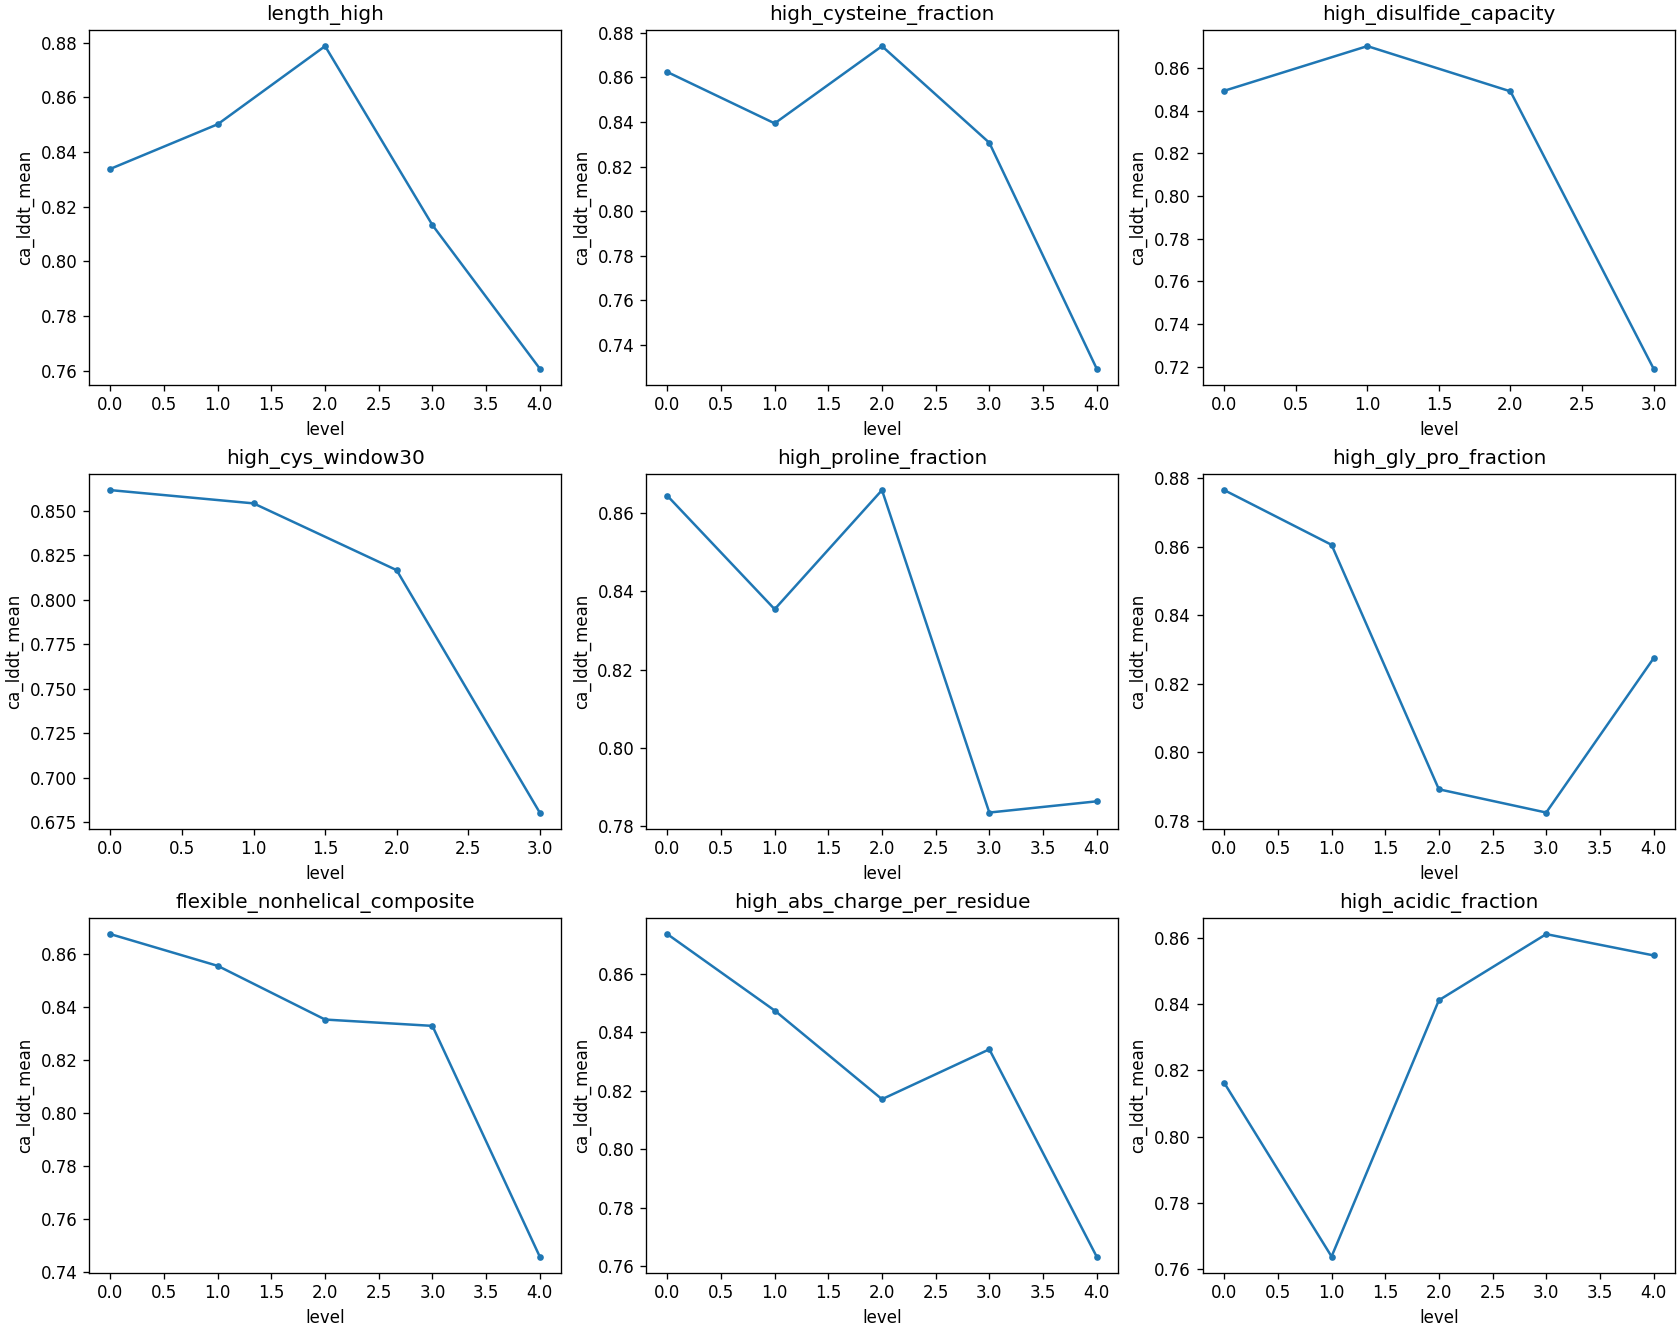

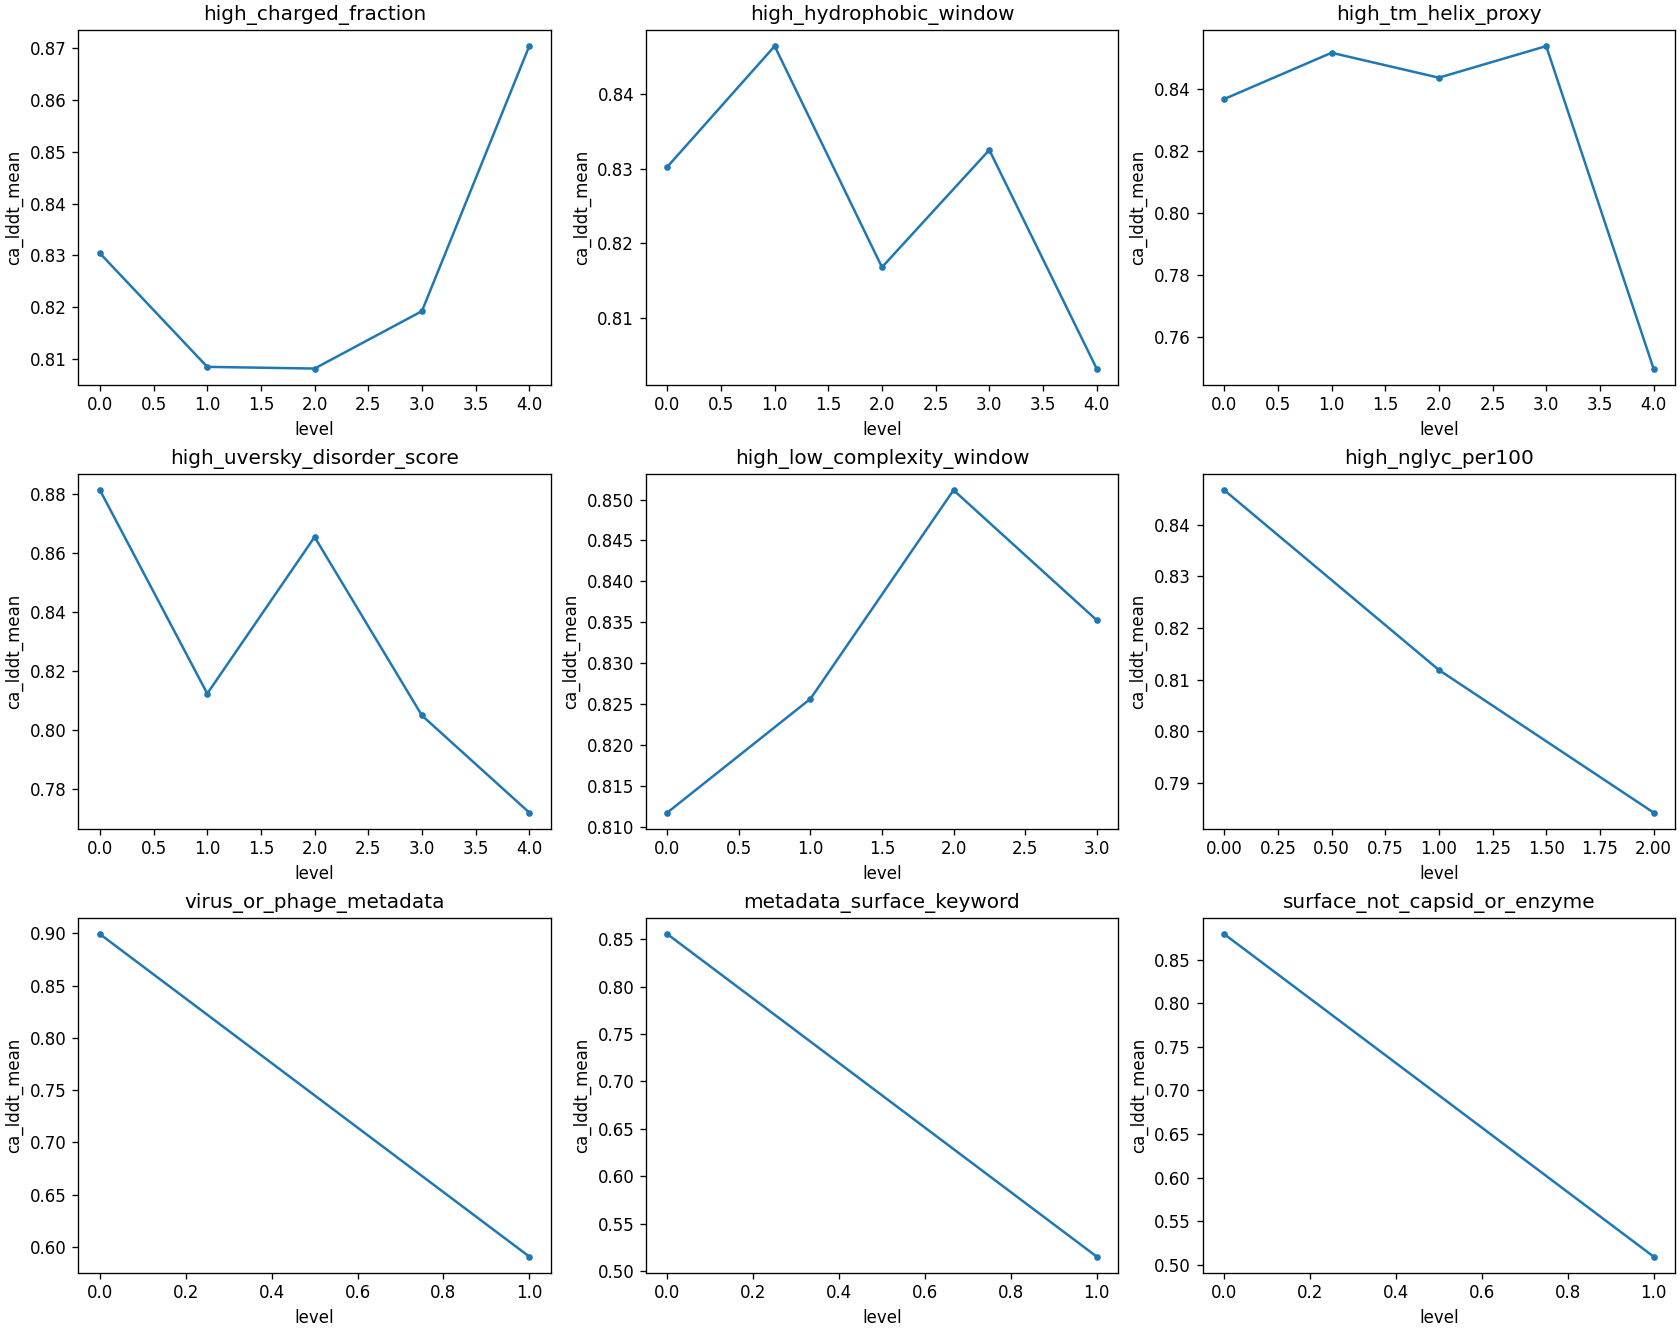

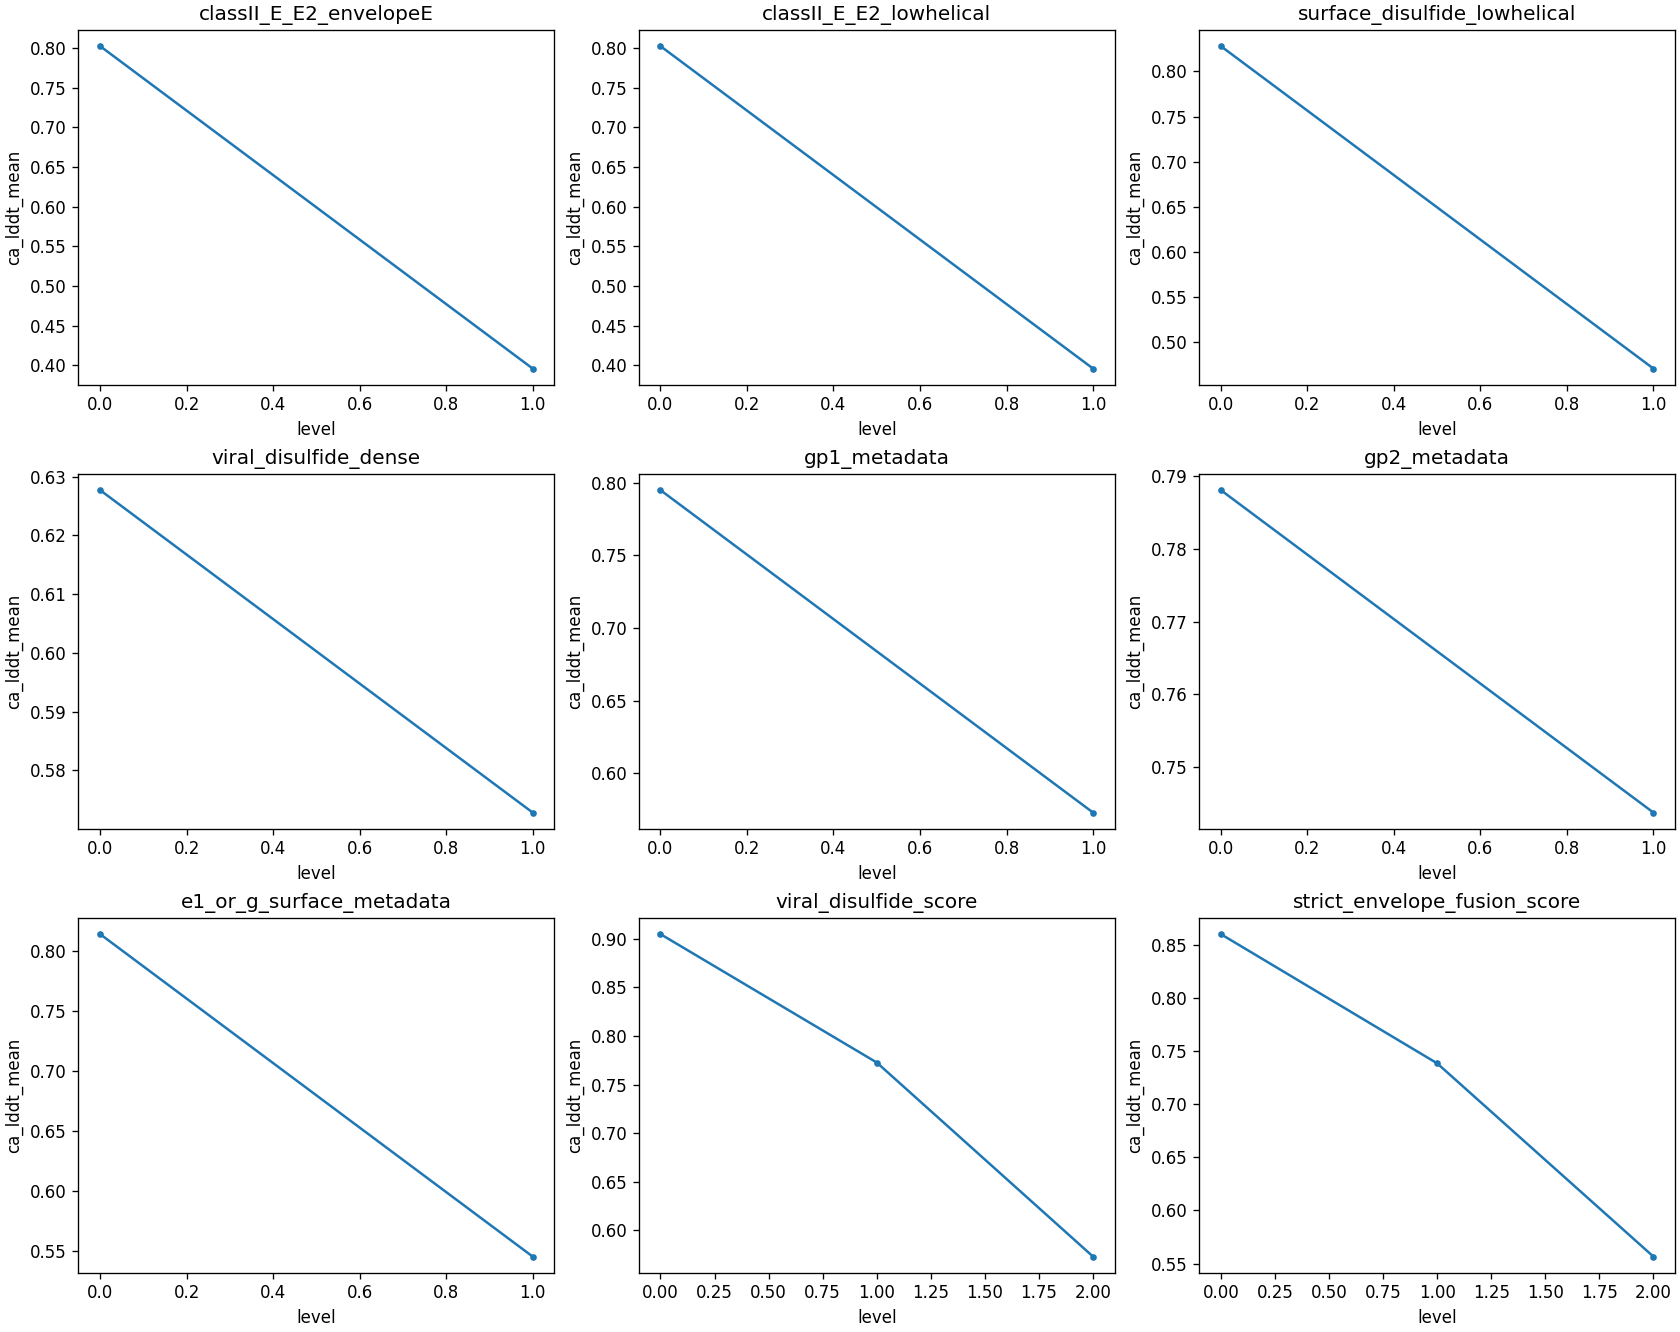

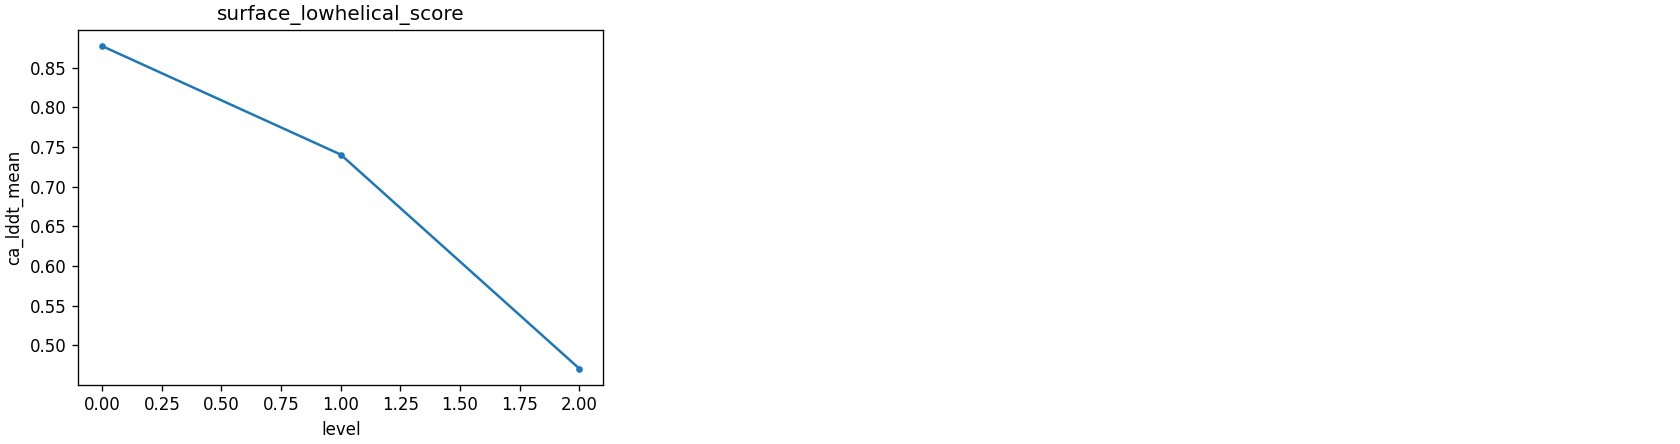

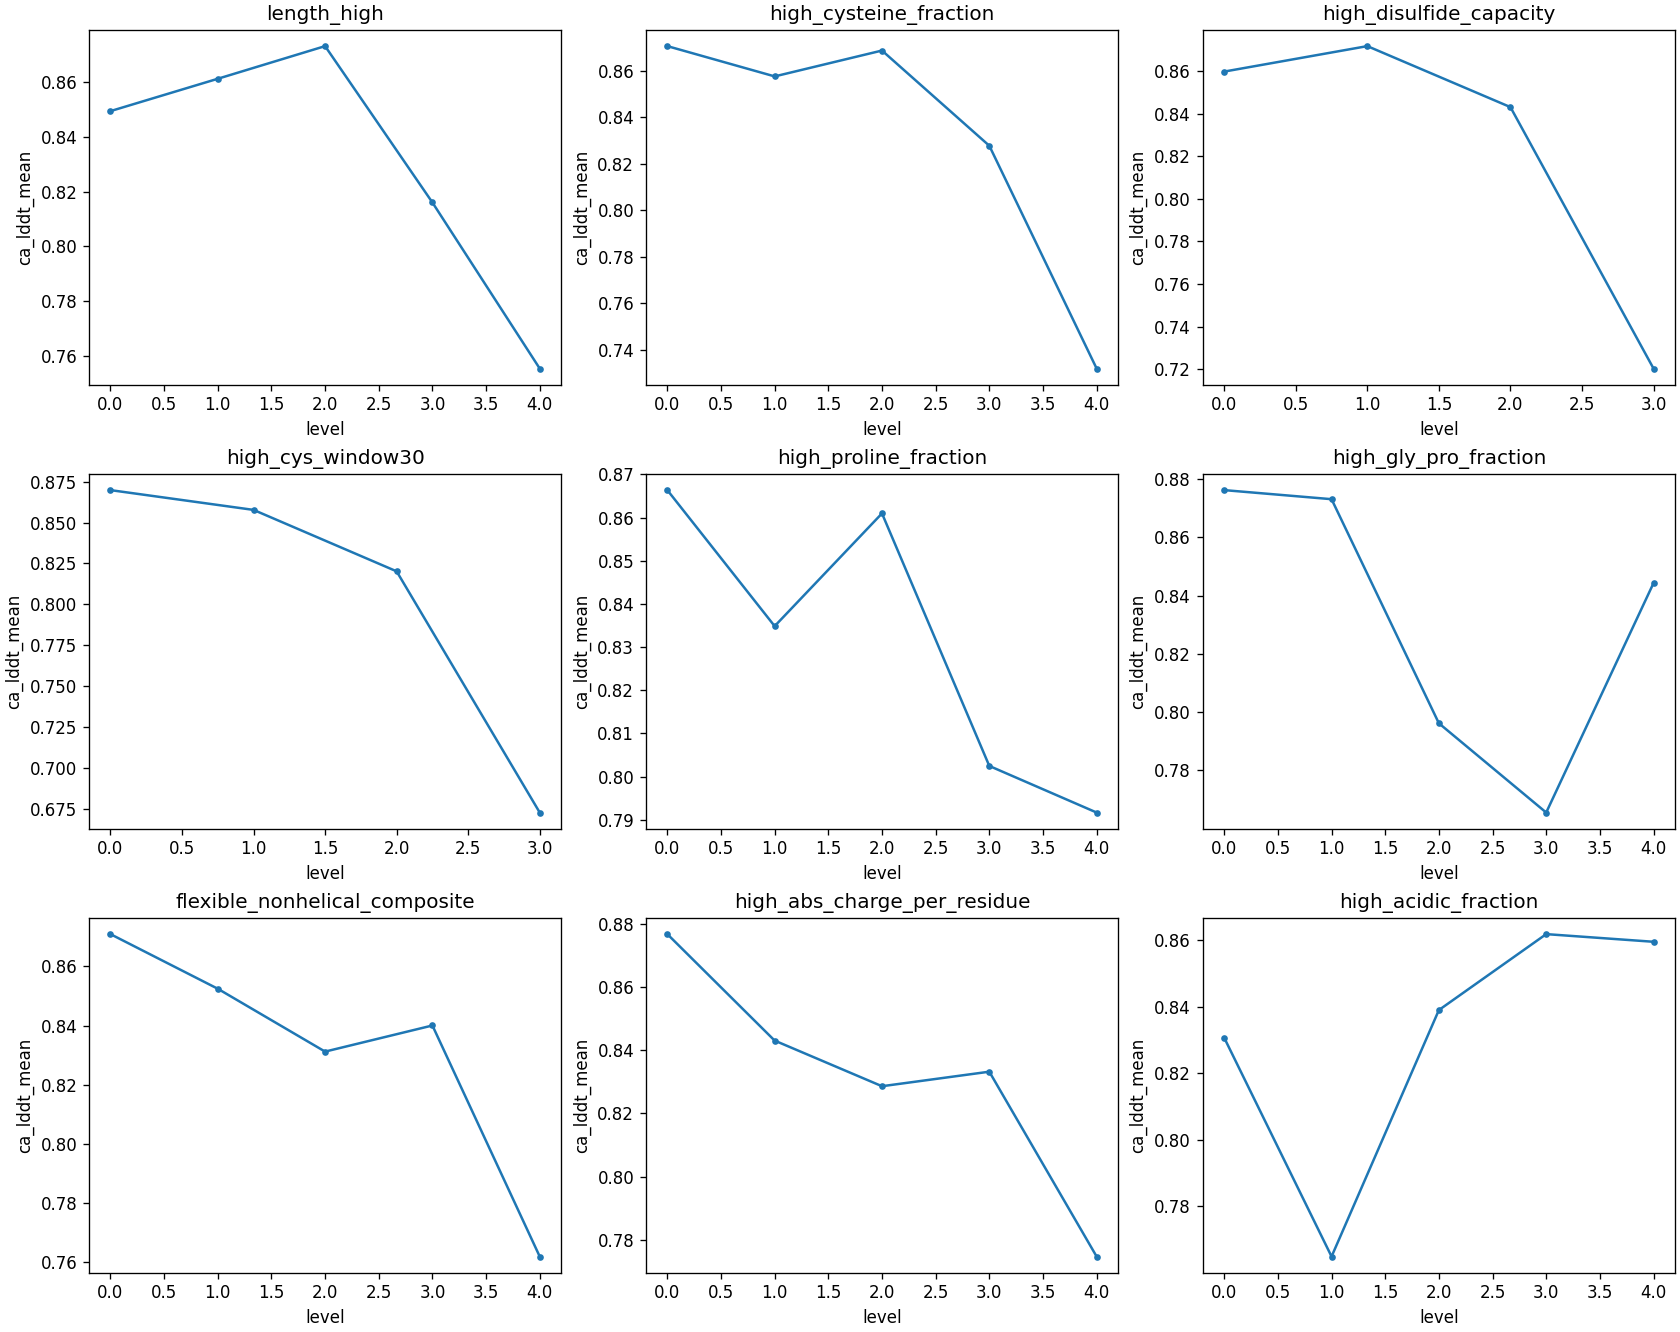

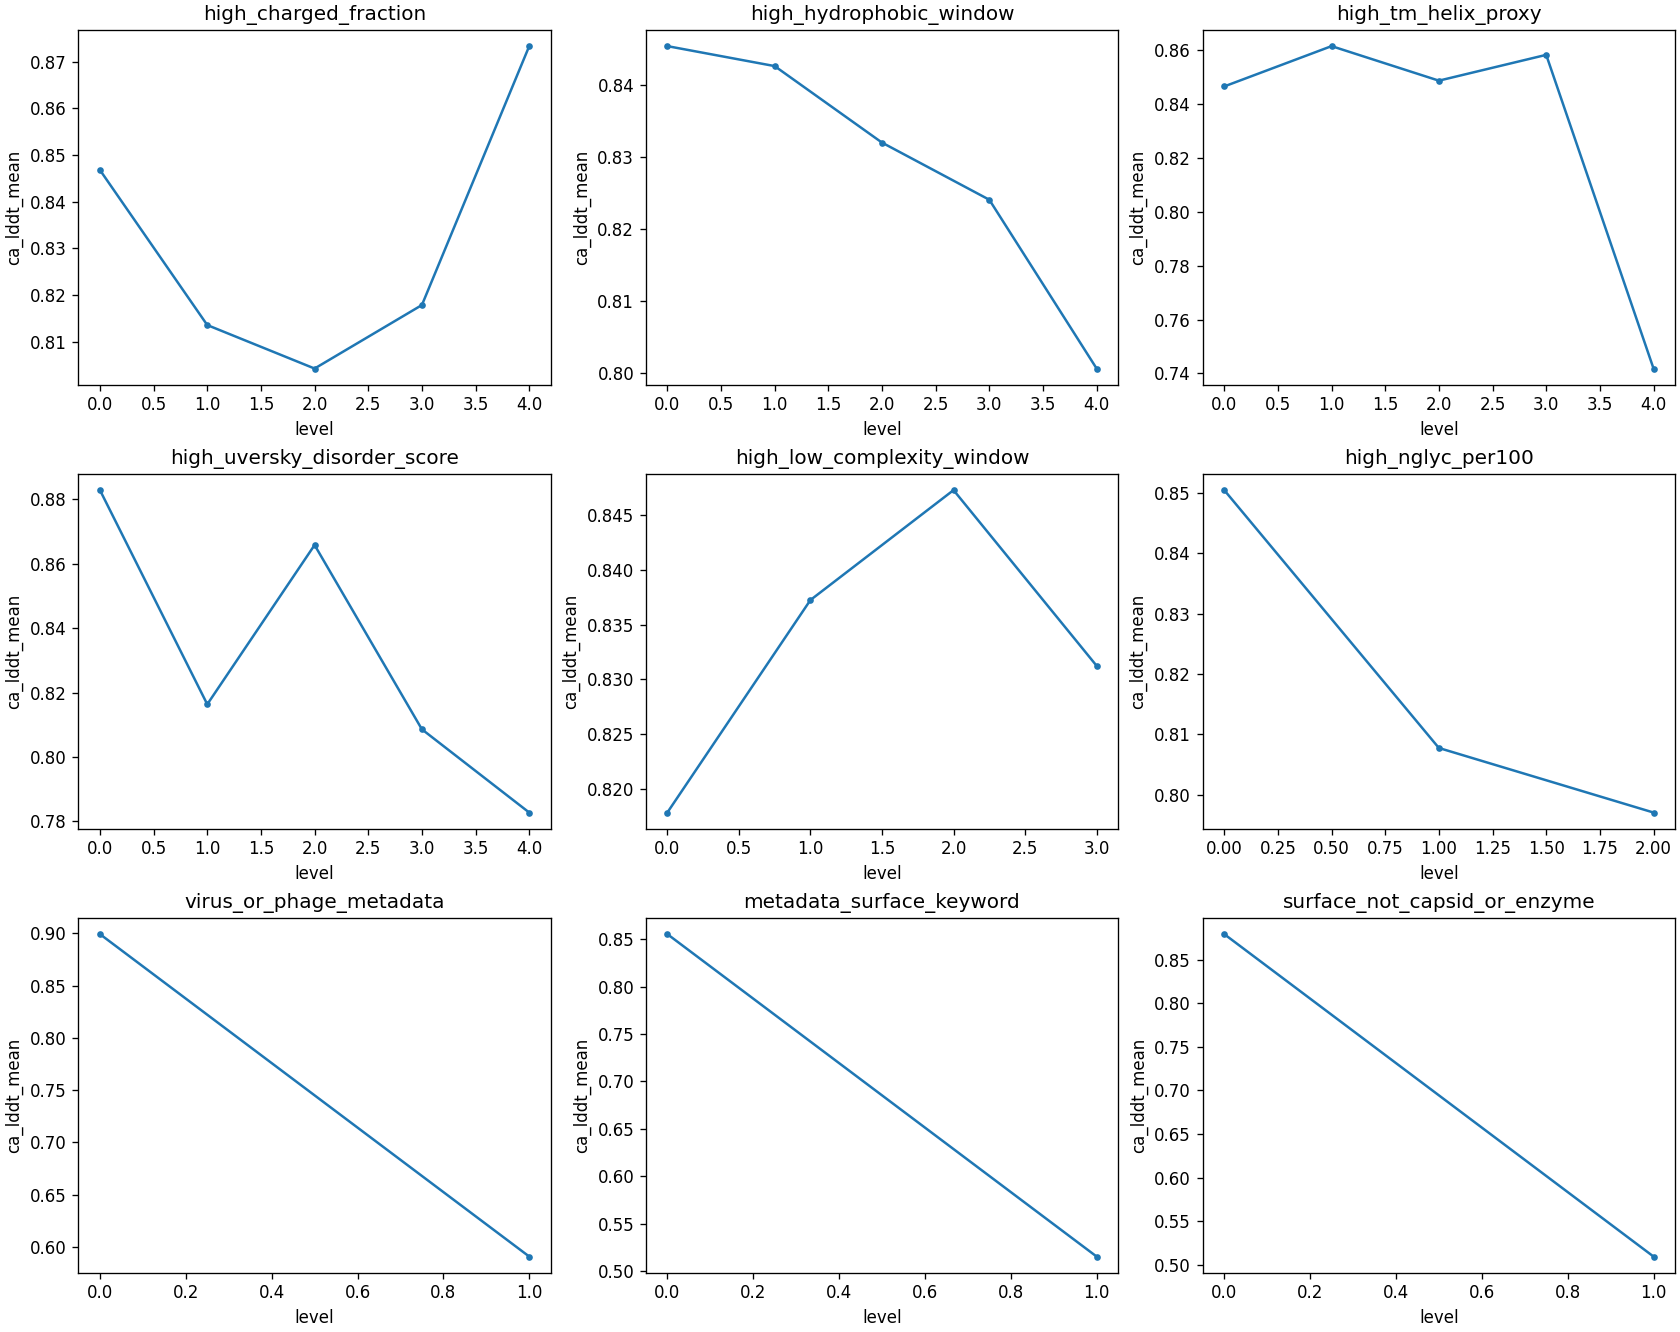

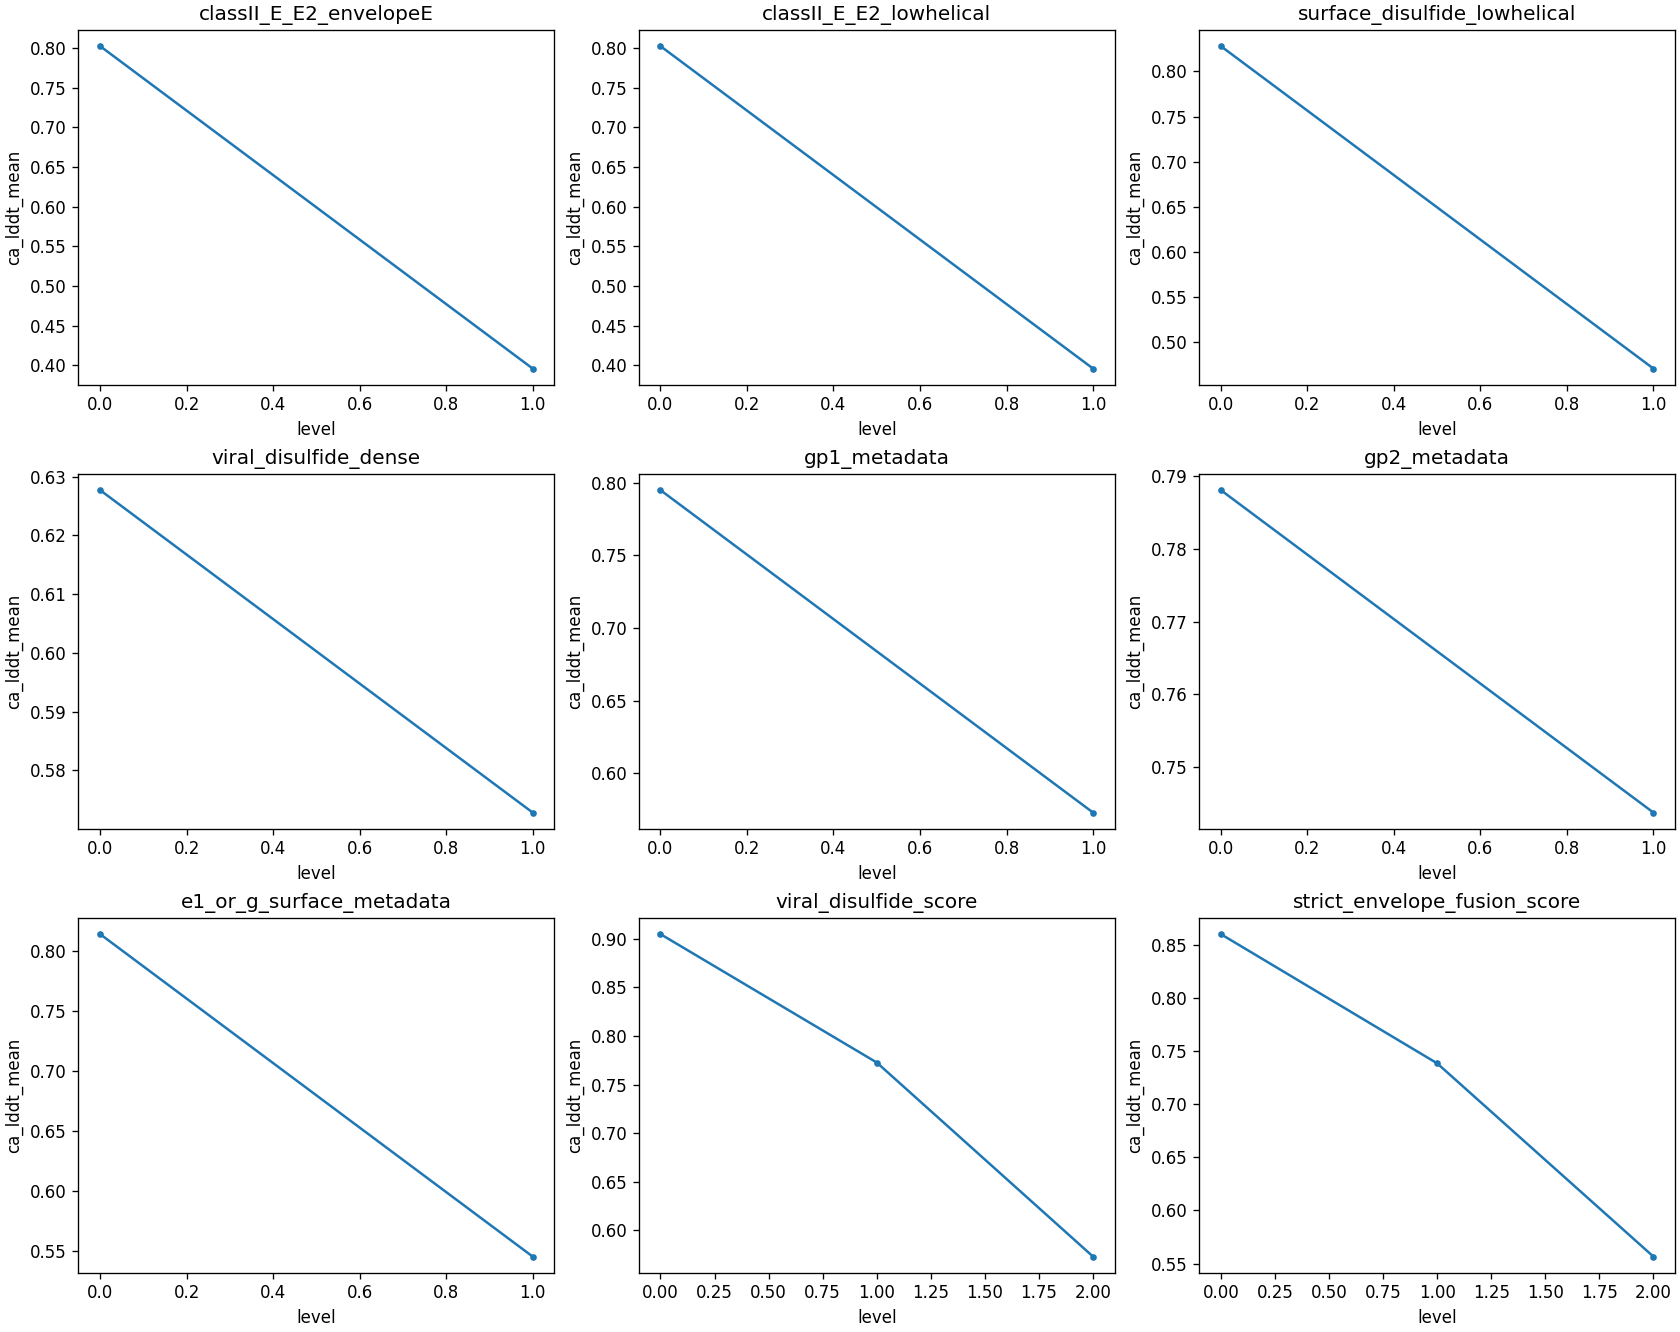

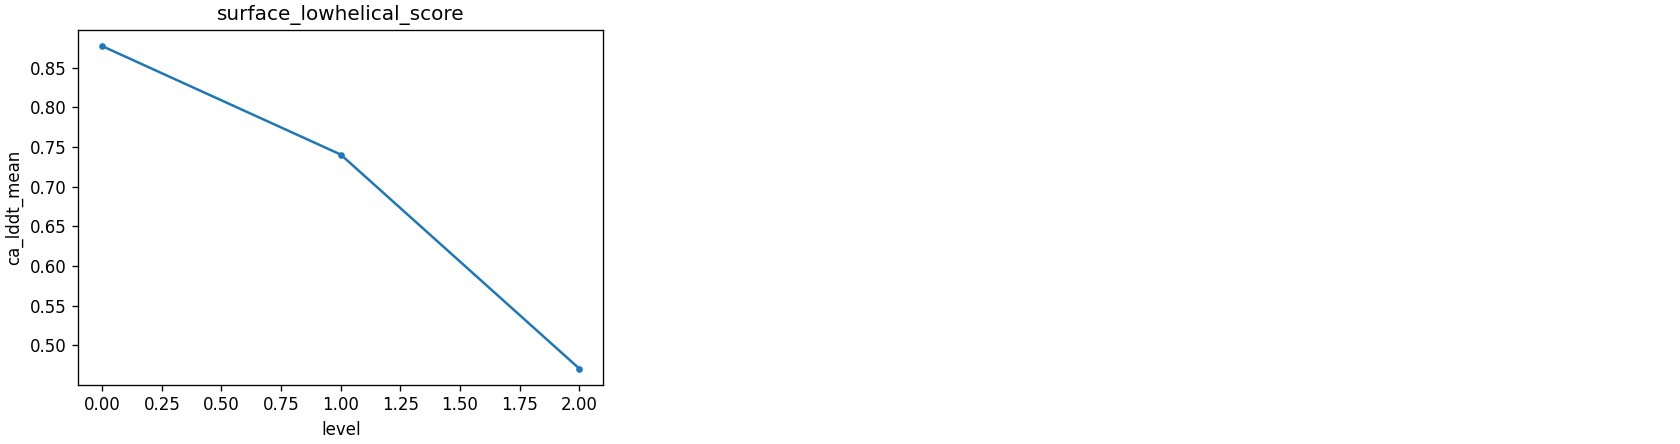

In [24]:
def draw_calculated_curves(frame,title):
    level=next((c for c in ['axis_level','level','stress_rank','external_axis_level','charge_level','acidic_window_level','cys_level','viral_disulfide_score','envelope_fusion_score','surface_lowhelical_score','quartile'] if c in frame),None)
    metric=next((c for c in ['ca_lddt_mean','target_ca_lddt_mean','mean_ca_lddt','ca_lddt'] if c in frame),None)
    if level is None or metric is None:return
    axis=next((c for c in ['axis_id','axis_name','axis','feature'] if c in frame),None)
    frame=frame.copy();frame['_feature']=frame[axis].astype(str) if axis else title
    for start in range(0,frame['_feature'].nunique(),9):
        names=frame['_feature'].unique()[start:start+9]
        fig,axes=plt.subplots((len(names)+2)//3,3,figsize=(14,3.7*((len(names)+2)//3)),squeeze=False,layout='constrained')
        for ax,name in zip(axes.flat,names):
            sub=frame[frame['_feature']==name]
            groups=[c for c in ['subset','source','selection','selection_policy','direction','inference_setting'] if c in sub]
            for key,part in (sub.groupby(groups,dropna=False,sort=False) if groups else [('all',sub)]):
                part=part.sort_values(level)
                ax.plot(part[level],part[metric],marker='o',markersize=3,label=str(key))
            ax.set(title=str(name),xlabel=level,ylabel=metric)
            if groups:ax.legend(fontsize=5)
        for ax in list(axes.flat)[len(names):]:ax.axis('off')
        buffer=io.BytesIO();fig.savefig(buffer,format='png',dpi=120);plt.close(fig);display(Image(data=buffer.getvalue()))
for name,frame in calculated_tables.items():
    if 'curve' in name:draw_calculated_curves(frame,name)


## 6. What the agent decided, and why

The decision below is calculated from the available level curves. A decline is identified only when increasing stress lowers the level mean; uncertainty and adjusted controls above determine how strongly that direction is supported.


In [25]:
# Report decisions from the statistics just calculated above.
decision_rows=[]
for filename,frame in calculated_tables.items():
    if 'curve' not in filename:continue
    level=next((c for c in ['axis_level','level','stress_rank','external_axis_level','charge_level','acidic_window_level','cys_level','quartile'] if c in frame),None)
    metric=next((c for c in ['ca_lddt_mean','target_ca_lddt_mean','mean_ca_lddt','ca_lddt'] if c in frame),None)
    if level is None or metric is None:continue
    groups=[c for c in ['axis','axis_id','axis_name','feature','subset','source','selection','direction'] if c in frame]
    for key,part in (frame.groupby(groups,dropna=False,sort=False) if groups else [('all',frame)]):
        part=part.dropna(subset=[metric,level]).sort_values(level)
        if len(part)<2:continue
        contrast=float(part.iloc[-1][metric]-part.iloc[0][metric])
        decision_rows.append({'curve':filename,'group':str(key),'last_minus_first':contrast,'direction':'lower accuracy at higher stress' if contrast<0 else 'no endpoint decline','strictly_decreasing_level_means':bool(np.all(np.diff(part[metric])<0))})
decision_table=pd.DataFrame(decision_rows)
display(decision_table)
if decision_table.empty:raise RuntimeError('No calculated curve available for interpretation')
for filename,frame in calculated_tables.items():
    status_columns=[c for c in ['decision','status','screen_decision'] if c in frame]
    if status_columns:
        identifiers=[c for c in ['axis','axis_id','feature','source','subset'] if c in frame]
        values=[c for c in frame if any(key in c for key in ['effect','coef','ci_low','ci_high'])]
        display(Markdown('**Calculated screen decisions: '+filename+'**'))
        display(frame[identifiers+status_columns+values])
confirmation_names={3:'flexible107',4:'charge97',5:'acidic78',6:'cysteine95'}
if AXIS_NUMBER in confirmation_names:
    name=confirmation_names[AXIS_NUMBER]
    effects=json.loads(Path(analysis_result['artifacts'][name+'_effects.json']).read_text())
    primary=next(x for x in effects if x.get('selection',x.get('selection_policy'))=='best_by_ptm')
    estimate=float(primary['top_minus_lower_ca_lddt'])
    interval=primary.get('bootstrap_top_minus_lower_ca_lddt') or {}
    upper=interval.get('ci_high',np.nan)
    adjustments={k:v for k,v in primary.items() if 'adjust' in k and isinstance(v,dict)}
    coefficients=[v.get('axis_coef',v.get('coef',np.nan)) for v in adjustments.values()]
    available=[float(x) for x in coefficients if x is not None and np.isfinite(x)]
    supported=estimate<0 and upper is not None and np.isfinite(upper) and upper<0 and bool(available) and all(x<0 for x in available)
    decision='retain this cohort-specific decline' if supported else 'reject a supported general decline on this axis'
    print(f'Decision: {decision}. Top-minus-lower CA-lDDT={estimate:+.4f}; bootstrap interval={interval}; adjusted coefficients={available}.')
    print('The sample-selection controls and source-specific curves above delimit this conclusion; an oracle selection is diagnostic and is never the primary decision.')
else:
    print('Decision: retain only the specific supported subsets identified by the calculated screen decisions above. A pooled endpoint decline alone does not establish a general failure across settings or biological contexts; source-specific curves, intervals, baseline movement, and adjusted controls delimit each finding.')
output_dir=CALC_ROOT/'analysis'/f'axis-{AXIS_NUMBER:02}'
decision_table.to_csv(output_dir/'calculated_decision.csv',index=False)
execution_record={'analysis_id':f'esmfold2-featured/test-{AXIS_NUMBER:02}','axis':AXIS_NUMBER,'status':'completed','source_package_sha256':package['archive_sha256'],'feature_files':feature_receipt['panels'],'analysis_artifacts':analysis_result['artifacts'],'released_model_scores_used':True,'new_model_inference_executed':False,'custom_code':'inline notebook cells'}
(output_dir/'CALCULATION_RECEIPT.json').write_text(json.dumps(execution_record,indent=2,default=str))


,curve,group,last_minus_first,direction,strictly_decreasing_level_means
0,all_evaluations_curves.csv,"('length_high',)",-0.073033,lower accuracy at higher stress,False
1,all_evaluations_curves.csv,"('high_cysteine_fraction',)",-0.133114,lower accuracy at higher stress,False
2,all_evaluations_curves.csv,"('high_disulfide_capacity',)",-0.130208,lower accuracy at higher stress,False
3,all_evaluations_curves.csv,"('high_cys_window30',)",-0.181188,lower accuracy at higher stress,True
4,all_evaluations_curves.csv,"('high_proline_fraction',)",-0.078091,lower accuracy at higher stress,False
5,all_evaluations_curves.csv,"('high_gly_pro_fraction',)",-0.049116,lower accuracy at higher stress,False
6,all_evaluations_curves.csv,"('flexible_nonhelical_composite',)",-0.121605,lower accuracy at higher stress,True
7,all_evaluations_curves.csv,"('high_abs_charge_per_residue',)",-0.110149,lower accuracy at higher stress,False
8,all_evaluations_curves.csv,"('high_acidic_fraction',)",0.038556,no endpoint decline,False
9,all_evaluations_curves.csv,"('high_charged_fraction',)",0.039946,no endpoint decline,False


**Calculated screen decisions: all_evaluations_effects.csv**

,axis,status,ci_low,ci_high
0,length_high,evaluated,-0.137183,-0.055564
1,high_cysteine_fraction,evaluated,-0.161772,-0.081511
2,high_disulfide_capacity,evaluated,-0.173357,-0.095743
3,high_cys_window30,evaluated,-0.133351,-0.068695
4,high_proline_fraction,evaluated,-0.090711,-0.010803
5,high_gly_pro_fraction,evaluated,-0.041264,0.036542
6,flexible_nonhelical_composite,evaluated,-0.142552,-0.058449
7,high_abs_charge_per_residue,evaluated,-0.115566,-0.037479
8,high_acidic_fraction,evaluated,0.002787,0.066716
9,high_charged_fraction,evaluated,0.027258,0.081608


**Calculated screen decisions: primary_sequence_effects.csv**

,axis,status,ci_low,ci_high
0,length_high,evaluated,-0.148800,-0.067344
1,high_cysteine_fraction,evaluated,-0.168217,-0.082080
2,high_disulfide_capacity,evaluated,-0.190164,-0.106125
3,high_cys_window30,evaluated,-0.142705,-0.076789
4,high_proline_fraction,evaluated,-0.090737,-0.008218
5,high_gly_pro_fraction,evaluated,-0.024197,0.052433
6,flexible_nonhelical_composite,evaluated,-0.130795,-0.044475
7,high_abs_charge_per_residue,evaluated,-0.114025,-0.031163
8,high_acidic_fraction,evaluated,0.002664,0.066250
9,high_charged_fraction,evaluated,0.024783,0.079693


Decision: retain only the specific supported subsets identified by the calculated screen decisions above. A pooled endpoint decline alone does not establish a general failure across settings or biological contexts; source-specific curves, intervals, baseline movement, and adjusted controls delimit each finding.


24657